# The collapse-boundary campaigns on one $(K, \alpha, r)$ frame — `krungs-25`, `band-117`, `focus-20`

Three student-HP campaigns were placed against the **collapse-boundary law**

$$K \;=\; \mathrm{lr}\cdot\alpha^{b}\cdot r^{c},\qquad b=0.561,\; c=-0.085,$$

which says an ep20 student collapses (loses the trait outright) once $K$ crosses a threshold
$K^\ast$. All three distil the *same* teacher pool into cross-init student bases at ep20,
student seed 1, and differ only in **which cells of the $K$ surface they place**:

| campaign | cells | teachers | $K/K^\ast$ span | what it was for |
|---|---|---|---|---|
| `krungs-25` | 25 | top-20 | 0.29 – 1.41 | existence/peak arm: rungs straddling the boundary, two contrasting $(\alpha, r)$ realizations per rung (waves 1–2) |
| `krungs-w3` | 4 | top-20 | 0.62 – 0.93 | the low-$\alpha$ high-rank wave-3 extension, run on the `data-seed1` / `weight-seed1` arms only |
| `band-117` | 117 | top-5 | 0.46 – 1.29 | the dense reference design inside the pooled band, every $(\alpha, r)$ combination represented |
| `focus-20` | 20 | top-20 | 0.65 – 0.95 | the 20 shared cells (a design-only subset of `band-117`) that replace the dense band for new arms |

`focus-20` $\subset$ `band-117`; `krungs-25` is disjoint from both; the four `krungs-w3` cells
share exactly one coordinate with `band-117` (`ep20_lr3e-4_r32a4`), which is checked in §0b.

**What this notebook draws.** One heat-grid per **lineage** — a lineage being one
(animal, teacher-numbers base $\to$ student base) pair, e.g. `dog | pythia-160m → data-seed1`
kept separate from `dog | pythia-160m → data-seed2`, because the collapse threshold is
arm-specific. Inside a lineage the three campaigns are **merged** and re-cut onto the frame the
law is written in:

- **y axis** — $K/K^\ast$, binned (the campaigns do not share exact $K$ rungs, so raw $K$ would be
  ~90 near-empty rows);
- **x axis** — LoRA $\alpha$;
- **panel** — LoRA rank $r$;
- **cell value** — the **mean over teachers** (and over any co-binned design cells) of test
  $p(\text{target})$, with the contributing count printed under it.

If the law holds in an arm, every panel splits into a live band below the dashed
$K/K^\ast = 1$ line and a dead band above it, at the *same height* regardless of how $\alpha$ and
$r$ were traded off to get there.

## 0. Setup

In [1]:
from __future__ import annotations

import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from subliminal_learning.analysis import collapse_law as cl
from subliminal_learning.analysis import plots as aplots
from subliminal_learning.analysis.frames import parse_param_tag
from subliminal_learning.analysis.setup import bootstrap, set_plot_style

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
set_plot_style(dpi=115, hide_spines=True)
ROOT, OUTPUT_ROOT = bootstrap()

# --- the law, as the campaigns were PLACED with it (fit by the law-* campaign) --------------
B_LAW, C_LAW = 0.561, -0.085
KSTAR = 7.870e-4          # pooled anchor of the band/focus designs
KSTAR_KRUNGS = 7.84e-4    # the krungs rungs were placed against this; 0.4% apart, far inside one bin
DEAD = 0.005              # per-run collapse cut on test p_target (re-checked in §4)
P_VMAX = 0.2              # house colour scale for mean test p, shared by every figure here

# --- what the campaigns are made of --------------------------------------------------------
TEACHER_BASE = "pythia-160m"          # numbers base every campaign distils from
DATASET = "ex10-20_prefix_n100k"      # the number-pool tag all three campaigns use
STUDENT_SEED = 1                      # every campaign job is student seed 1

BIN_W = 0.05                          # K/K* bin width for the y axis
EDGES = np.round(np.arange(0.25, 1.50 + 1e-9, BIN_W), 2)
BIN_LABELS = [f"{lo:.2f}-{lo + BIN_W:.2f}" for lo in EDGES[:-1]]


def K_of(tag: str) -> float:
    """Design-time K of a student cell tag, from the pre-registered exponents."""
    f = parse_param_tag(tag)
    return f["lr"] * f["alpha"] ** B_LAW * f["rank"] ** C_LAW


def k_bin(k_rel) -> np.ndarray:
    """Bin K/K* onto the shared `BIN_LABELS` ladder (left-closed bins)."""
    return pd.cut(pd.Series(np.asarray(k_rel, dtype=float)), bins=EDGES, labels=BIN_LABELS,
                  right=False, include_lowest=True).astype(str).values

### 0b. The cell designs

The krungs waves are **frozen inline** (copied from `top20_krungs_ds1.ipynb`, so this notebook
survives the queue tree disappearing). `band-117` is read back from the realized job list of the
`top5-bandext-ds2ws2` queue — the campaign's own record of which 117 cells were actually placed,
which is the authority here rather than any regenerated design — and `focus-20` from the design
file its queues were generated with. Both reads are asserted against their known sizes and
against the relations between the designs, so a moved or rewritten file fails loudly here rather
than silently changing a figure.

In [2]:
# krungs: wave 1 (16 pre-registered) + wave 2 (9 rank extension) -- the 25 cells every arm of
# the campaign ran -- and wave 3 (4 low-alpha high-rank cells), which exists on the ds1/ws1 arms
# only and is therefore carried as its own design set rather than folded into the 25.
KRUNGS25_CELLS = [
    "ep20_lr8e-5_r4a8", "ep20_lr2e-4_r8a2", "ep20_lr3e-4_r4a2", "ep20_lr5e-5_r16a64",
    "ep20_lr4e-4_r8a2", "ep20_lr8e-5_r4a32", "ep20_lr1e-4_r8a32", "ep20_lr8e-5_r16a64",
    "ep20_lr5e-4_r4a2", "ep20_lr8e-5_r8a64", "ep20_lr4e-4_r8a4", "ep20_lr8e-5_r4a64",
    "ep20_lr1e-4_r4a64", "ep20_lr8e-4_r16a2", "ep20_lr8e-4_r4a2", "ep20_lr2e-4_r16a32",
    "ep20_lr8e-5_r64a16", "ep20_lr8e-5_r32a32", "ep20_lr1e-4_r64a32", "ep20_lr8e-5_r32a64",
    "ep20_lr1e-4_r64a64", "ep20_lr1e-4_r16a64", "ep20_lr8e-4_r64a2", "ep20_lr4e-4_r64a8",
    "ep20_lr3e-4_r32a16",
]
KRUNGS_W3_CELLS = [
    "ep20_lr3e-4_r32a4", "ep20_lr2.1e-4_r32a8", "ep20_lr2.2e-4_r64a8", "ep20_lr3.2e-4_r64a8",
]
BAND_CELLS = sorted({
    json.loads(ln)["key"].split("|")[2] for ln in
    (ROOT / "run_logs/queue_angela/top5-bandext-ds2ws2-n1/jobs.jsonl").read_text().splitlines()
})
FOCUS_DOC = json.loads((ROOT / "run_logs/focus20_cells.json").read_text())
FOCUS_CELLS = [c["student_tag"] for c in FOCUS_DOC["cells"]]

assert len(BAND_CELLS) == 117 and len(FOCUS_CELLS) == 20, "design files changed shape"
assert set(FOCUS_CELLS) <= set(BAND_CELLS), "focus-20 is supposed to be a subset of band-117"
assert not (set(KRUNGS25_CELLS) & set(BAND_CELLS)), "krungs 25 was supposed to miss the band"
SHARED = set(KRUNGS_W3_CELLS) & set(BAND_CELLS)
assert SHARED == {"ep20_lr3e-4_r32a4"}, f"unexpected krungs-w3 / band overlap: {SHARED}"

# The four design sets, kept separate: they are what each campaign's coverage is measured
# against, and two of them genuinely overlap.
CAMPAIGNS = ["krungs-25", "krungs-w3", "focus-20", "band-117"]
CAMPAIGN_CELLS = {"krungs-25": KRUNGS25_CELLS, "krungs-w3": KRUNGS_W3_CELLS,
                  "focus-20": FOCUS_CELLS, "band-117": BAND_CELLS}
CAMPAIGN_SHORT = {"krungs-25": "k25", "krungs-w3": "kw3", "focus-20": "foc", "band-117": "band"}

# One DISPLAY label per cell, for colours and per-figure breakdowns -- NOT for coverage, which
# uses the overlapping design sets above. Priority is smallest/most-current design first: a cell
# of the focus-20 reduction reads focus-20 rather than band-117, the one coordinate krungs wave 3
# shares with the band reads band-117, and the krungs labels are what is left over.
DISPLAY_PRIORITY = ["focus-20", "band-117", "krungs-25", "krungs-w3"]
CELL_CAMPAIGN = {c: camp for camp in reversed(DISPLAY_PRIORITY) for c in CAMPAIGN_CELLS[camp]}
DESIGN_CELLS = sorted(CELL_CAMPAIGN, key=K_of)

# Teacher pools. Both top-20 campaigns use the same manifest order (the distillability ranking
# of the single-seed screen); band-117 uses its first five. cat/lion reuse the dog tags verbatim
# so the arms stay comparable, so one list covers every animal.
TOP20 = json.loads((ROOT / "run_logs/dog_top20krungs_configs.json").read_text())["param_tags"]
TOP5 = TOP20[:5]
CAMPAIGN_TEACHERS = {"krungs-25": TOP20, "krungs-w3": TOP20, "band-117": TOP5, "focus-20": TOP20}

print(f"{len(DESIGN_CELLS)} distinct design cells | "
      + " | ".join(f"{c} {len(CAMPAIGN_CELLS[c])}" for c in CAMPAIGNS))
print(f"shared coordinate(s) between designs: {sorted(SHARED)} "
      f"(display priority {' > '.join(DISPLAY_PRIORITY)} -> labelled band-117 below)")
print(f"teachers: top-20 pool, band-117 restricted to its first {len(TOP5)}")

145 distinct design cells | krungs-25 25 | krungs-w3 4 | focus-20 20 | band-117 117
shared coordinate(s) between designs: ['ep20_lr3e-4_r32a4'] (display priority focus-20 > band-117 > krungs-25 > krungs-w3 -> labelled band-117 below)
teachers: top-20 pool, band-117 restricted to its first 5


## 1. The design itself — where the three campaigns put their cells

One row per design cell, before any results are read. This is the grid every figure below is
drawn on, so its gaps are design gaps, not missing runs.

In [3]:
design = pd.DataFrame({"student_tag": DESIGN_CELLS})
for k in ("lr", "rank", "alpha"):
    design[k] = [parse_param_tag(t)[k] for t in DESIGN_CELLS]
design["campaign"] = design.student_tag.map(CELL_CAMPAIGN)
design["K"] = design.student_tag.map(K_of)
design["K_rel"] = design.K / KSTAR
design["K_bin"] = k_bin(design.K_rel)

# Shared axis orders. The K rows are the bins the DESIGN occupies (so every lineage figure has
# the same rows and they line up across animals/arms); alpha and rank are the full design range.
K_ORDER = [b for b in BIN_LABELS if b in set(design.K_bin)]
ALPHA_ORDER = sorted(design.alpha.unique())
RANK_ORDER = sorted(design["rank"].unique())
ORDERS = {"K_bin": K_ORDER, "alpha": ALPHA_ORDER, "rank": RANK_ORDER}
# Row index of the first bin at/above K/K* = 1 -- the boundary line on every panel.
BOUNDARY_ROW = next(i for i, b in enumerate(K_ORDER) if float(b.split("-")[0]) >= 1.0)

# Row unit: one design cell, grouped by its DISPLAY label -- so `cells` is the cells a campaign
# owns exclusively under the priority above (`design_cells` is its true, overlapping size).
summary = (design.groupby("campaign")
           .agg(cells=("student_tag", "size"), K_rel_min=("K_rel", "min"),
                K_rel_max=("K_rel", "max"), ranks=("rank", lambda s: sorted(s.unique())),
                alphas=("alpha", lambda s: sorted(s.unique())),
                lrs=("lr", "nunique"))
           .reindex(CAMPAIGNS))
summary.insert(0, "design_cells", [len(CAMPAIGN_CELLS[c]) for c in CAMPAIGNS])
display(summary)
print(f"{len(K_ORDER)} occupied K/K* bins of the {len(BIN_LABELS)}-bin ladder "
      f"(gap 0.35-0.45: krungs' lowest rung sits at 0.29-0.34, the band starts at 0.46)")

,design_cells,cells,K_rel_min,K_rel_max,ranks,alphas,lrs
campaign,,,,,,,
krungs-25,25,25,0.290117,1.403118,"[4, 8, 16, 32, 64]","[2, 4, 8, 16, 32, 64]",8
krungs-w3,4,3,0.630313,0.916819,"[32, 64]",[8],3
focus-20,20,20,0.644672,0.950042,"[4, 8, 16, 32, 64, 128]","[2, 4, 8, 16, 32, 64, 128]",9
band-117,117,97,0.459978,1.289343,"[4, 8, 16, 32, 64, 128]","[2, 4, 8, 16, 32, 64, 128]",14


21 occupied K/K* bins of the 25-bin ladder (gap 0.35-0.45: krungs' lowest rung sits at 0.29-0.34, the band starts at 0.46)


**Design coverage map.** Same axes as every result figure — y = $K/K^\ast$ bin, x = $\alpha$,
panel = rank — but the value is *how many design cells* land in the square, and the colour is
which campaign placed them. Where a square holds cells from more than one design, the **most
current, smallest design wins**: `focus-20` first (the 20 cells new arms actually run), then
`band-117`, then the krungs waves — so the gold squares are exactly the focus-20 design and the
blue ones are the band cells outside it. Read it as the legend for the blank space in §6: a
square empty here can never be filled by any amount of GPU time.

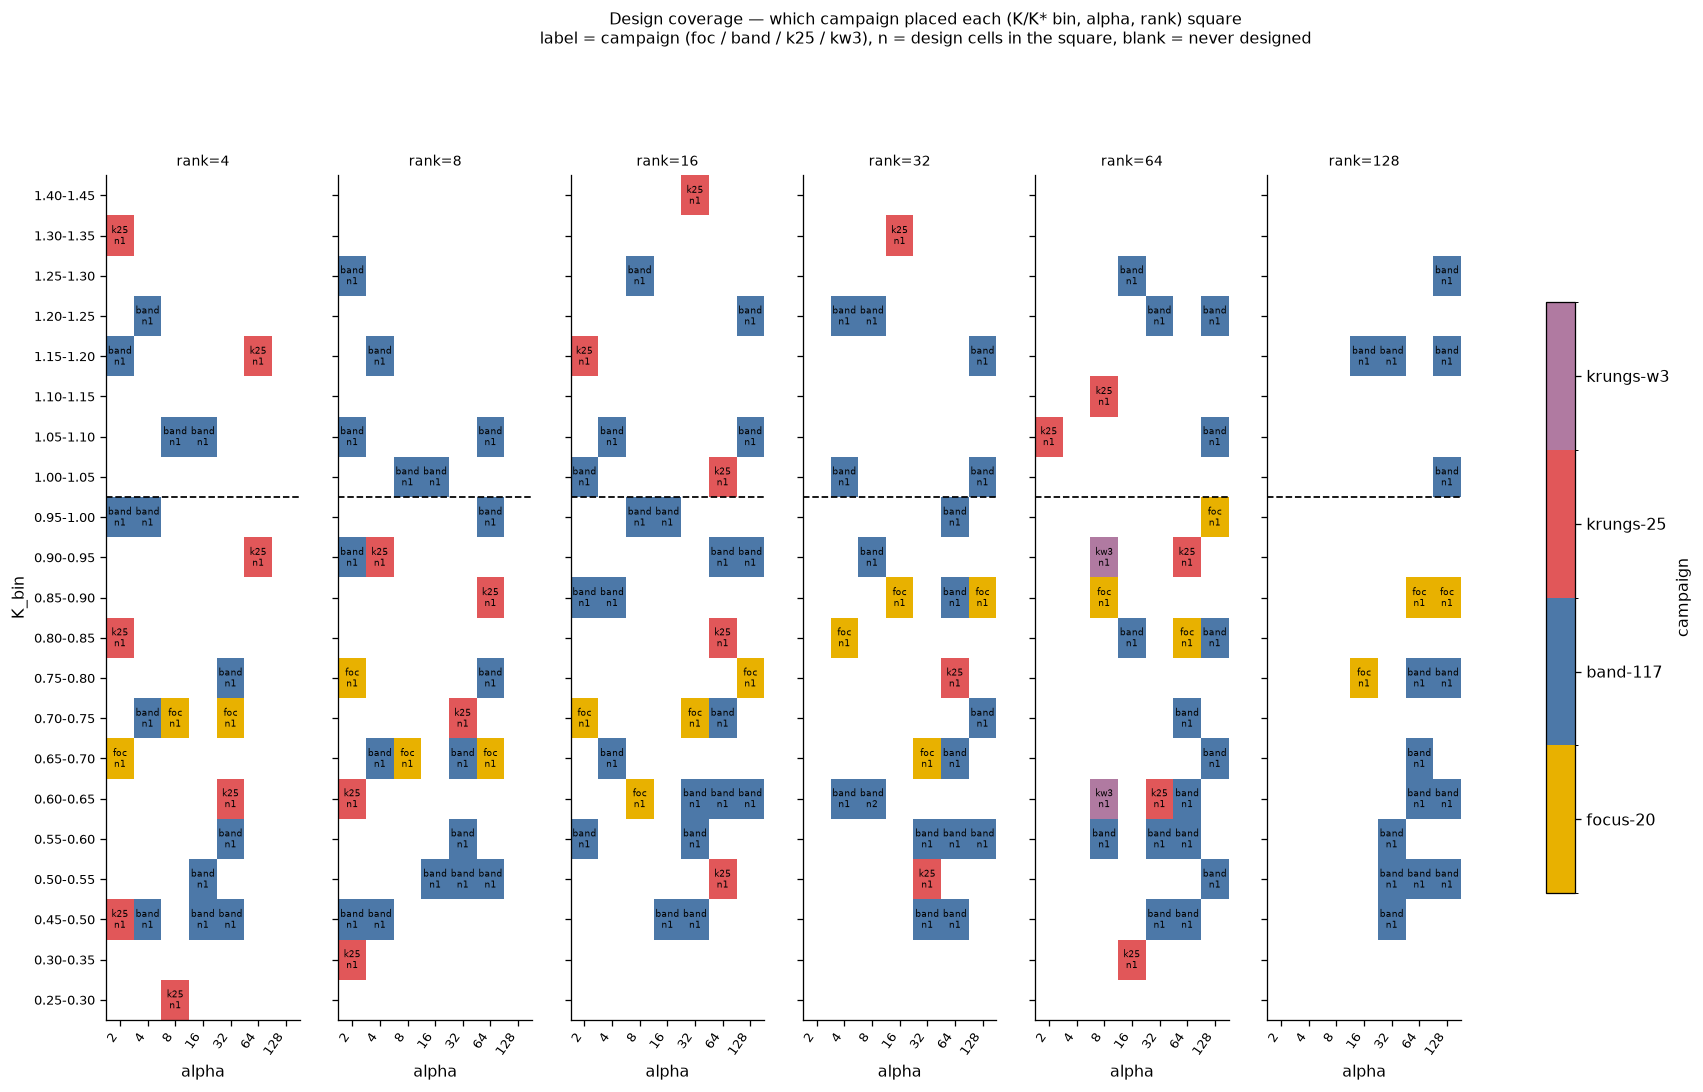

In [4]:
from matplotlib.colors import BoundaryNorm, ListedColormap

# Codes follow DISPLAY_PRIORITY, so the square-level `min` below resolves a mixed square the
# same way the cell-level label does: focus-20 first, then band-117, then the krungs waves.
CAMPAIGN_CODE = {c: i for i, c in enumerate(DISPLAY_PRIORITY)}
CAMPAIGN_COLOR = {"focus-20": "#e8b100", "band-117": "#4c78a8",
                  "krungs-25": "#e15759", "krungs-w3": "#b07aa1"}
CAMPAIGN_CMAP = ListedColormap([CAMPAIGN_COLOR[c] for c in DISPLAY_PRIORITY])
dmap = design.assign(code=design.campaign.map(CAMPAIGN_CODE))
fig = aplots.facet_grid_heatmaps(
    dmap, row="K_bin", col="alpha", val="code", col_facet="rank", agg="min", show_n=True,
    orders=ORDERS, cmap=CAMPAIGN_CMAP,
    norm=BoundaryNorm(np.arange(-0.5, len(DISPLAY_PRIORITY) + 0.5), len(DISPLAY_PRIORITY)),
    cell_fontsize=5.5, fmt=lambda v: CAMPAIGN_SHORT[DISPLAY_PRIORITY[int(v)]],
    text_color="black", panel_w=3.0, row_h=0.34,
    title=("Design coverage — which campaign placed each (K/K* bin, alpha, rank) square\n"
           "label = campaign (foc / band / k25 / kw3), n = design cells in the square, "
           "blank = never designed"),
    cbar_label="campaign")
for i, ax in enumerate(a for a in fig.axes if a.get_label() != "<colorbar>"):
    if i % len(RANK_ORDER):
        ax.set_yticklabels([])
    ax.axhline(BOUNDARY_ROW - 0.5, color="k", ls="--", lw=1.1)
fig.axes[-1].set_yticks(list(CAMPAIGN_CODE.values()))
fig.axes[-1].set_yticklabels(DISPLAY_PRIORITY)
plt.show()

## 2. Loading the results

Every campaign job writes into the same student tree, so the load is one sweep over
`students/{animal}/pythia-160m-{base}/teacher-pythia-160m/{teacher}_tseed1/{dataset}/{cell}`
through the shared campaign loader (`collapse_law.load_law_runs`, which reads each cell's
across-seed `preference_summary.json`).

Three restrictions make the frame *campaign data* rather than *everything that happens to sit at
these coordinates*:

1. **teachers** — only the 20 manifest tags (other teachers have runs at some of these cells from
   the `law-*` grids, which are a different experiment);
2. **cells** — only the 145 design cells above;
3. **seed 1** — every campaign job is student seed 1; extra seeds at the same coordinates come
   from the reseed/law campaigns and would silently re-weight the teacher means. The count of
   dropped extra-seed runs is printed so the exclusion is visible.

In [5]:
arms = [(a.name, b.name) for a in sorted((OUTPUT_ROOT / "students").iterdir()) if a.is_dir()
        for b in sorted(a.iterdir()) if (b / f"teacher-{TEACHER_BASE}").is_dir()]

frames = []
for animal, base in arms:
    _, r = cl.load_law_runs(
        OUTPUT_ROOT, animal=animal, numbers_base=TEACHER_BASE, dataset=DATASET,
        lineages=[(t, t, base) for t in TOP20],
    )
    if not r.empty:
        frames.append(r.assign(animal=animal, student_base=base))

raw = pd.concat(frames, ignore_index=True).rename(columns={"family": "teacher"})
raw = raw[raw.student_tag.isin(CELL_CAMPAIGN)]
n_extra_seed = int((raw.seed != STUDENT_SEED).sum())
runs = raw[raw.seed.eq(STUDENT_SEED)].copy()

runs["campaign"] = runs.student_tag.map(CELL_CAMPAIGN)
runs["tier"] = np.where(runs.teacher.isin(TOP5), "top5", "top6-20")
runs["K"] = runs.student_tag.map(K_of)
runs["K_rel"] = runs.K / KSTAR
runs["K_bin"] = k_bin(runs.K_rel)
runs["dead"] = runs.test.lt(DEAD).astype(int)

# One label per lineage: the teacher's numbers base -> the student base it was distilled into.
def base_label(b: str) -> str:
    return "same-model" if b == TEACHER_BASE else b.replace(f"{TEACHER_BASE}-", "")

runs["lineage"] = (runs.animal + " | " + TEACHER_BASE + " -> " + runs.student_base.map(base_label))
BASE_RANK = {"data-seed1": 0, "weight-seed1": 1, "data-seed2": 2, "weight-seed2": 3,
             "data-seed3": 4, "weight-seed3": 5, "same-model": 6}
ANIMAL_RANK = {"dog": 0, "cat": 1, "lion": 2, "pig": 3, "rabbit": 4}
LINEAGES = sorted(runs.lineage.unique(), key=lambda s: (
    ANIMAL_RANK.get(s.split(" | ")[0], 99), BASE_RANK.get(s.split(" -> ")[1], 99)))
runs["lineage"] = pd.Categorical(runs.lineage, categories=LINEAGES, ordered=True)

print(f"{len(runs)} campaign runs (teacher x cell, seed {STUDENT_SEED}) over {len(LINEAGES)} "
      f"lineages | dropped {n_extra_seed} runs at these coordinates from other seeds")
print(f"teachers present: {runs.teacher.nunique()} of {len(TOP20)} | "
      f"cells present: {runs.student_tag.nunique()} of {len(DESIGN_CELLS)}")

8520 campaign runs (teacher x cell, seed 1) over 14 lineages | dropped 731 runs at these coordinates from other seeds
teachers present: 20 of 20 | cells present: 145 of 145


## 3. Coverage — what has landed, per lineage and campaign

Row unit: one lineage. Columns: evaluated **teacher × cell pairs** per campaign, against that
campaign's own denominator (its cell count × its teacher pool: 20 × 25 for `krungs-25`,
20 × 4 for `krungs-w3`, 5 × 117 for `band-117`, 20 × 20 for `focus-20`). A run is counted under
every design set that contains its cell, so the `focus-20` column double-counts with `band-117`
(the same runs, since `focus-20 ⊂ band-117`) and `krungs-w3` overlaps `band-117` in one cell.
`krungs-w3` was only ever placed on the `data-seed1` / `weight-seed1` arms, so `0/80` elsewhere
is the design, not a gap.

The denominators differ per campaign, so a lineage can be complete on one campaign and empty on
another; the figures in §6 show whatever exists and annotate `n` in every square.

In [6]:
def coverage_table(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for lin, sub in df.groupby("lineage", observed=True):
        rec = {"lineage": lin, "teachers": sub.teacher.nunique(), "cells": sub.student_tag.nunique()}
        for c in CAMPAIGNS:
            cells, pool = CAMPAIGN_CELLS[c], CAMPAIGN_TEACHERS[c]
            denom = len(cells) * len(pool)
            got = int((sub.student_tag.isin(cells) & sub.teacher.isin(pool)).sum())
            rec[c] = f"{got}/{denom}" + (" ✓" if got == denom else "")
        rec["runs"] = len(sub)
        rows.append(rec)
    return pd.DataFrame(rows).set_index("lineage").reindex(LINEAGES).dropna(how="all")

COVER = coverage_table(runs)
display(COVER)

,teachers,cells,krungs-25,krungs-w3,focus-20,band-117,runs
lineage,,,,,,,
dog | pythia-160m -> data-seed1,20,118,500/500 ✓,80/80 ✓,388/400,396/585,1315
dog | pythia-160m -> weight-seed1,20,122,500/500 ✓,80/80 ✓,376/400,426/585,1307
dog | pythia-160m -> data-seed2,20,142,500/500 ✓,5/80,100/400,585/585 ✓,1085
dog | pythia-160m -> weight-seed2,20,142,500/500 ✓,5/80,104/400,585/585 ✓,1093
dog | pythia-160m -> data-seed3,20,142,500/500 ✓,5/80,100/400,585/585 ✓,1085
dog | pythia-160m -> weight-seed3,20,142,500/500 ✓,2/80,26/400,168/585,668
dog | pythia-160m -> same-model,20,4,20/500,0/80,20/400,15/585,80
cat | pythia-160m -> data-seed1,20,117,0/500,3/80,400/400 ✓,391/585,691
cat | pythia-160m -> weight-seed1,20,117,0/500,2/80,400/400 ✓,297/585,597


## 4. The collapse threshold, re-checked on this pooled data

`DEAD = 0.005` is inherited from the generality/krungs notebooks. It is only usable if it sits in
the empty trough of *this* merged population's score distribution. Row unit: one campaign run.

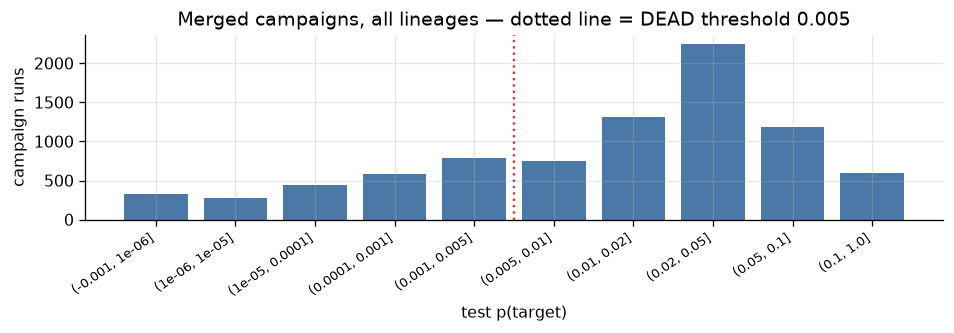

runs in the (1e-3, 5e-3] trough bin: 794 of 8520 | collapsed at 0.005: 2417 (28.4%)


In [7]:
EDGES_P = [0, 1e-6, 1e-5, 1e-4, 1e-3, 5e-3, 1e-2, 2e-2, 5e-2, 1e-1, 1.0]
hist = pd.cut(runs.test, EDGES_P, include_lowest=True).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8.4, 3.0))
ax.bar(range(len(hist)), hist.values, color="#4c78a8")
ax.set_xticks(range(len(hist)))
ax.set_xticklabels([str(i) for i in hist.index], rotation=35, ha="right", fontsize=8)
ax.axvline(hist.index.get_loc(pd.cut([DEAD], EDGES_P)[0]) + 0.5, color="#d03b3b", ls=":", lw=1.5)
ax.set(ylabel="campaign runs", xlabel="test p(target)",
       title=f"Merged campaigns, all lineages — dotted line = DEAD threshold {DEAD}")
fig.tight_layout(); plt.show()
print(f"runs in the (1e-3, 5e-3] trough bin: {int(runs.test.between(1e-3, 5e-3).sum())} "
      f"of {len(runs)} | collapsed at {DEAD}: {int(runs.dead.sum())} ({runs.dead.mean():.1%})")

### 4b. Is that one threshold systematic across lineages?

§4 pools every arm, which can only hide an arm-specific trough. This asks the question properly:
fit a 2-component Gaussian mixture to $\log_{10} p$ **within each lineage** and read off where
that arm's dead and live modes actually sit, then measure how much the arm's boundary moves as
the cut is swept.

Row unit: one lineage (those with ≥ 100 runs). `dead_mode` / `live_mode` are the mixture
components in raw $p$; `sep` is their separation in decades; `b_*` columns are the arm's
empirical boundary — the first $K/K^\ast$ bin whose collapse fraction reaches 0.5 — under each
cut. `b_live/10` uses a **scale-free** cut placed one decade below *that arm's own* live mode
instead of a fixed absolute $p$.

In [8]:
from scipy.stats import gaussian_kde
from sklearn.mixture import GaussianMixture

P_FLOOR = 1e-6              # test p is a probability estimate; clamp before logging
CUTS = [0.001, 0.005, 0.01]


def boundary_at(g: pd.DataFrame, cut: float) -> float:
    """First K/K* bin (by bin midpoint) whose collapse fraction under `cut` reaches 0.5."""
    b = (g.assign(d=g.test.lt(cut))
         .groupby(pd.cut(g.K_rel, np.arange(0.25, 1.5, BIN_W)), observed=True).d.mean().dropna())
    hits = [iv.mid for iv, v in b.items() if v >= 0.5]
    return round(float(hits[0]), 3) if hits else np.nan


THR_MIN_RUNS = 100
rows, dists = [], {}
for lin, g in runs.groupby("lineage", observed=True):
    if len(g) < THR_MIN_RUNS:
        continue
    lp = np.log10(np.clip(g.test.values, P_FLOOR, None))
    dists[lin] = lp
    mus = np.sort(GaussianMixture(2, random_state=0).fit(lp.reshape(-1, 1)).means_.ravel())
    rec = {"lineage": lin, "n": len(g), "dead_mode": 10 ** mus[0], "live_mode": 10 ** mus[1],
           "sep": mus[1] - mus[0], "dead_frac": g.dead.mean(),
           "DEAD_below_live": mus[1] - np.log10(DEAD)}
    for c in CUTS:
        rec[f"b_{c}"] = boundary_at(g, c)
    rec["b_live/10"] = boundary_at(g, 10 ** (mus[1] - 1))
    rows.append(rec)
THR = pd.DataFrame(rows).set_index("lineage")
display(THR.round(4))
for c in [f"b_{c}" for c in CUTS] + ["b_live/10"]:
    v = THR[c].dropna()
    print(f"{c:10s} boundary across lineages: {v.min():.3f}-{v.max():.3f}  (sd {v.std():.3f})")

,n,dead_mode,live_mode,sep,dead_frac,DEAD_below_live,b_0.001,b_0.005,b_0.01,b_live/10
lineage,,,,,,,,,,
dog | pythia-160m -> data-seed1,1315,0.0000,0.0370,2.9734,0.2540,0.8687,1.075,1.075,1.025,1.075
dog | pythia-160m -> weight-seed1,1307,0.0000,0.0175,3.2469,0.3826,0.5453,1.025,0.925,0.875,0.925
dog | pythia-160m -> data-seed2,1085,0.0003,0.0477,2.1683,0.2387,0.9792,1.075,1.075,1.025,1.075
dog | pythia-160m -> weight-seed2,1093,0.0003,0.0330,2.1045,0.2242,0.8192,1.175,1.075,1.075,1.125
dog | pythia-160m -> data-seed3,1085,0.0005,0.0413,1.9405,0.2212,0.9175,1.175,1.075,1.075,1.075
dog | pythia-160m -> weight-seed3,668,0.0001,0.0175,2.2732,0.2964,0.5451,1.075,1.075,0.925,1.075
cat | pythia-160m -> data-seed1,691,0.0001,0.0121,2.3247,0.3184,0.3834,1.025,0.925,0.775,1.025
cat | pythia-160m -> weight-seed1,597,0.0000,0.0090,2.8912,0.4054,0.2570,0.975,0.875,0.775,1.025
cat | pythia-160m -> data-seed2,328,0.0002,0.0222,2.0801,0.2317,0.6475,1.175,1.025,0.925,1.175


b_0.001    boundary across lineages: 0.975-1.175  (sd 0.075)
b_0.005    boundary across lineages: 0.875-1.075  (sd 0.082)
b_0.01     boundary across lineages: 0.525-1.075  (sd 0.172)
b_live/10  boundary across lineages: 0.925-1.175  (sd 0.075)


The `DEAD_below_live` column is the diagnostic: how many decades of clearance the fixed cut has
below that arm's live mode. Where the clearance is thin, the cut is eating the live shoulder, and
the arm's boundary walks as the cut moves — which is exactly what the `b_*` columns show. Plotted
below: one panel per lineage, its $\log_{10} p$ distribution with the fixed cut (red) against the
arm's own mixture modes (grey).

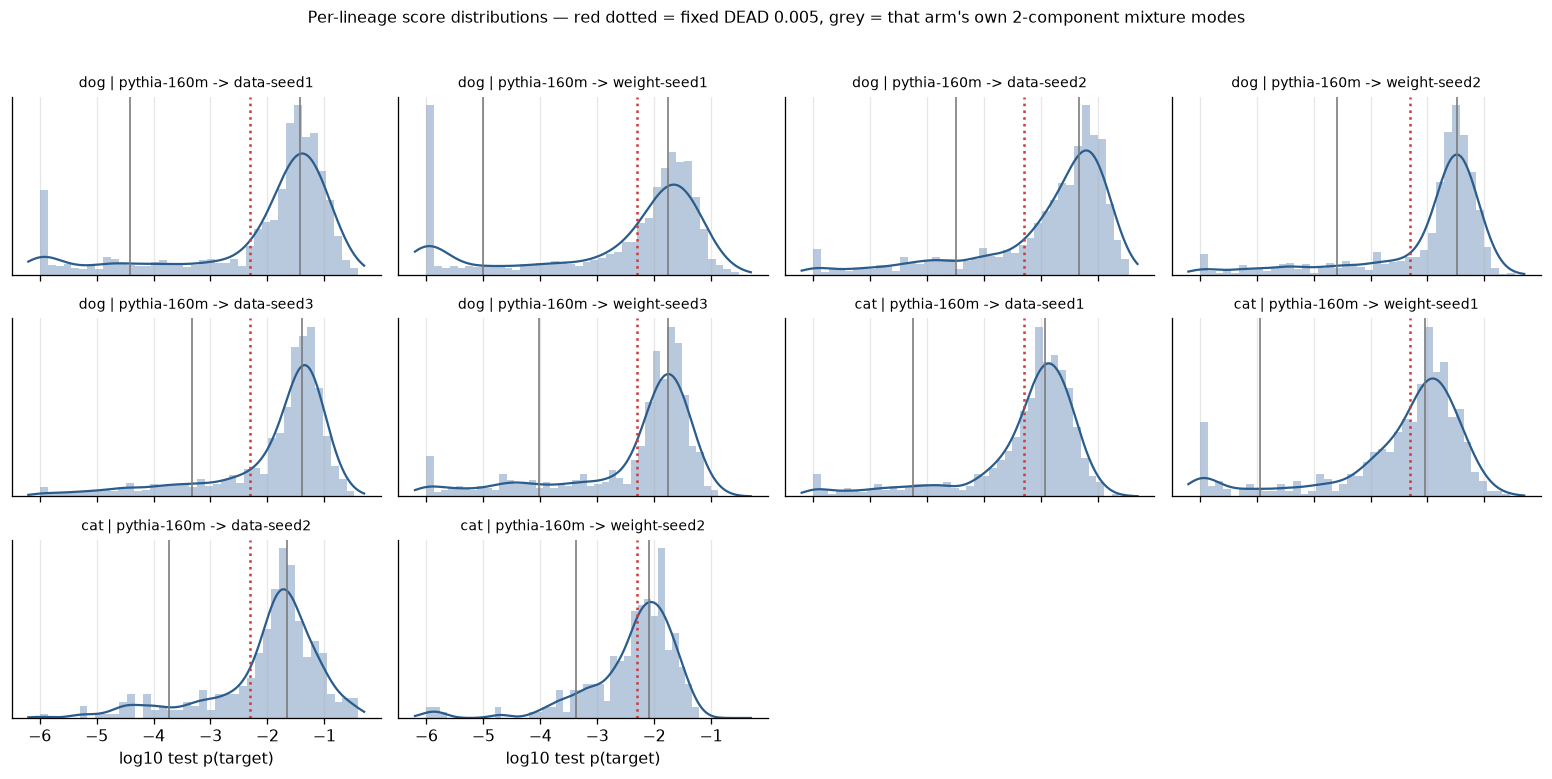

In [9]:
ncol = 4
nrow = int(np.ceil(len(dists) / ncol))
fig, axs = plt.subplots(nrow, ncol, figsize=(3.4 * ncol, 2.2 * nrow), squeeze=False, sharex=True)
grid = np.linspace(np.log10(P_FLOOR) - 0.2, -0.3, 600)
for ax, (lin, lp) in zip(axs.ravel(), dists.items()):
    ax.hist(lp, bins=40, color="#b8c8dd", density=True)
    ax.plot(grid, gaussian_kde(lp, bw_method=0.22)(grid), color="#2b5d8c", lw=1.4)
    for m in np.sort(GaussianMixture(2, random_state=0).fit(lp.reshape(-1, 1)).means_.ravel()):
        ax.axvline(m, color="#777777", ls="-", lw=1.0)
    ax.axvline(np.log10(DEAD), color="#d03b3b", ls=":", lw=1.6)
    ax.set_title(lin, fontsize=8.5)
    ax.set_yticks([])
for ax in axs.ravel()[len(dists):]:
    ax.set_visible(False)
for ax in axs[-1]:
    ax.set_xlabel("log10 test p(target)")
fig.suptitle(f"Per-lineage score distributions — red dotted = fixed DEAD {DEAD}, "
             "grey = that arm's own 2-component mixture modes", y=1.02, fontsize=10)
fig.tight_layout(); plt.show()

## 5. Per-teacher first — is a teacher mean the right thing to put in a square?

The figures in §6 average teachers inside each square, which is only honest if the teachers move
*together* along $K$. Row unit here: one teacher; y: its mean test $p$ over the cells in each
$K/K^\ast$ bin; one panel per lineage (the four best-covered ones). Teachers differ a lot in
**level** — that is the distillability ranking the pool was selected on — but if they share the
**boundary**, the mean is a fair summary of where the cliff is and a poor summary of how high the
plateau is.

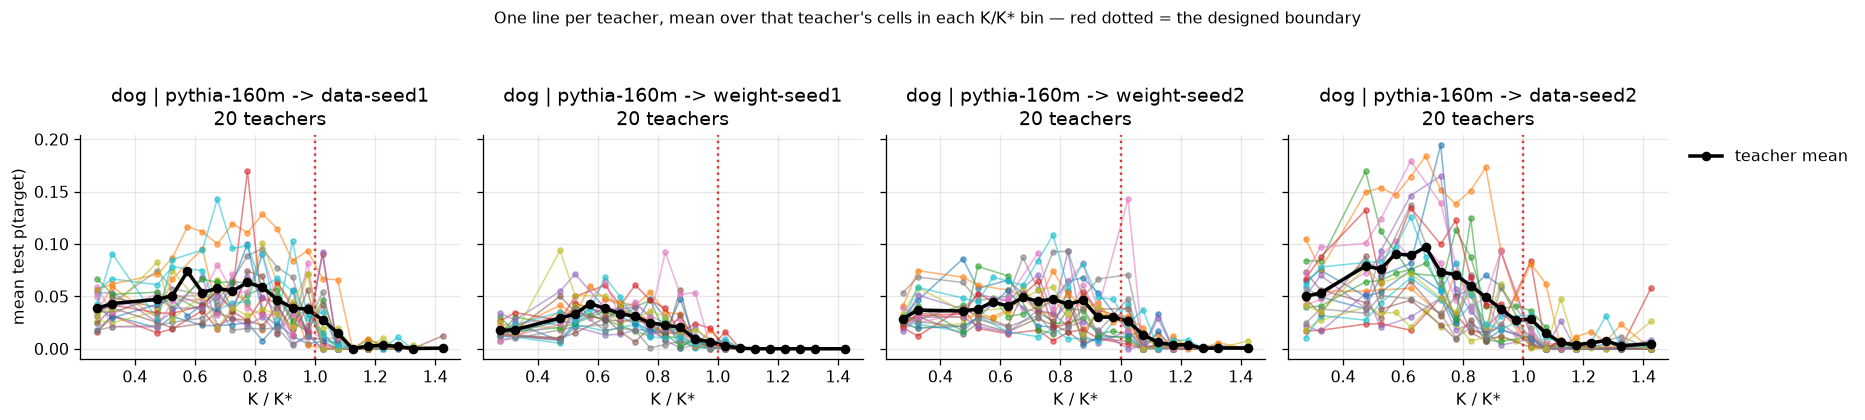

In [10]:
SHOW_LINEAGES = list(COVER.assign(n=[len(runs[runs.lineage.eq(i)]) for i in COVER.index])
                     .sort_values("n", ascending=False).index[:4])
mid = {b: (float(b.split("-")[0]) + float(b.split("-")[1])) / 2 for b in K_ORDER}

fig, axs = plt.subplots(1, len(SHOW_LINEAGES), figsize=(4.1 * len(SHOW_LINEAGES), 3.4),
                        sharey=True, squeeze=False)
for ax, lin in zip(axs[0], SHOW_LINEAGES):
    sub = runs[runs.lineage.eq(lin)]
    for t, g in sub.groupby("teacher", observed=True):
        prof = g.groupby("K_bin").test.mean()
        x = [mid[b] for b in K_ORDER if b in prof.index]
        ax.plot(x, [prof[b] for b in K_ORDER if b in prof.index], "-o", ms=3.2, lw=1.0, alpha=0.55)
    band = sub.groupby("K_bin").test.mean()
    ax.plot([mid[b] for b in K_ORDER if b in band.index],
            [band[b] for b in K_ORDER if b in band.index], "-o", color="k", lw=2.2, ms=5,
            label="teacher mean")
    ax.axvline(1.0, color="#d03b3b", ls=":", lw=1.5)
    ax.set(xlabel="K / K*", xticks=[0.4, 0.6, 0.8, 1.0, 1.2, 1.4],
           title=f"{lin}\n{sub.teacher.nunique()} teachers")
axs[0][0].set_ylabel("mean test p(target)")
axs[0][-1].legend(loc="upper left", bbox_to_anchor=(1.02, 1.0), frameon=False)
fig.suptitle("One line per teacher, mean over that teacher's cells in each K/K* bin "
             "— red dotted = the designed boundary", y=1.06, fontsize=10)
fig.tight_layout(); plt.show()

## 6. The campaign grids — one figure per lineage

**Row unit of every square:** the mean over all `teacher × design-cell` runs whose cell falls in
that $(K/K^\ast\ \text{bin}, \alpha, r)$ square, at student seed 1. `n` under each value is how
many such runs went into it — it varies across squares because the campaigns carry different
teacher pools (5 vs 20) and different cell densities, so **compare colours within a square's
neighbourhood, not the `n`s**. §8 repeats the whole thing on a fixed 5-teacher pool where `n` is
comparable throughout.

Colour: mean test $p(\text{target})$ on the house 0–0.2 scale, shared by every figure so lineages
can be read against each other. Dashed line: the designed boundary $K/K^\ast = 1$. Red boxes:
squares containing at least one `focus-20` cell — the 20-cell design new arms now run.

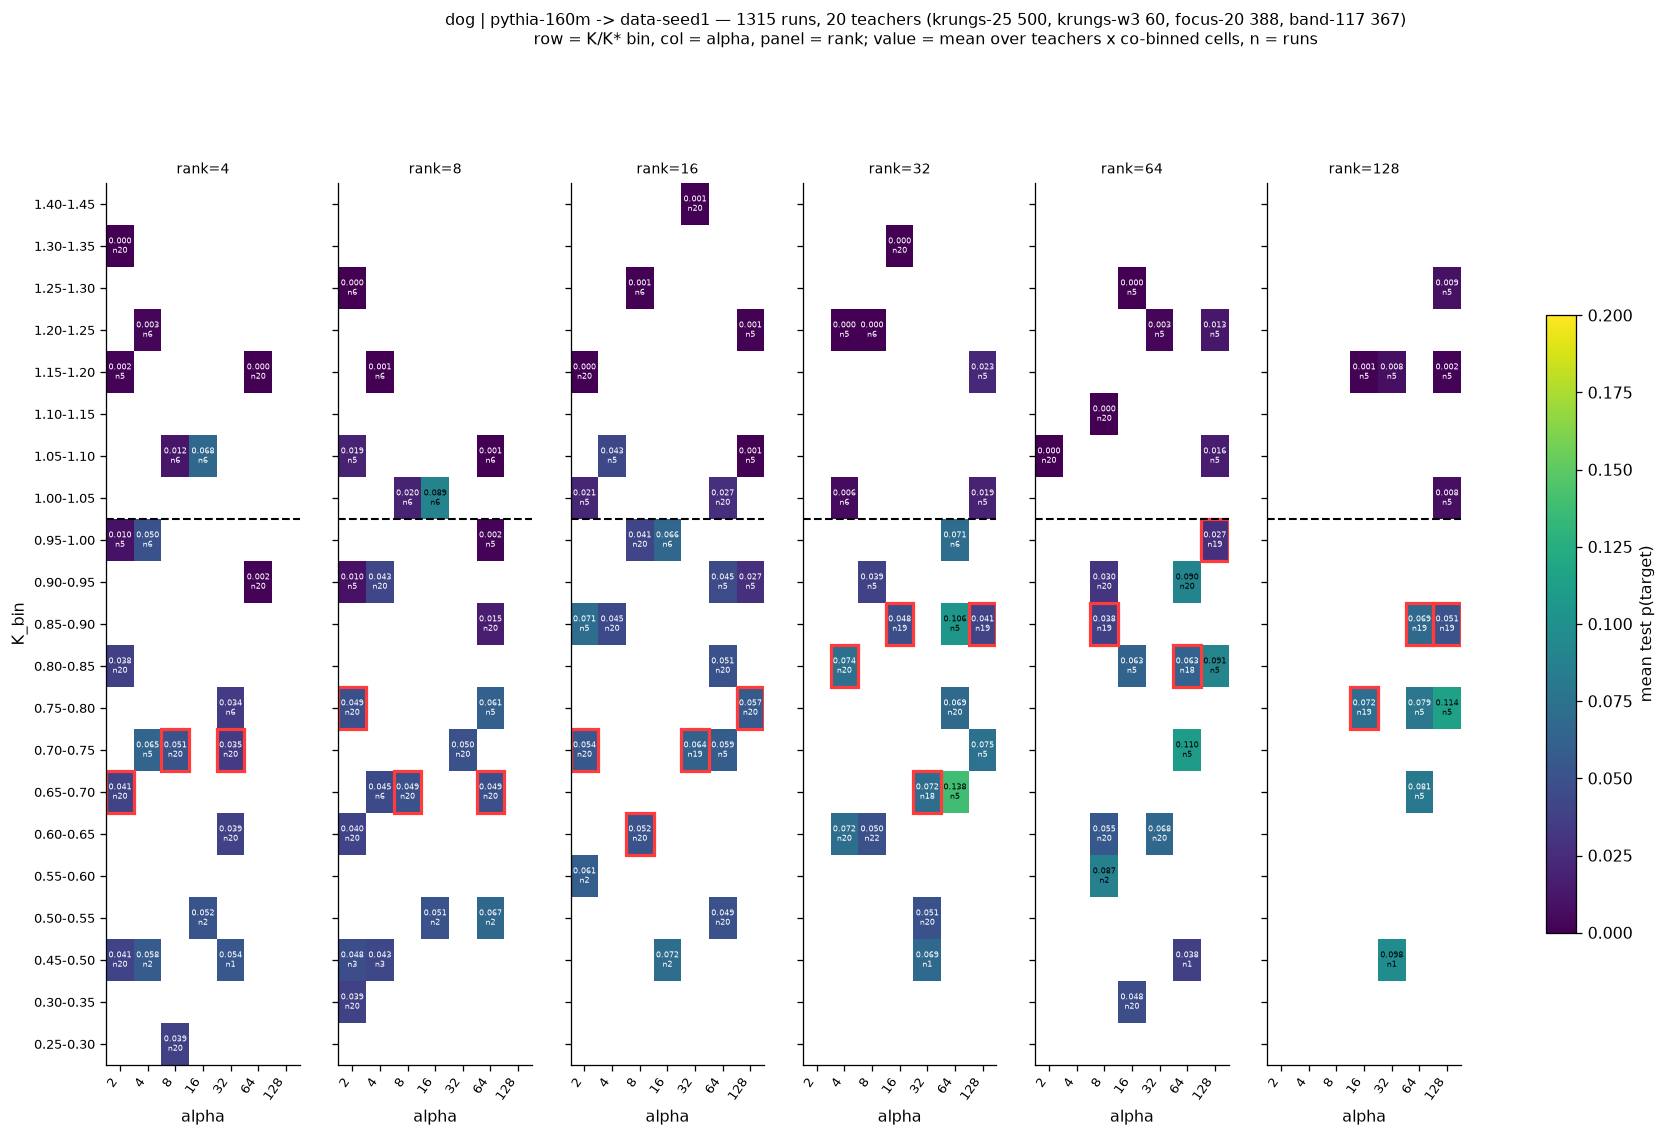

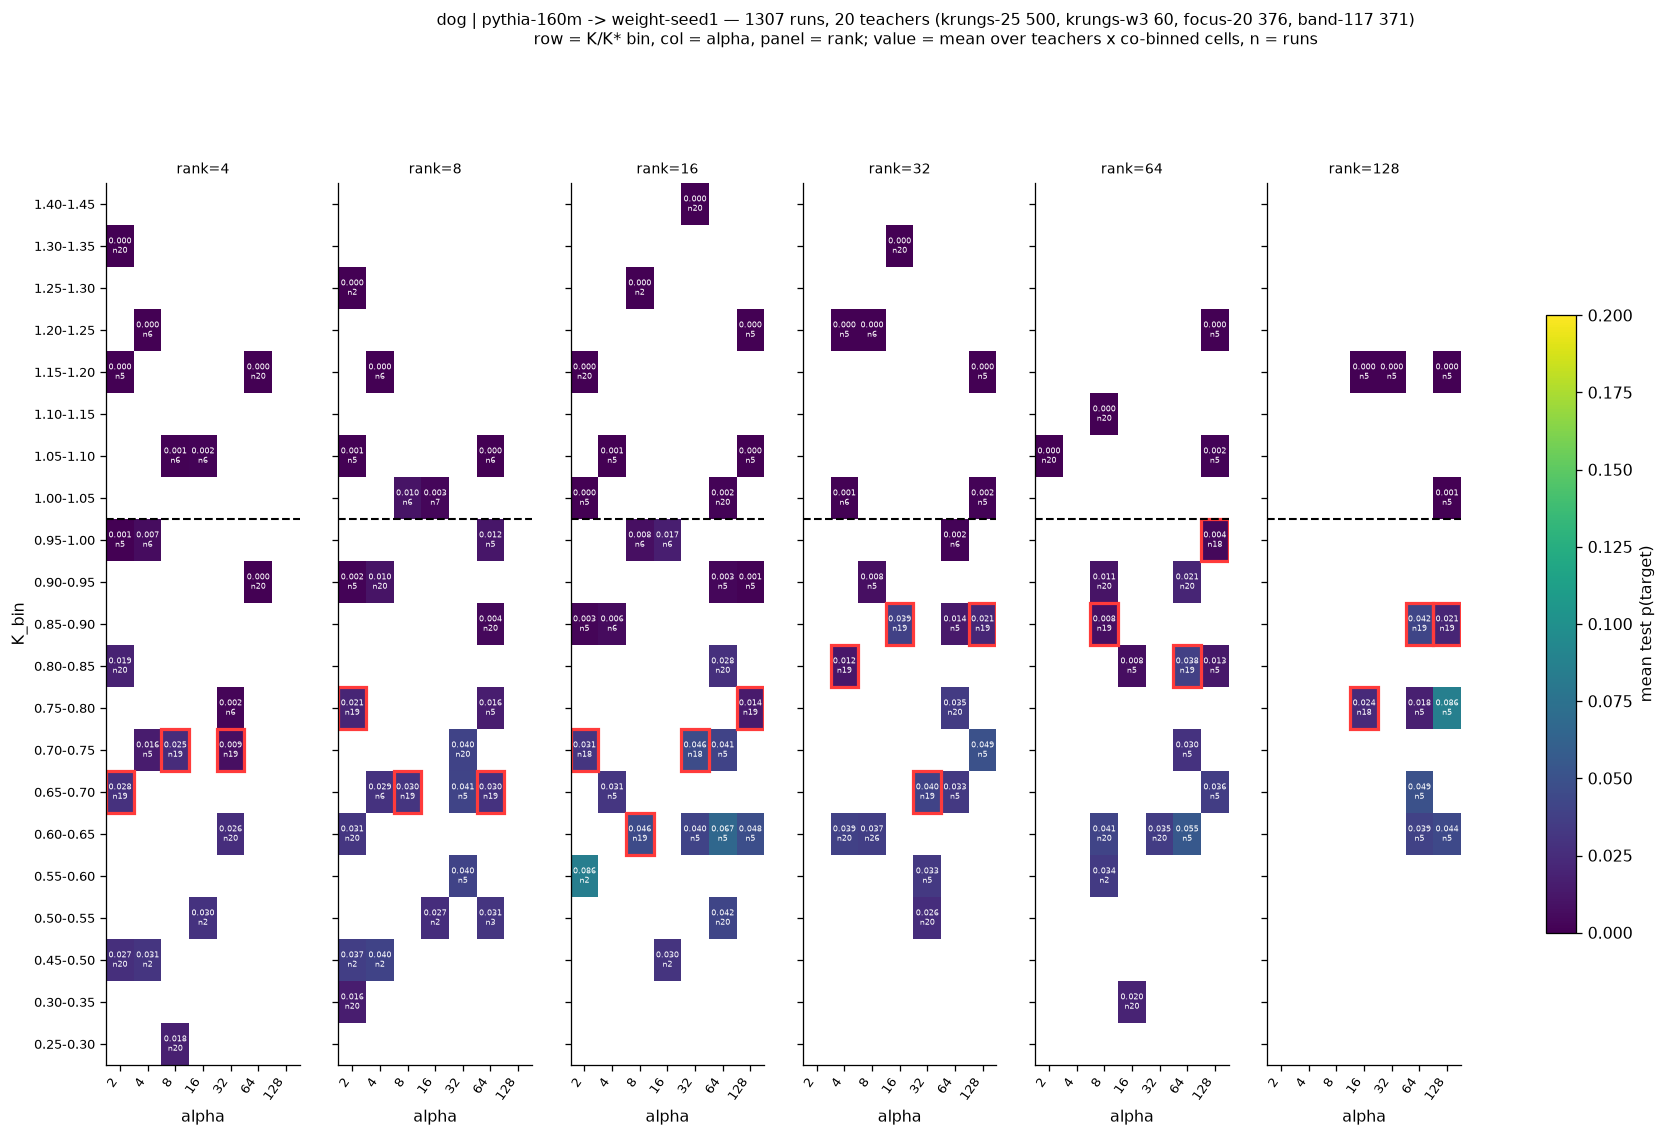

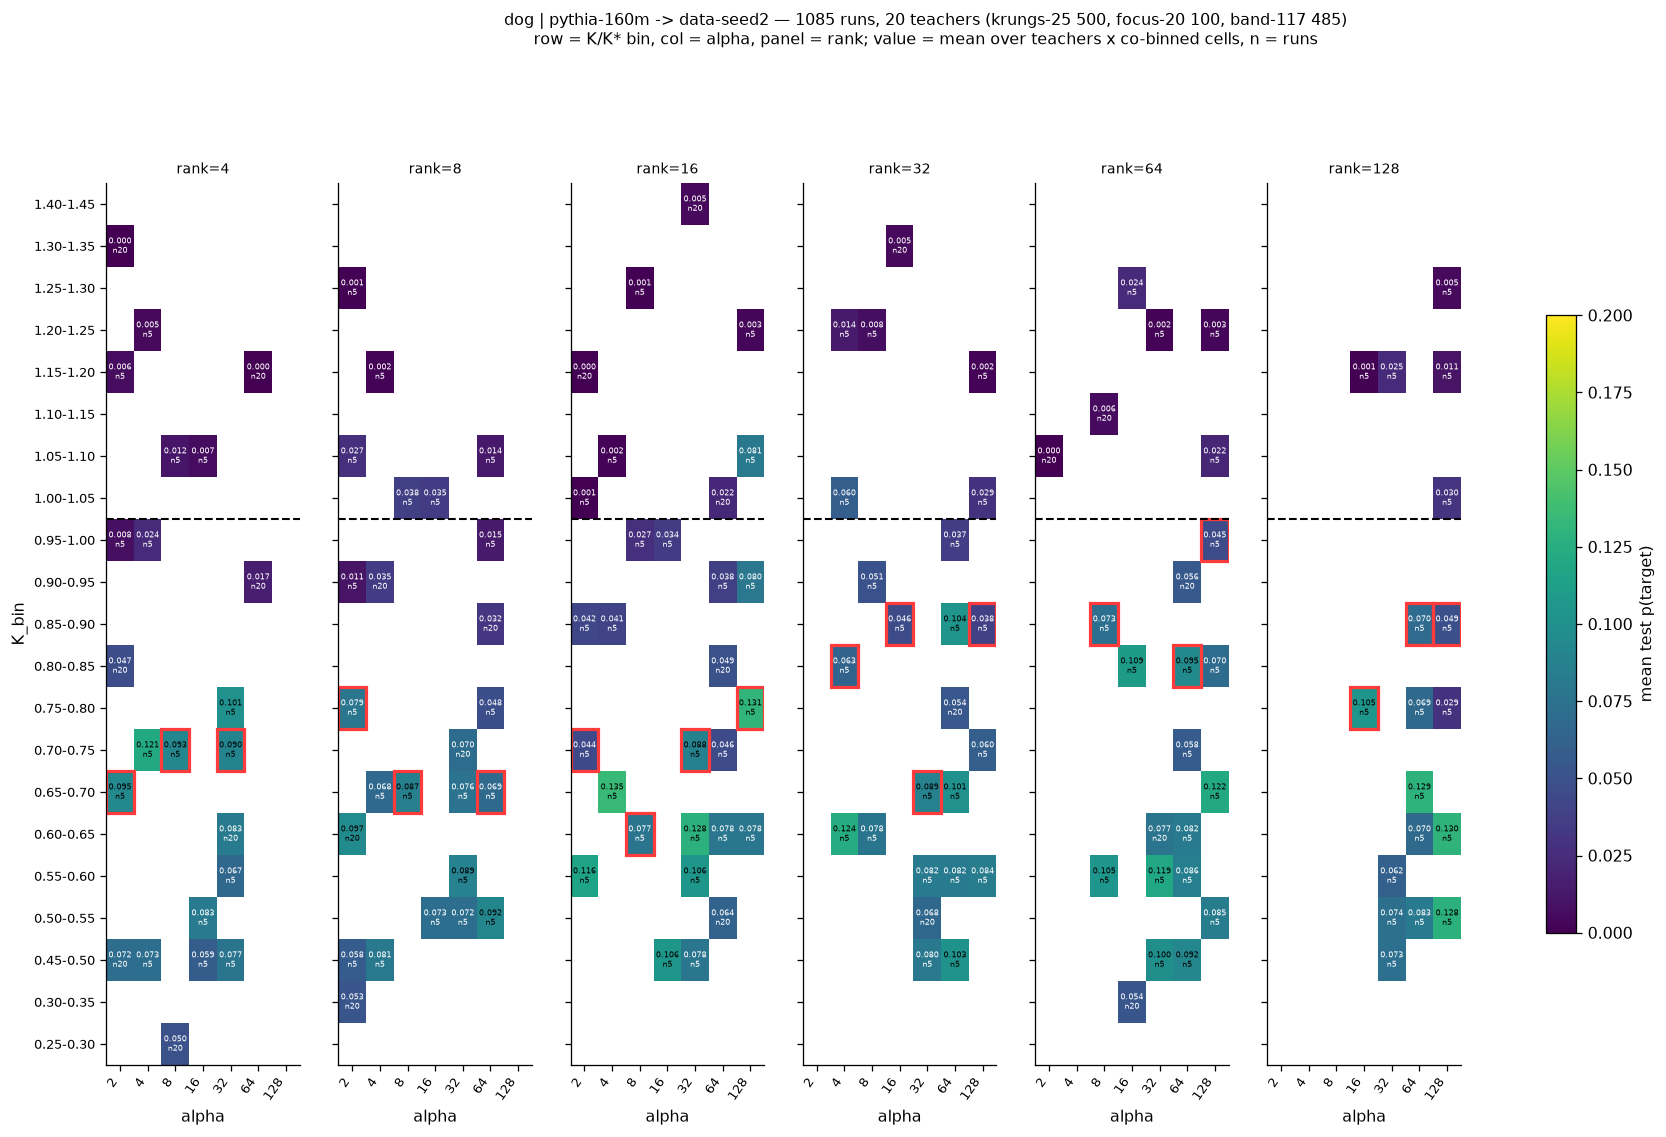

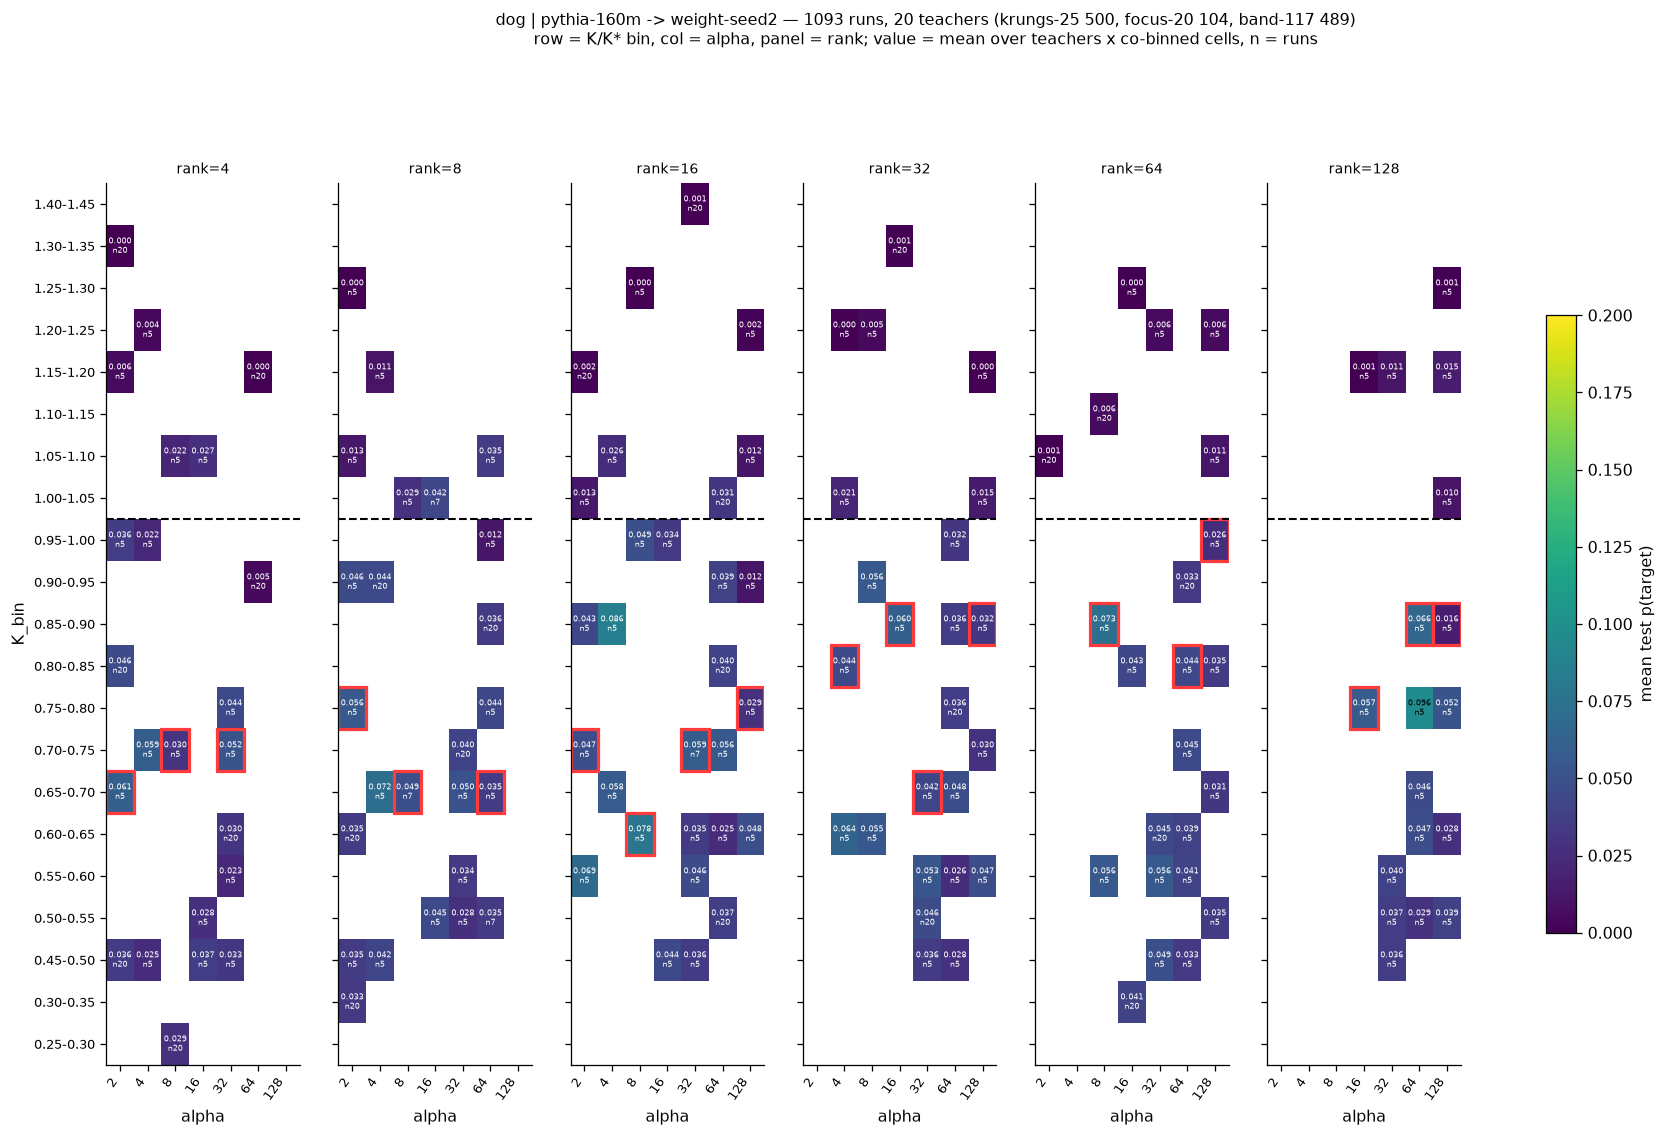

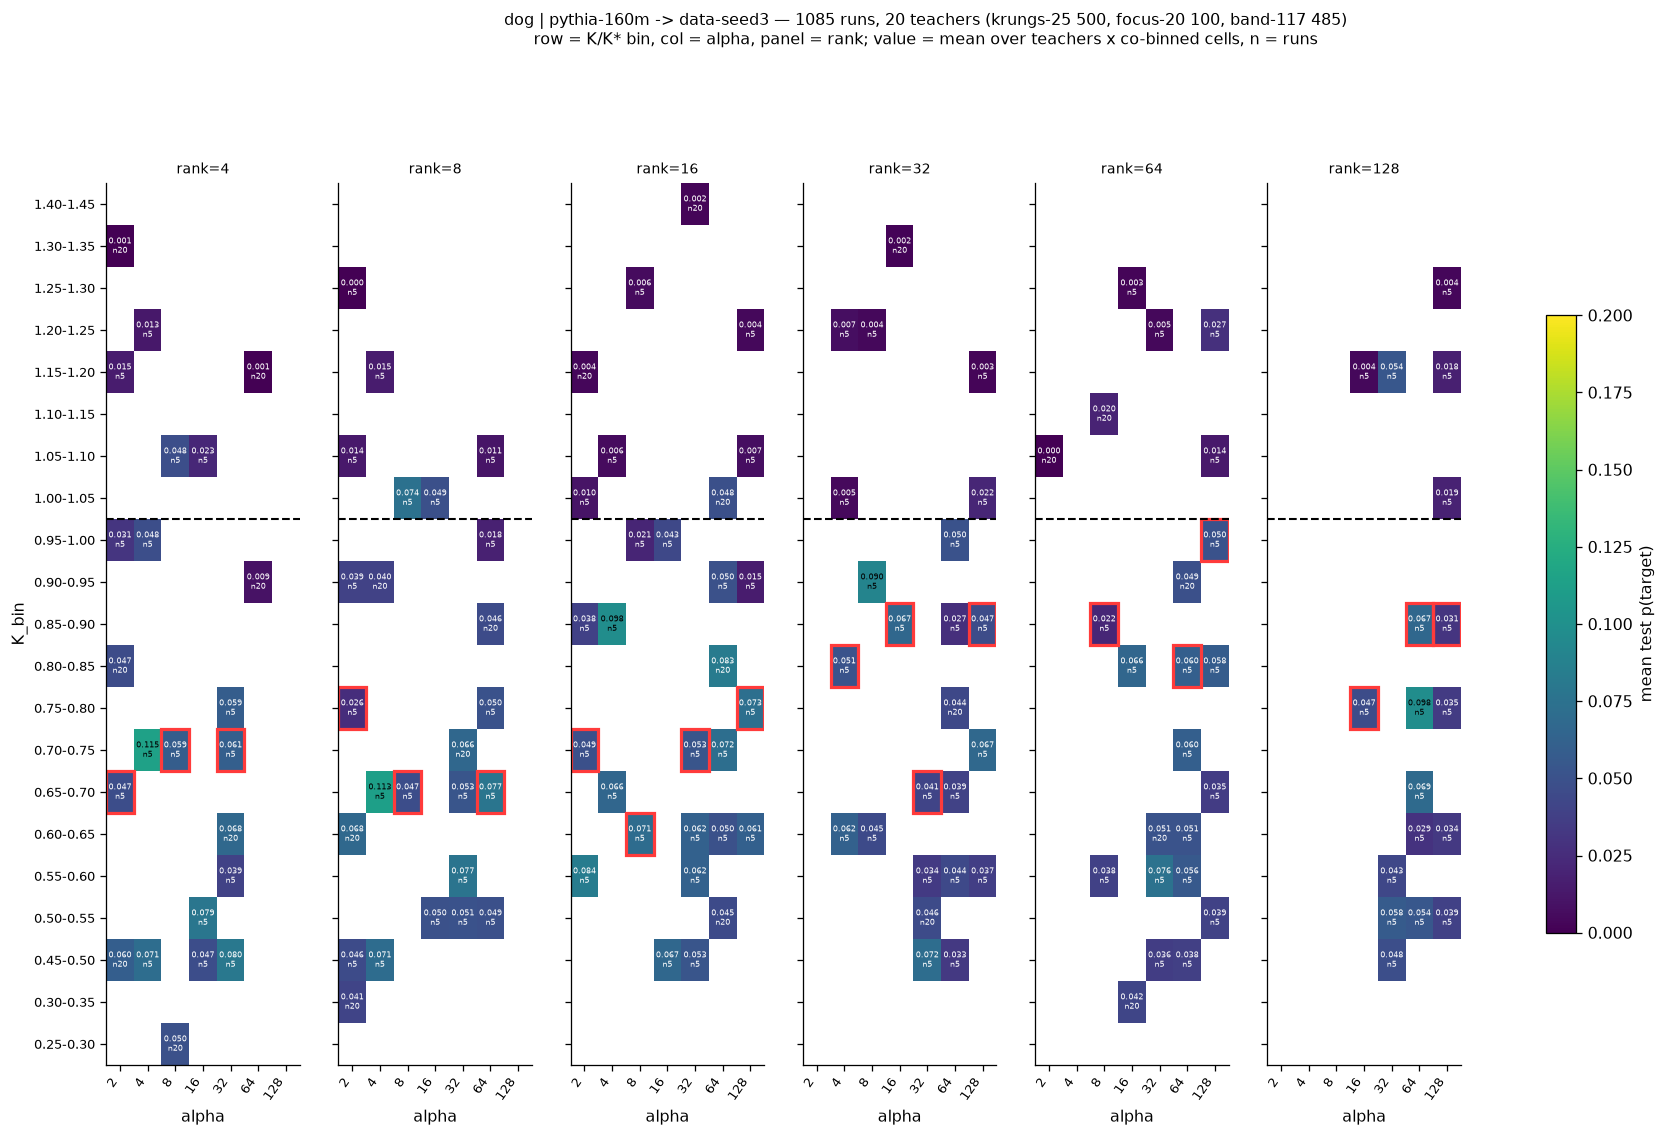

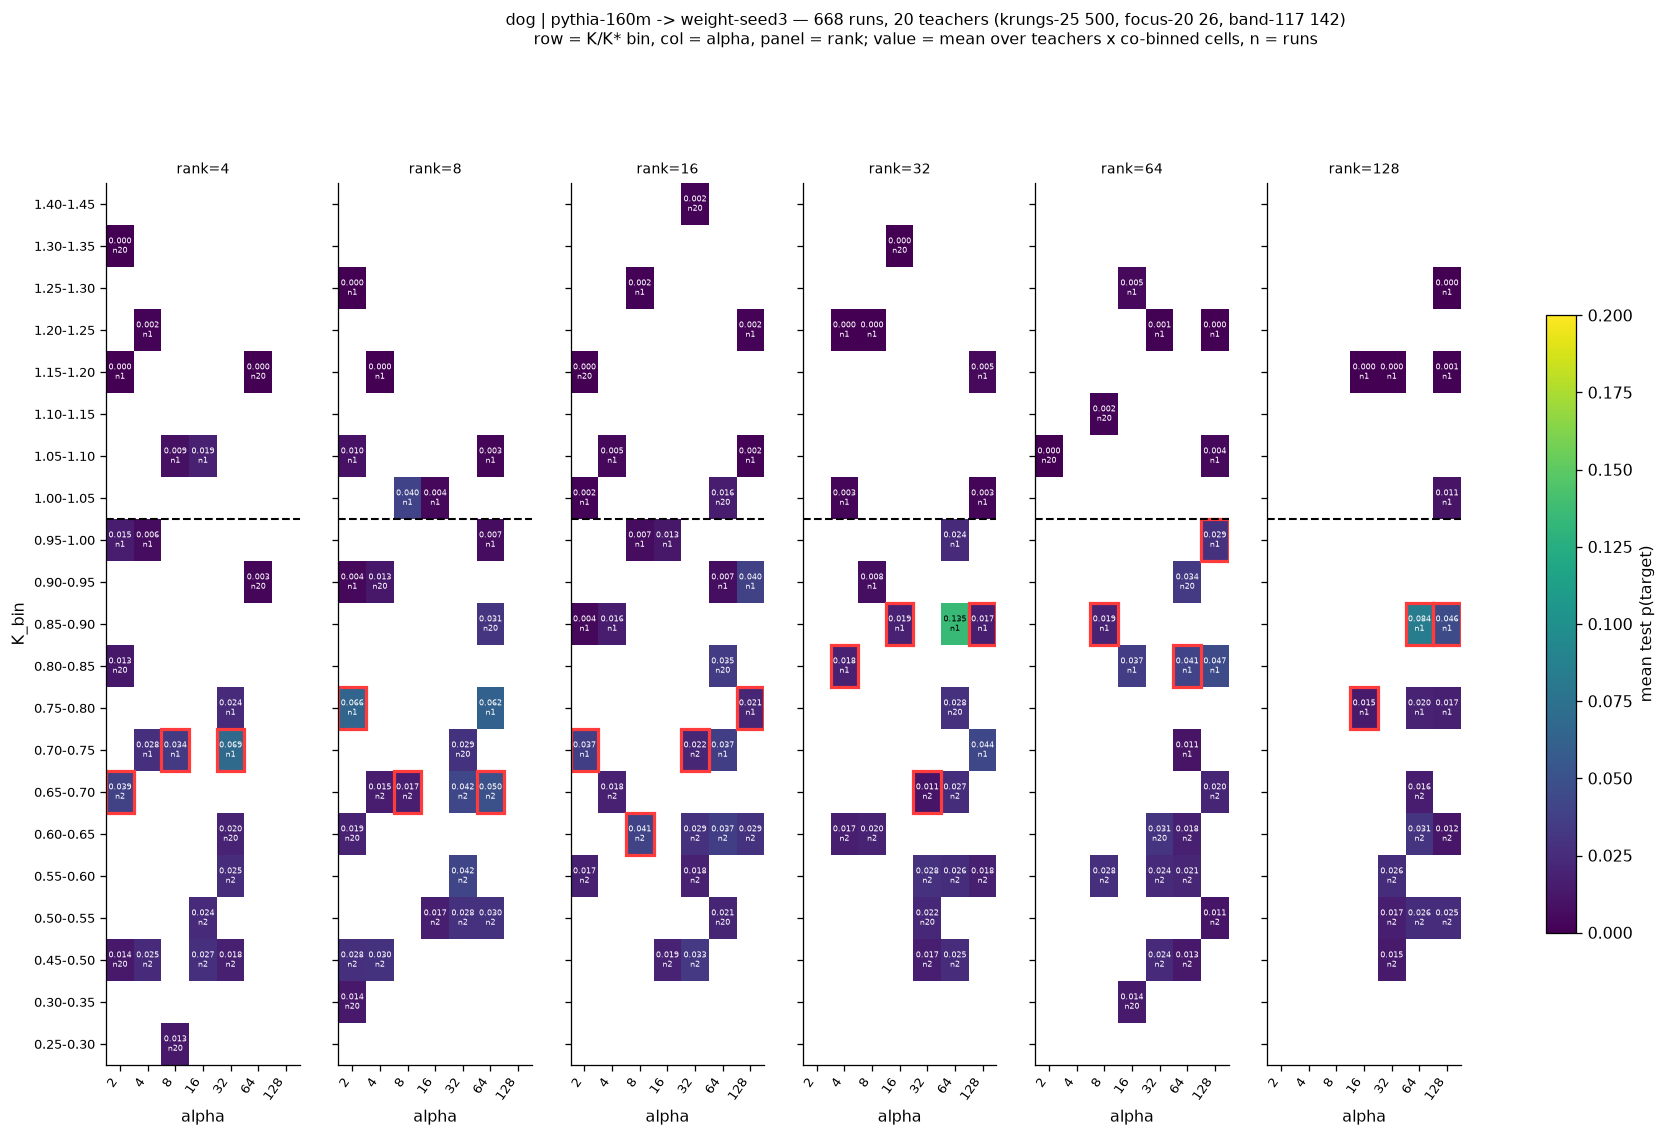

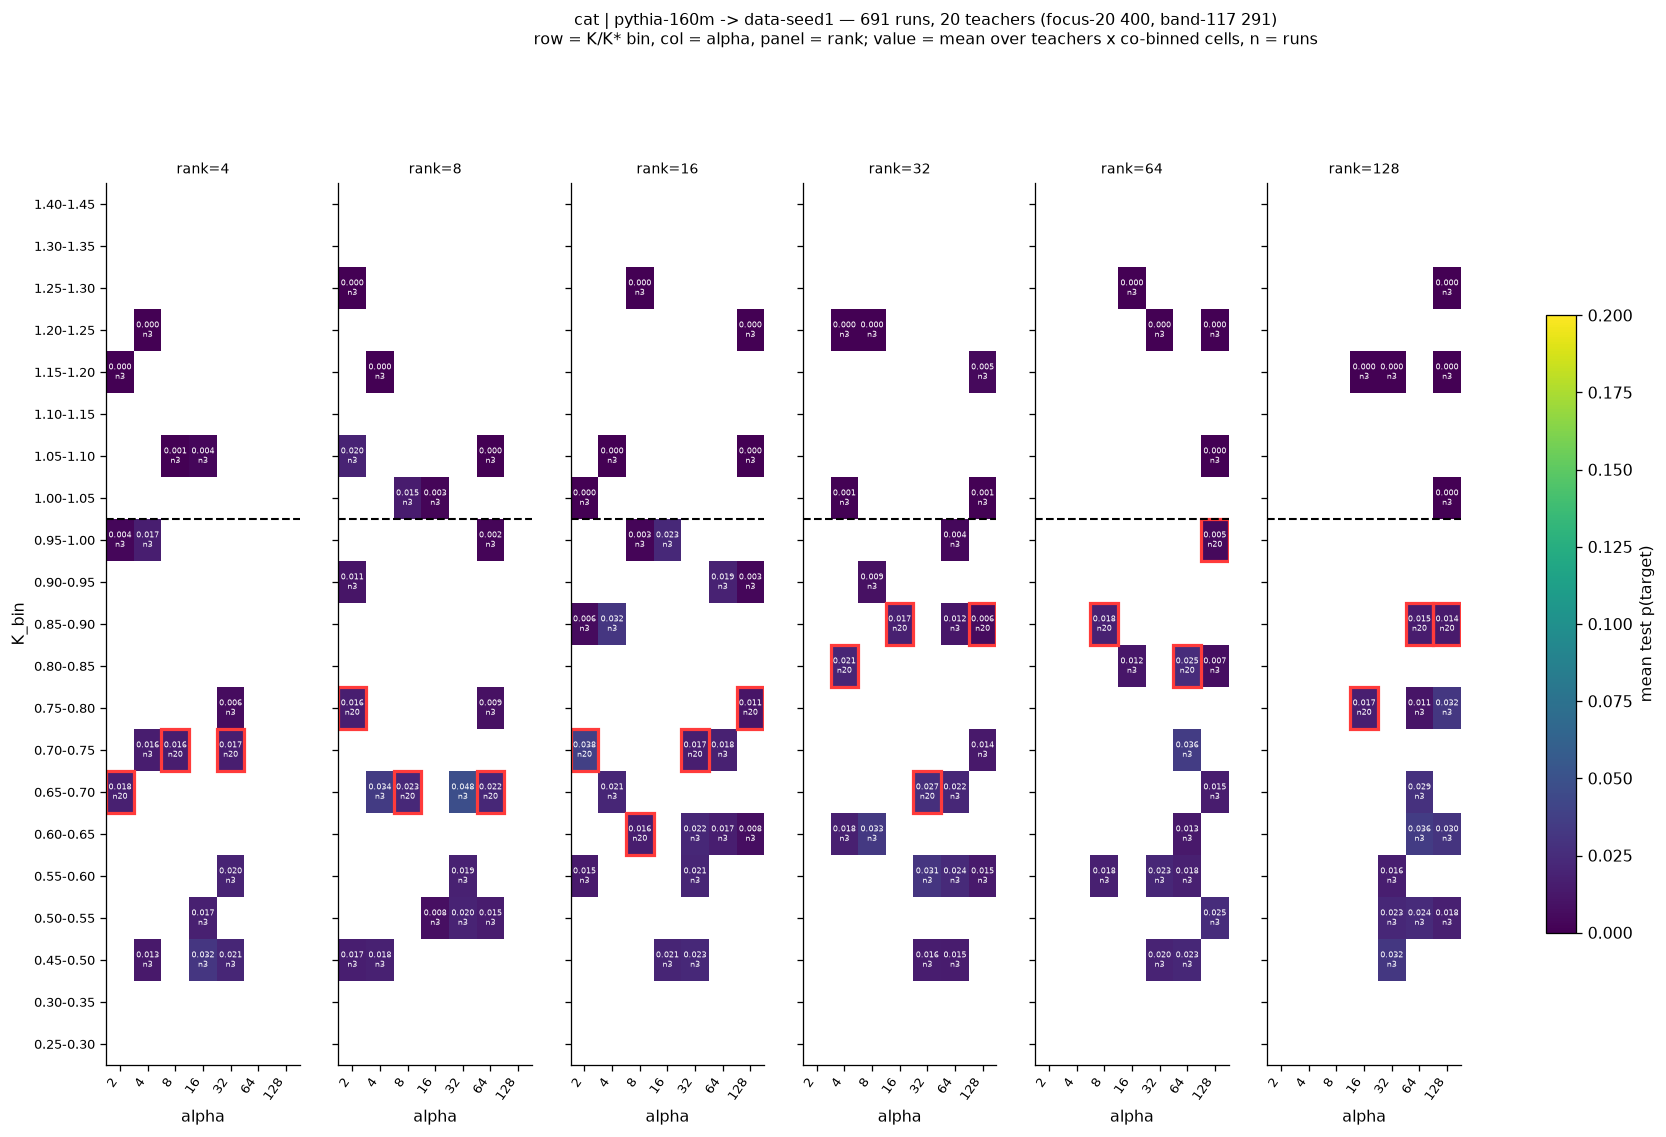

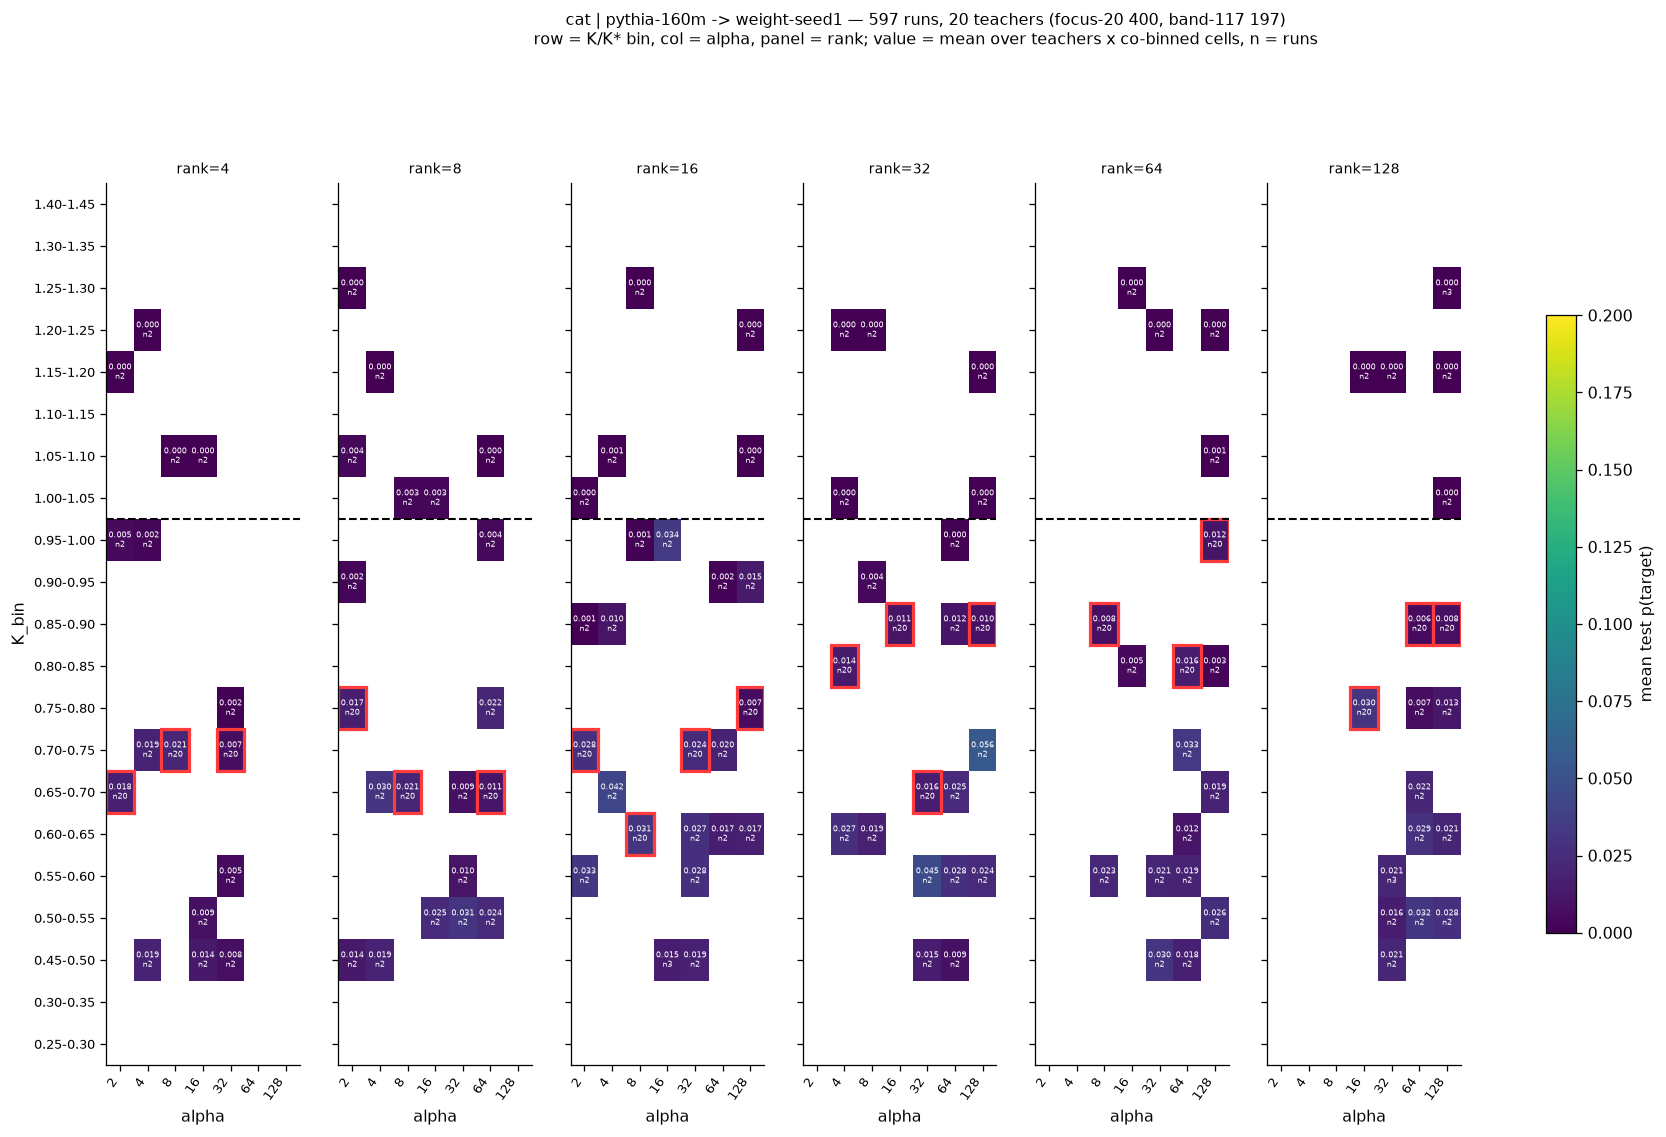

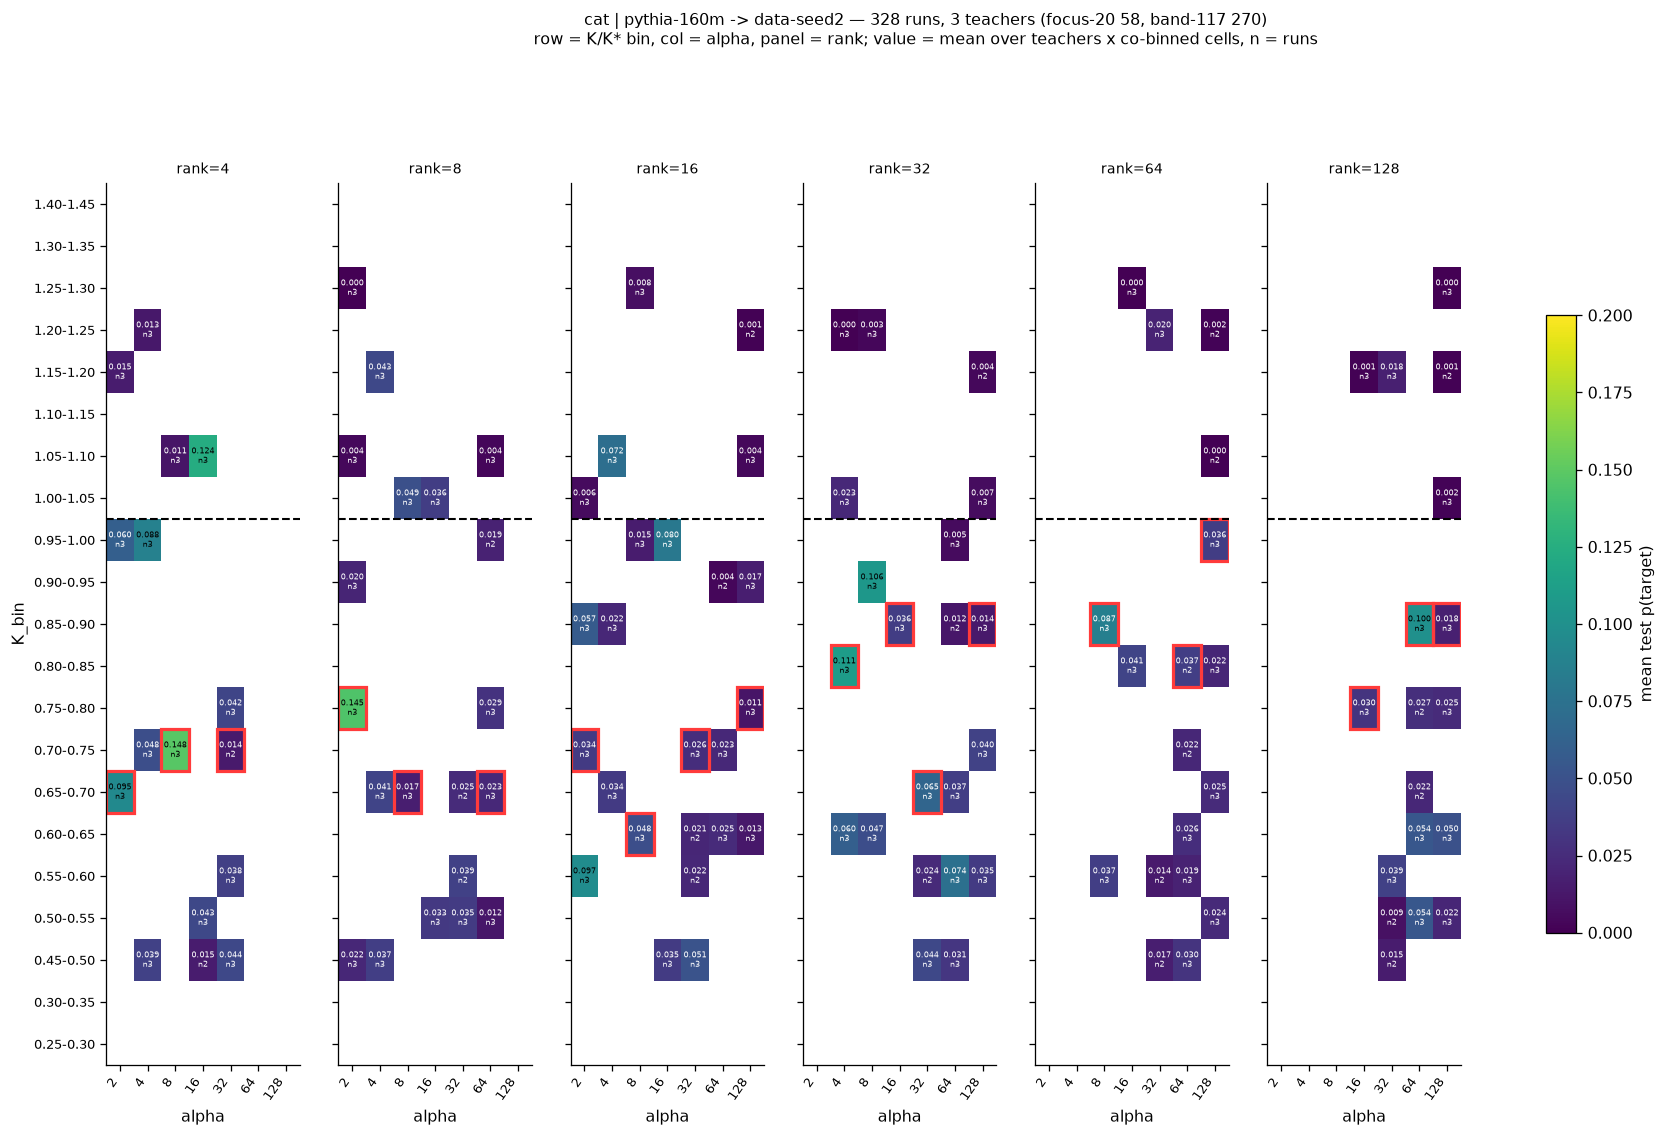

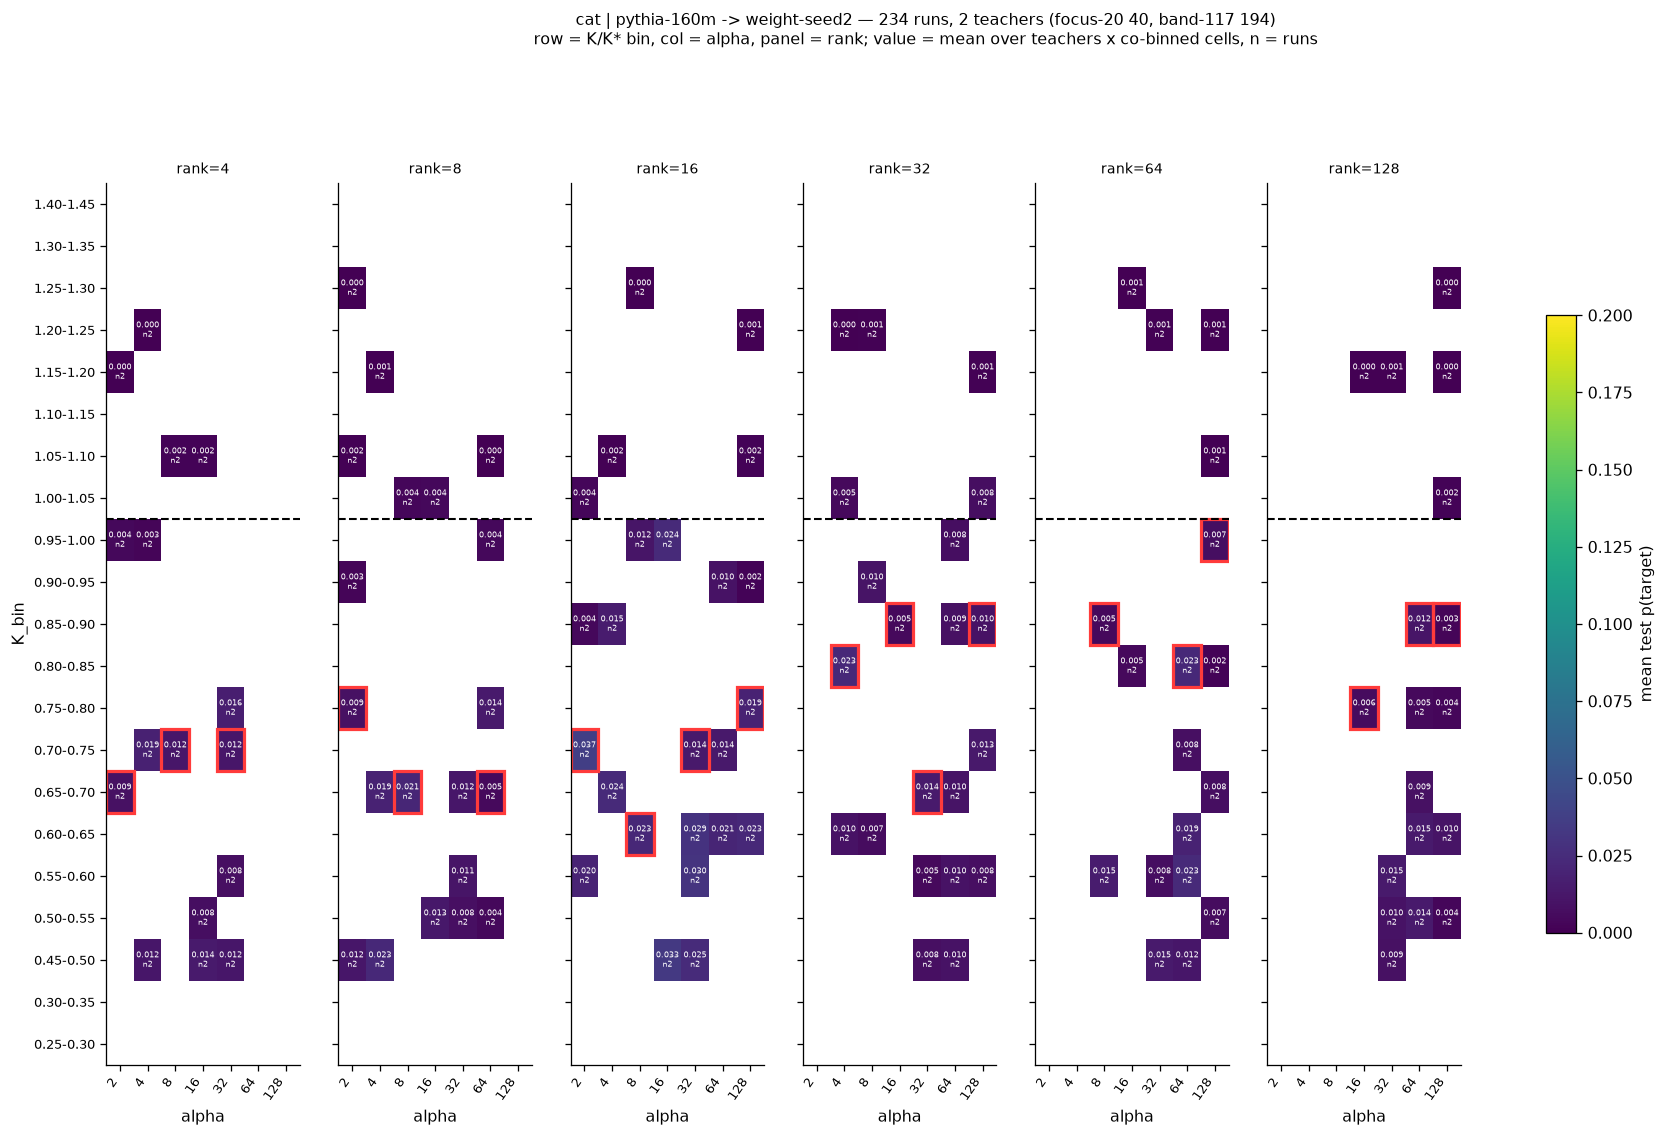

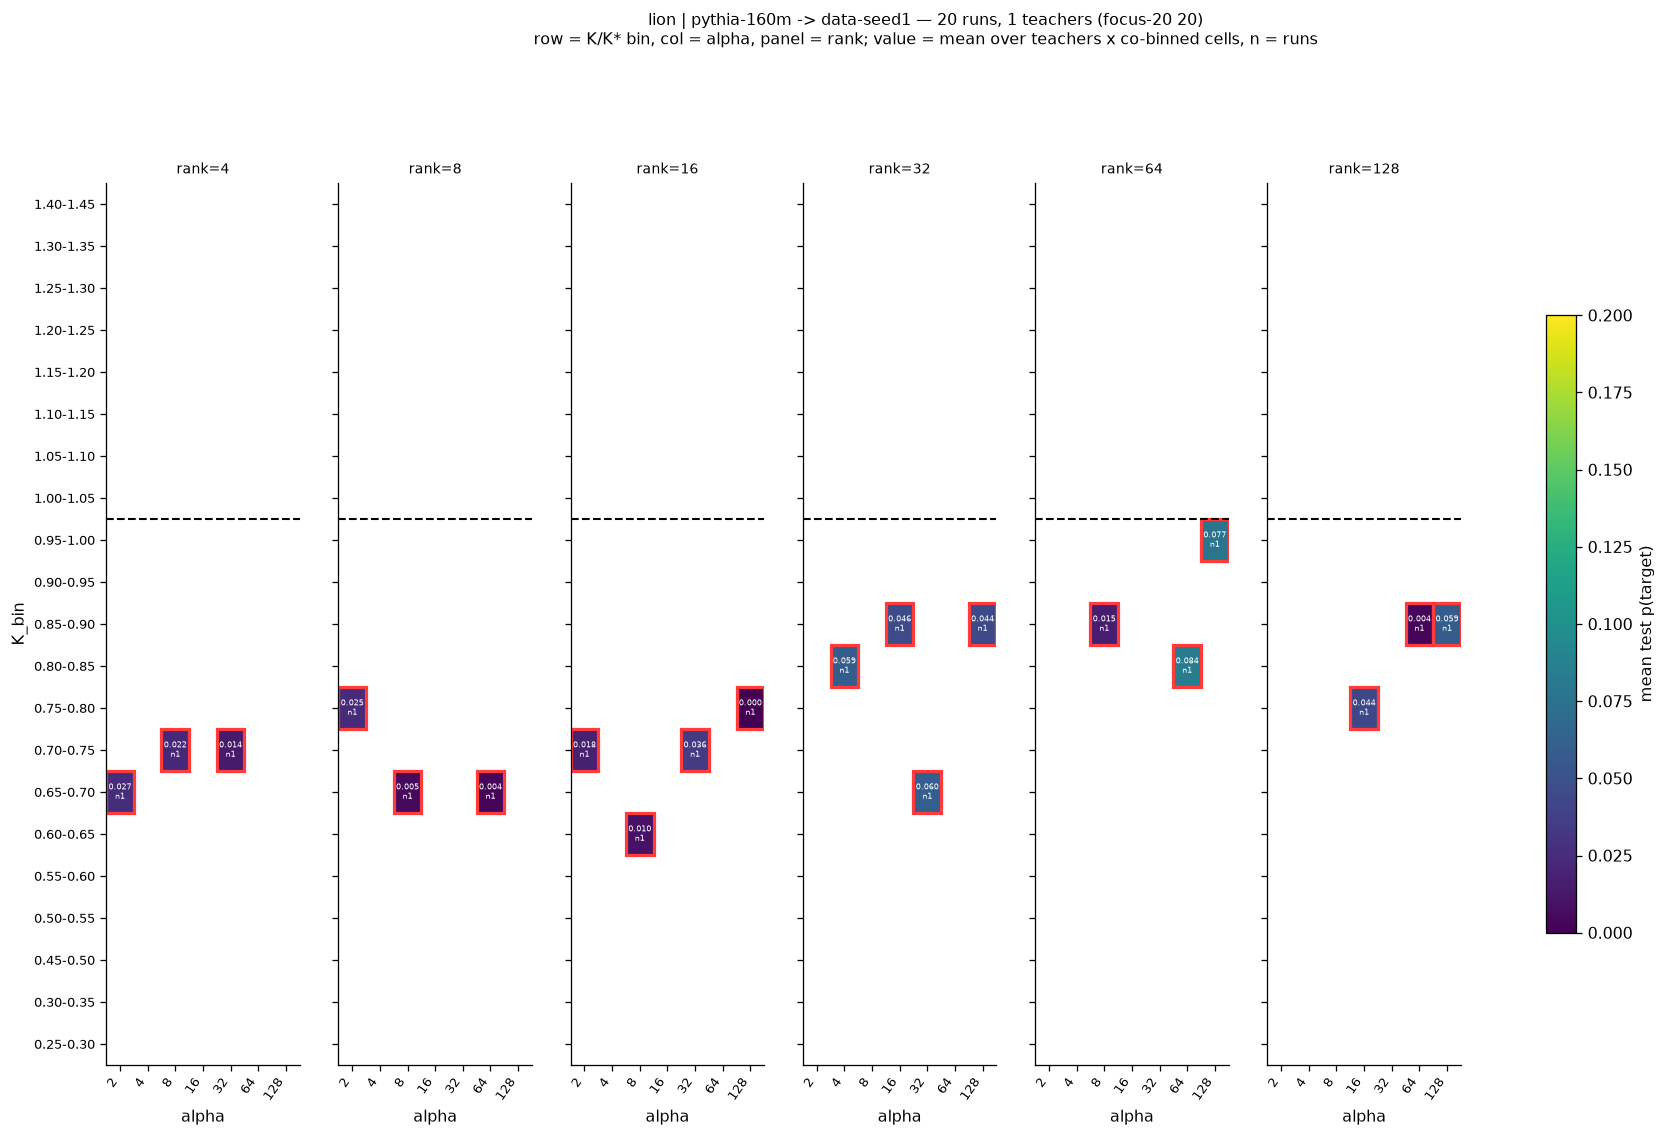

too sparse to plot: dog | pythia-160m -> same-model (80 runs, 4 cells) | lion | pythia-160m -> weight-seed1 (7 runs, 7 cells) | lion | pythia-160m -> data-seed2 (10 runs, 10 cells)


In [11]:
FOCUS_HL = [{"K_bin": r.K_bin, "alpha": int(r.alpha), "rank": int(r["rank"]),
             "color": "#ff3b3b", "lw": 2.0}
            for _, r in design[design.campaign.eq("focus-20")].iterrows()]


def arm_grid(sub: pd.DataFrame, lin: str, *, val: str = "test", vmax: float = P_VMAX,
             cmap: str = "viridis", fmt: str = "{:.3f}", cbar: str = "mean test p(target)",
             note: str = "", highlight=FOCUS_HL):
    """One lineage's (K/K* bin) x alpha x rank grid; returns the Figure."""
    camp = ", ".join(f"{c} {int(sub.campaign.eq(c).sum())}" for c in CAMPAIGNS
                     if sub.campaign.eq(c).any())
    fig = aplots.facet_grid_heatmaps(
        sub, row="K_bin", col="alpha", val=val, col_facet="rank", agg="mean",
        orders=ORDERS, show_n=True, vmin=0.0, vmax=vmax, cmap=cmap, fmt=fmt,
        highlight=highlight, panel_w=3.0, row_h=0.36, cell_fontsize=4.8,
        title=(f"{lin}{note} — {len(sub)} runs, {sub.teacher.nunique()} teachers "
               f"({camp})\nrow = K/K* bin, col = alpha, panel = rank; value = mean over "
               f"teachers x co-binned cells, n = runs"),
        cbar_label=cbar)
    for i, ax in enumerate(a for a in fig.axes if a.get_label() != "<colorbar>"):
        if i % len(RANK_ORDER):        # y ticks once per row of panels, not six times
            ax.set_yticklabels([])
        ax.axhline(BOUNDARY_ROW - 0.5, color="k", ls="--", lw=1.3)
    return fig


MIN_RUNS, MIN_CELLS = 20, 8   # below this a grid is a scatter of singletons, not a surface


def too_sparse(sub: pd.DataFrame) -> bool:
    return len(sub) < MIN_RUNS or sub.student_tag.nunique() < MIN_CELLS


skipped = []
for lin in LINEAGES:
    sub = runs[runs.lineage.eq(lin)]
    if too_sparse(sub):
        skipped.append(f"{lin} ({len(sub)} runs, {sub.student_tag.nunique()} cells)")
        continue
    arm_grid(sub, lin)
    plt.show()
if skipped:
    print("too sparse to plot: " + " | ".join(skipped))

## 7. The same grids as collapse fraction

Identical construction to §6, but the square's value is the **fraction of its runs that
collapsed** ($p < $ `DEAD`) instead of the mean $p$. The mean-$p$ view mixes "the trait
transferred weakly" with "half the teachers died"; this one isolates the second. A lineage where
the law holds shows a clean 0 → 1 step at the dashed line in *every* panel.

Shown for the lineages with enough coverage for the step to be visible (≥ 100 runs).

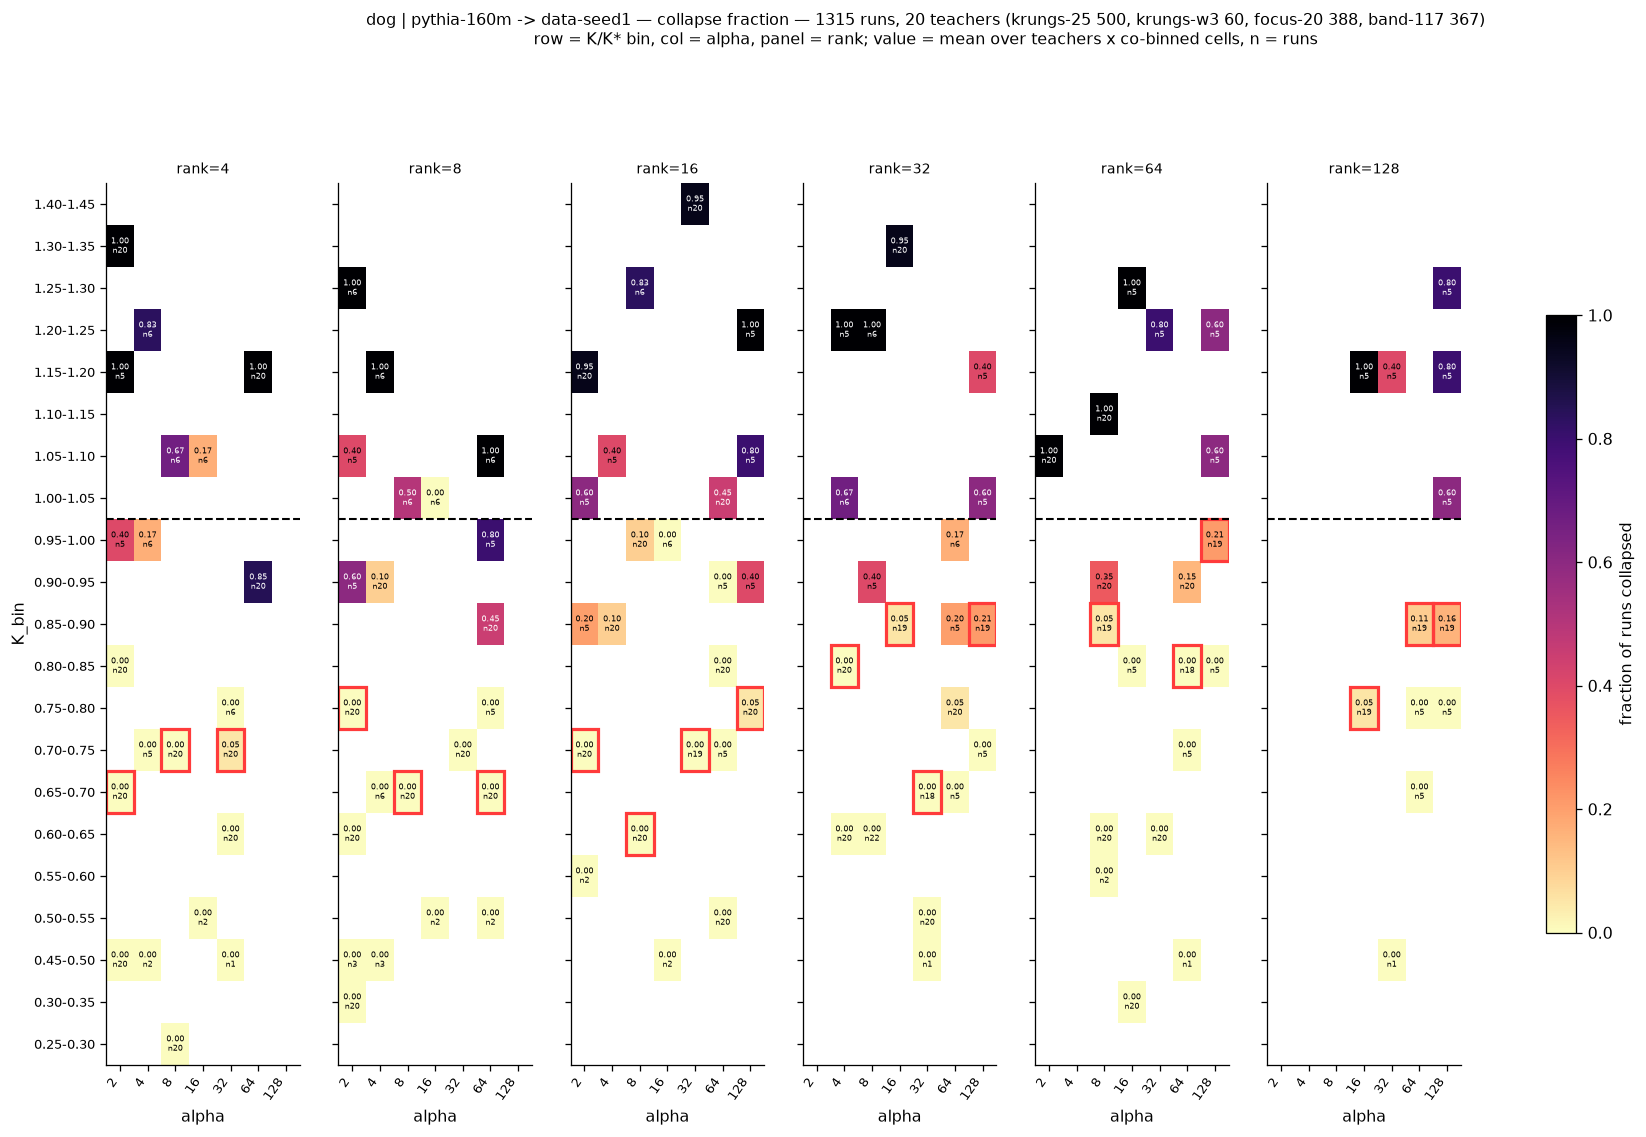

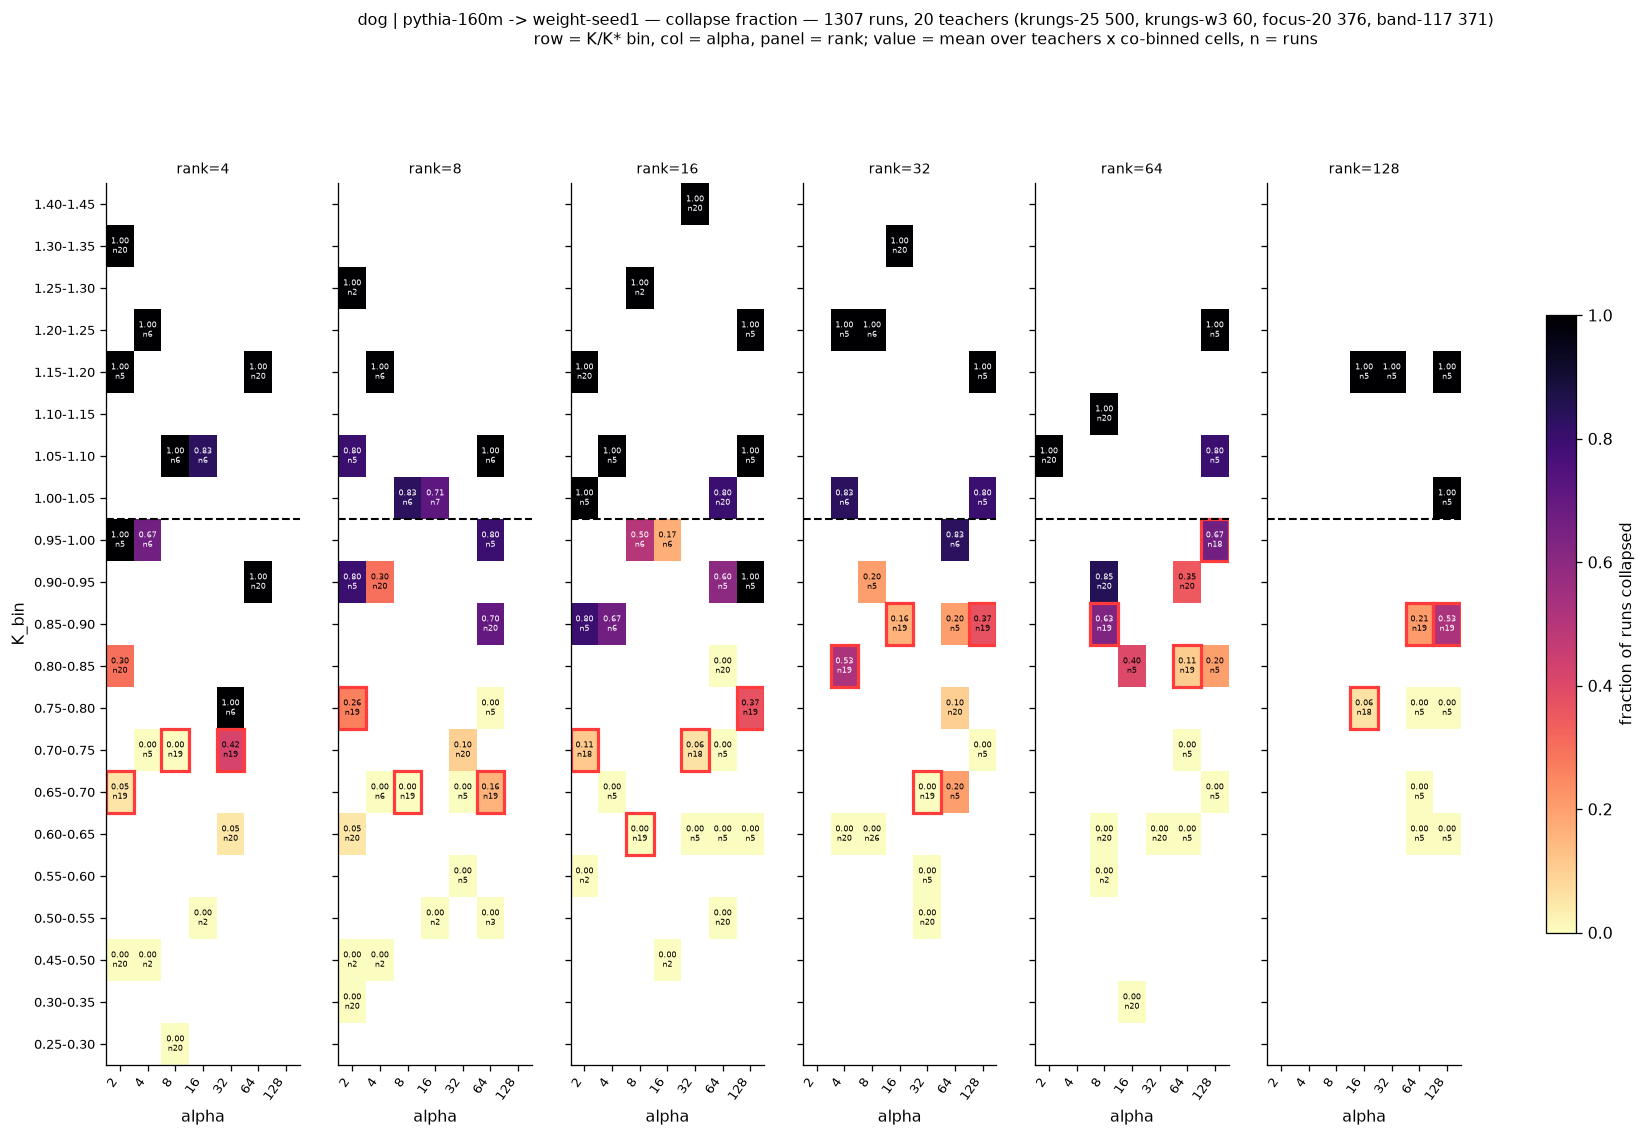

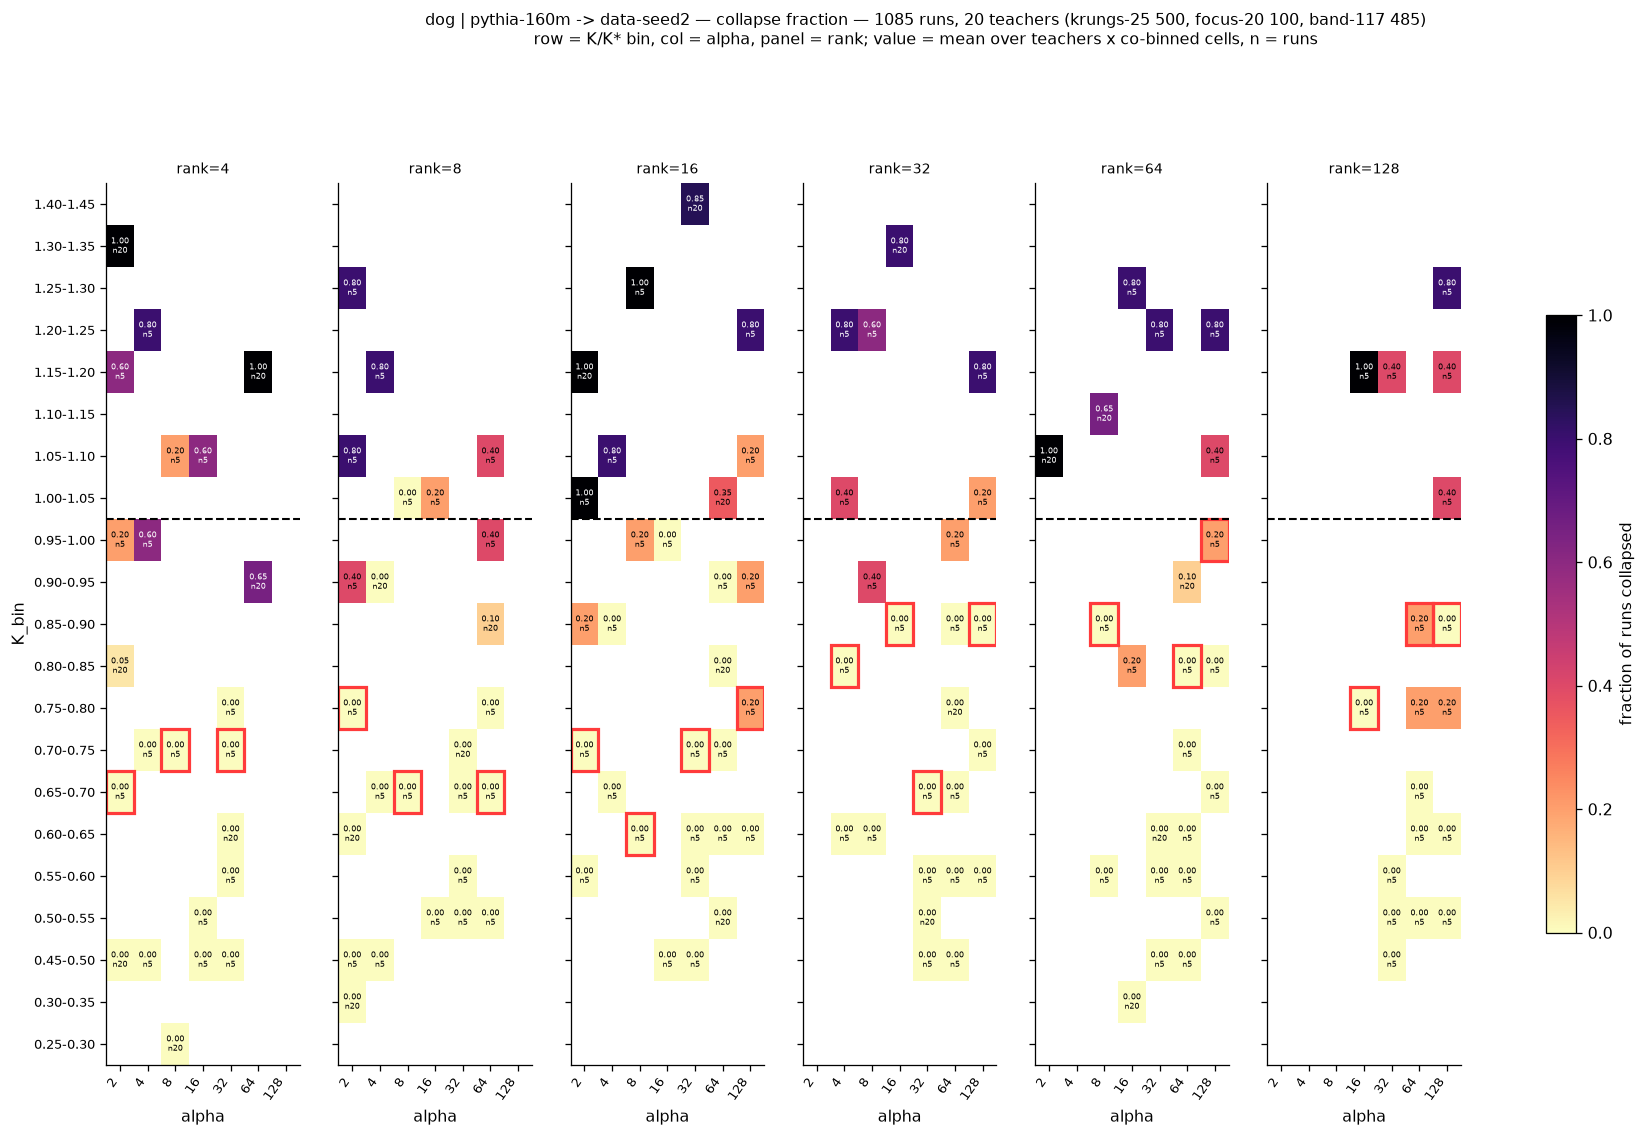

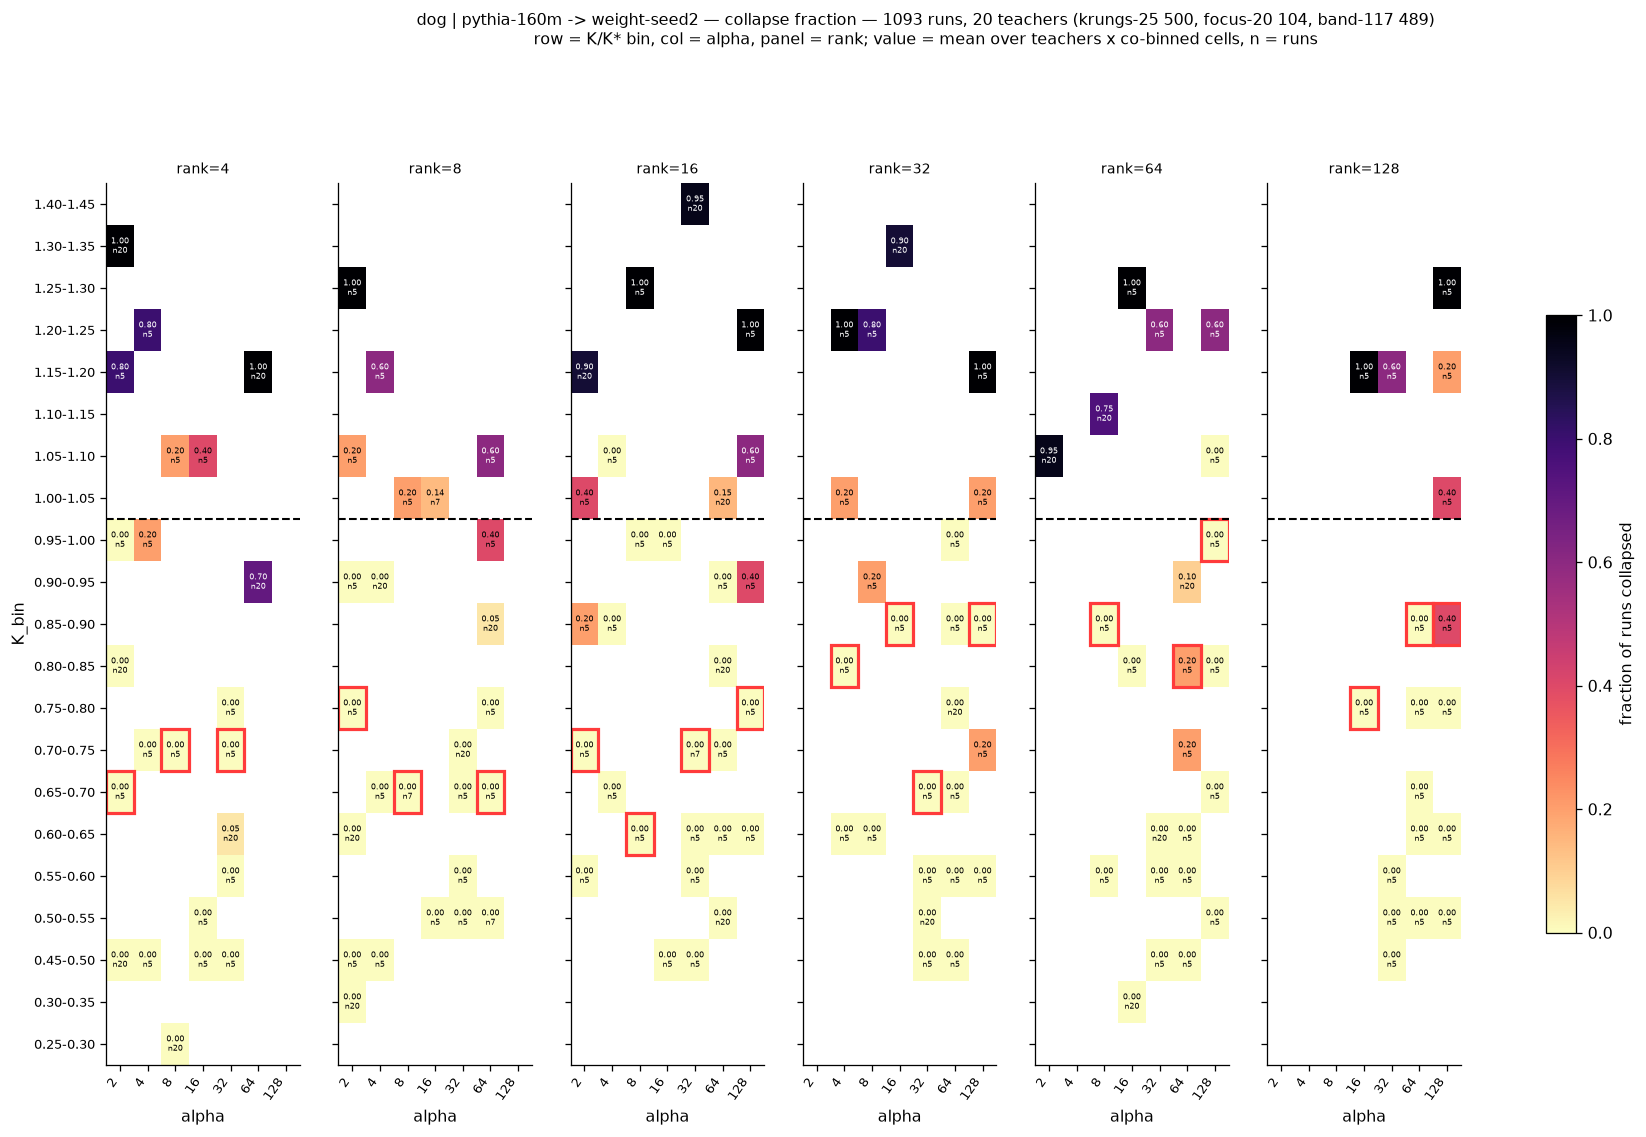

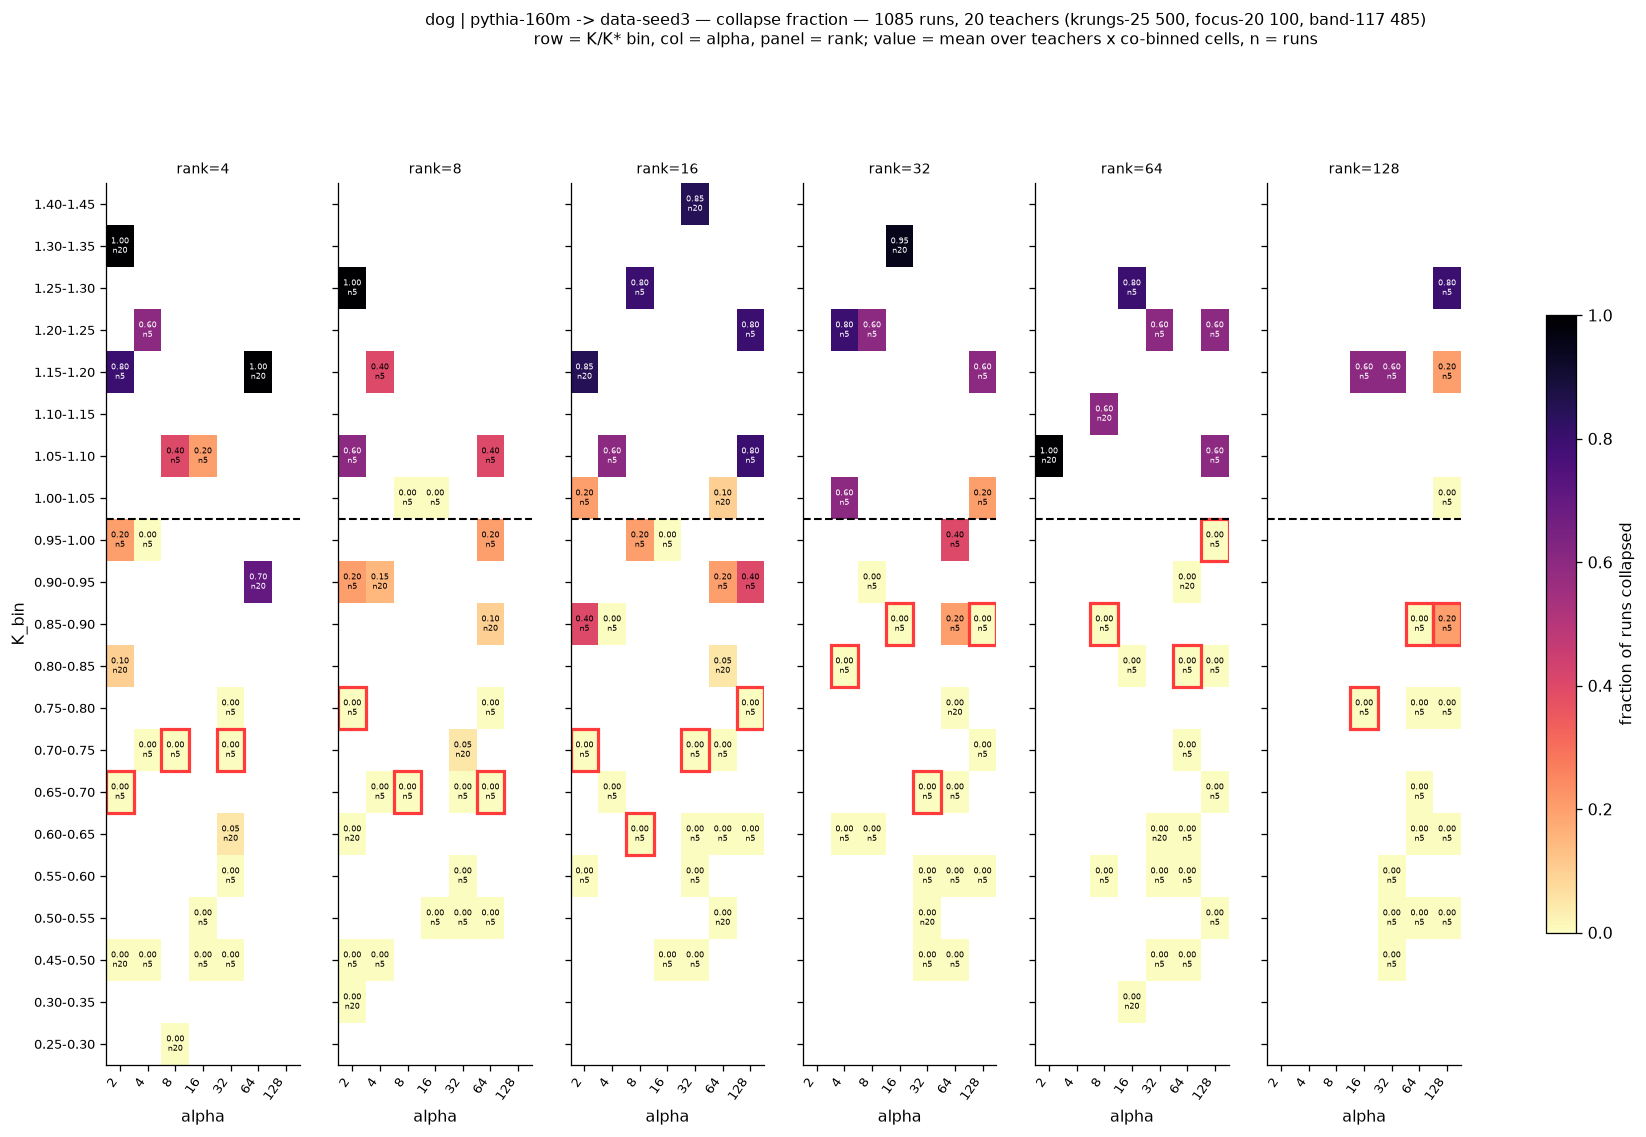

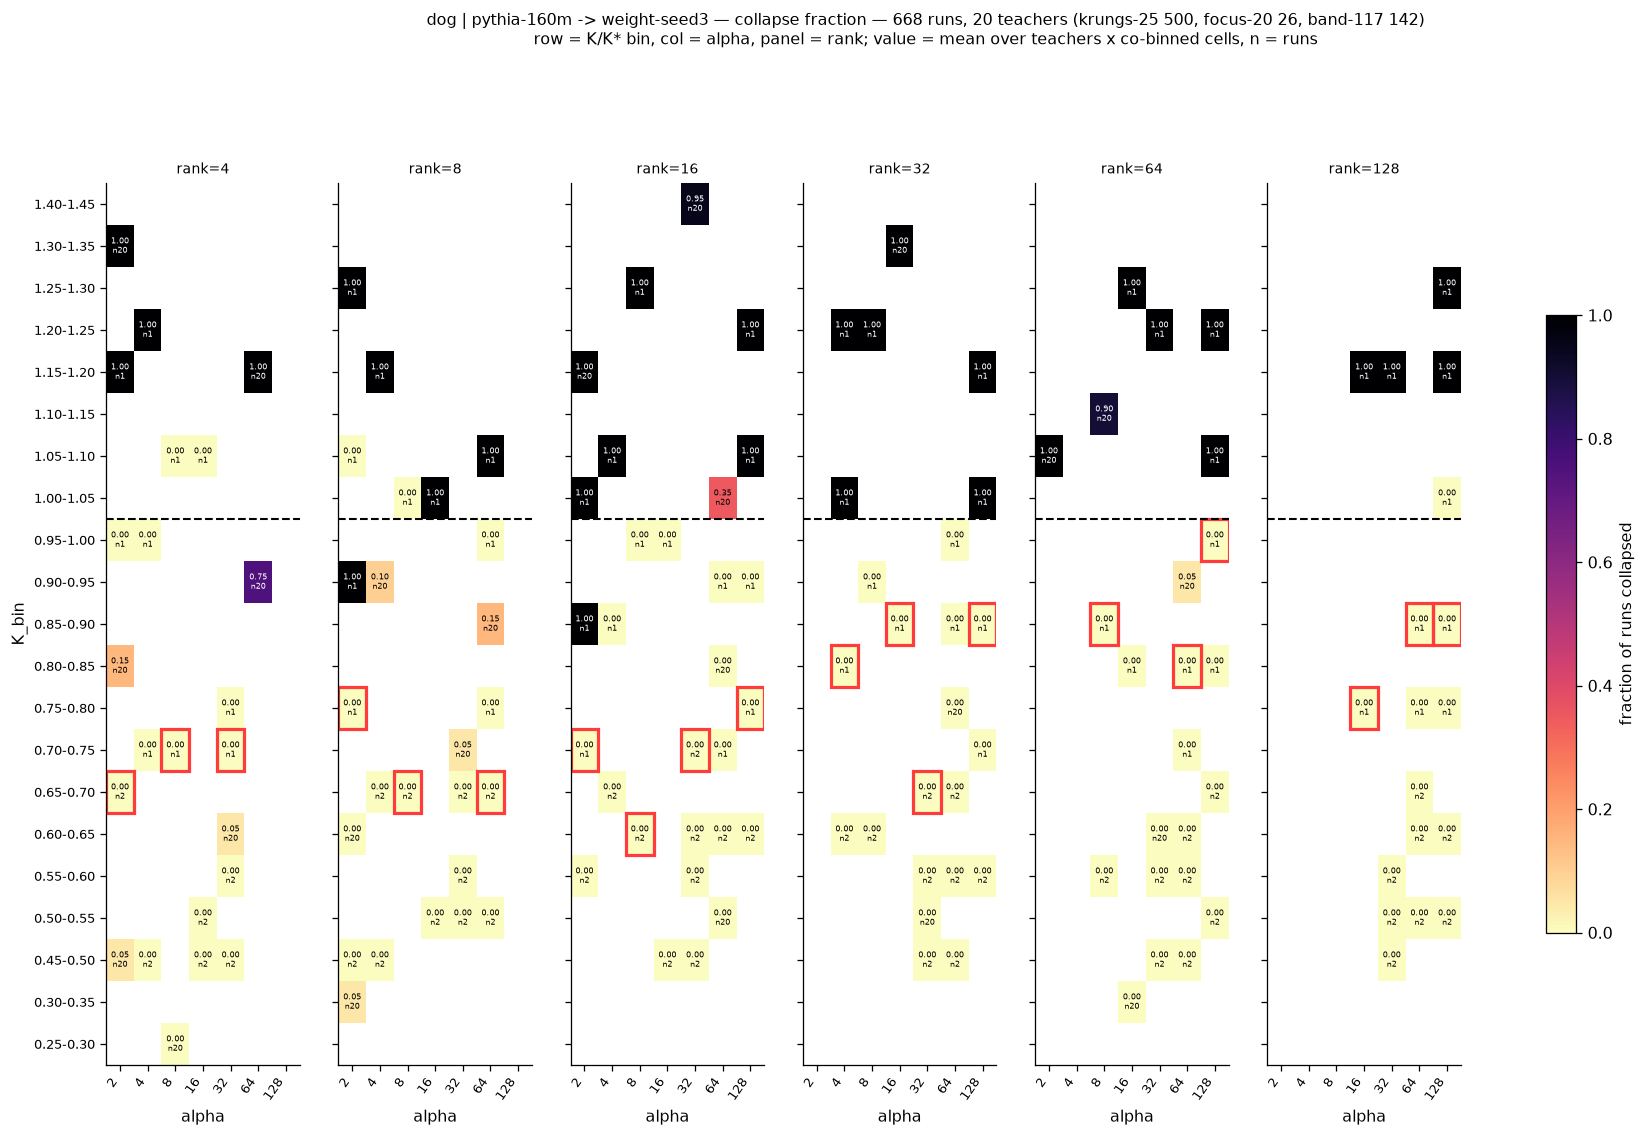

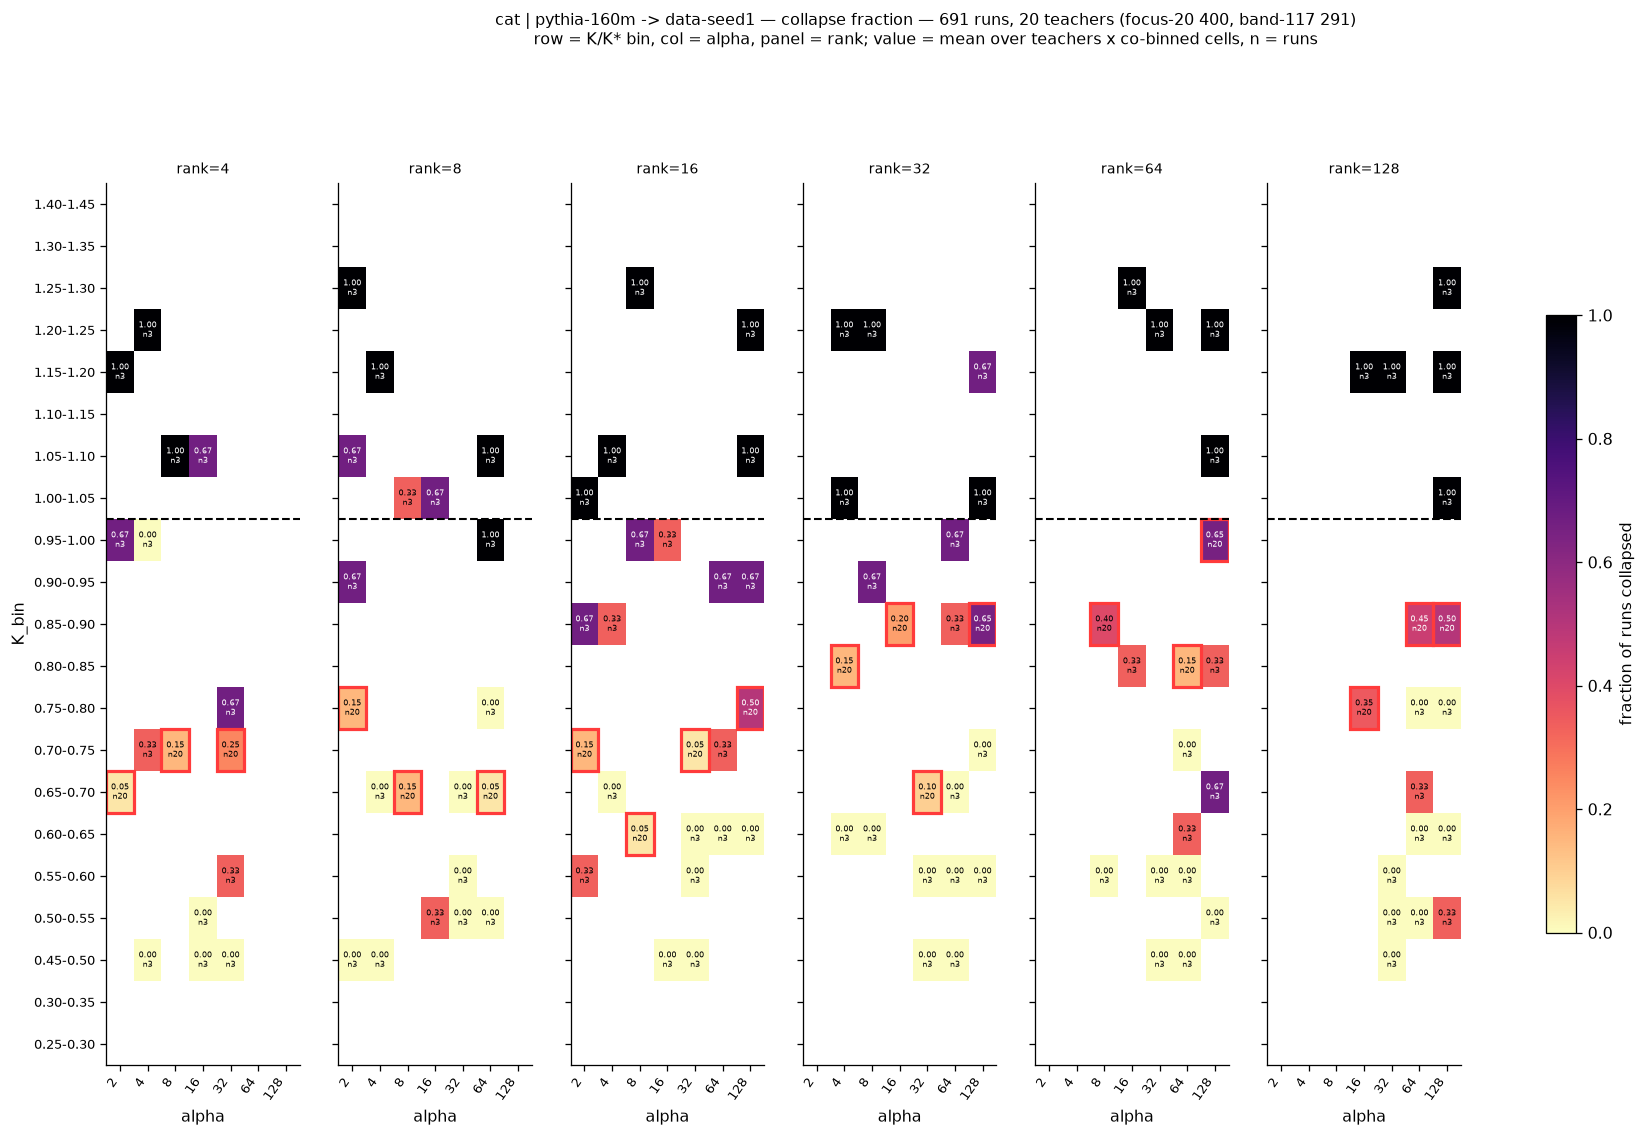

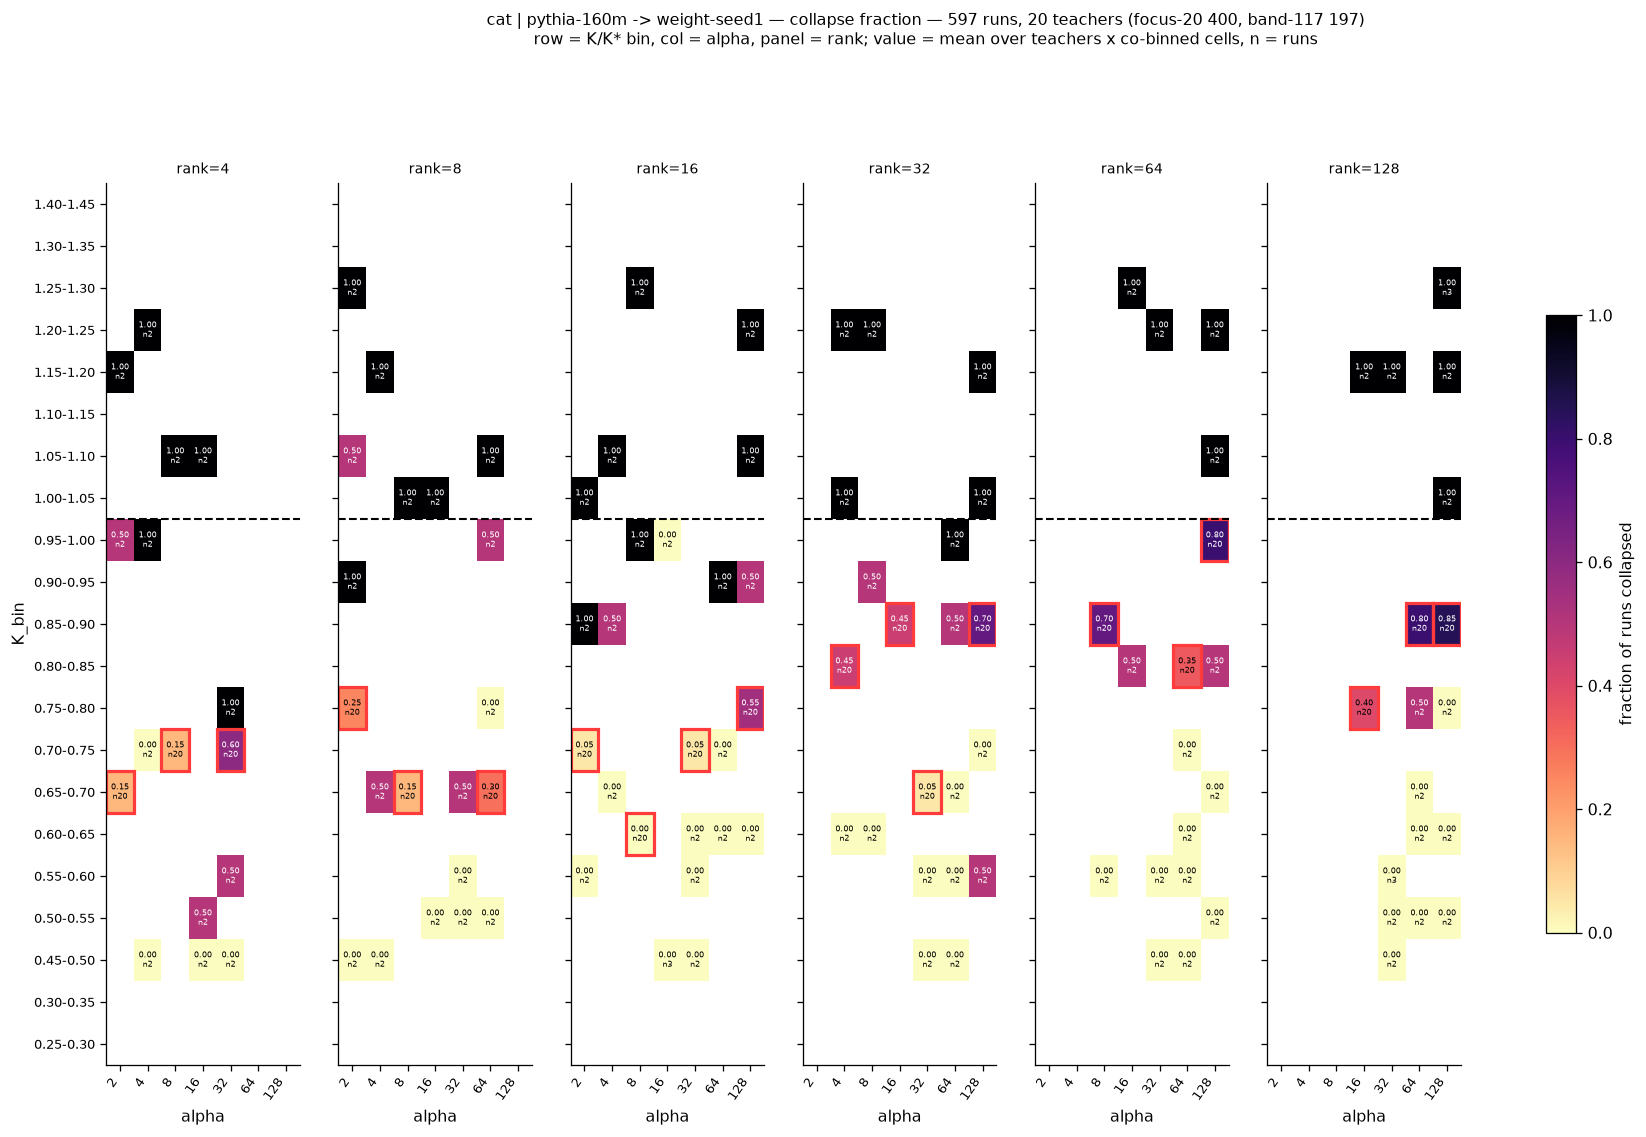

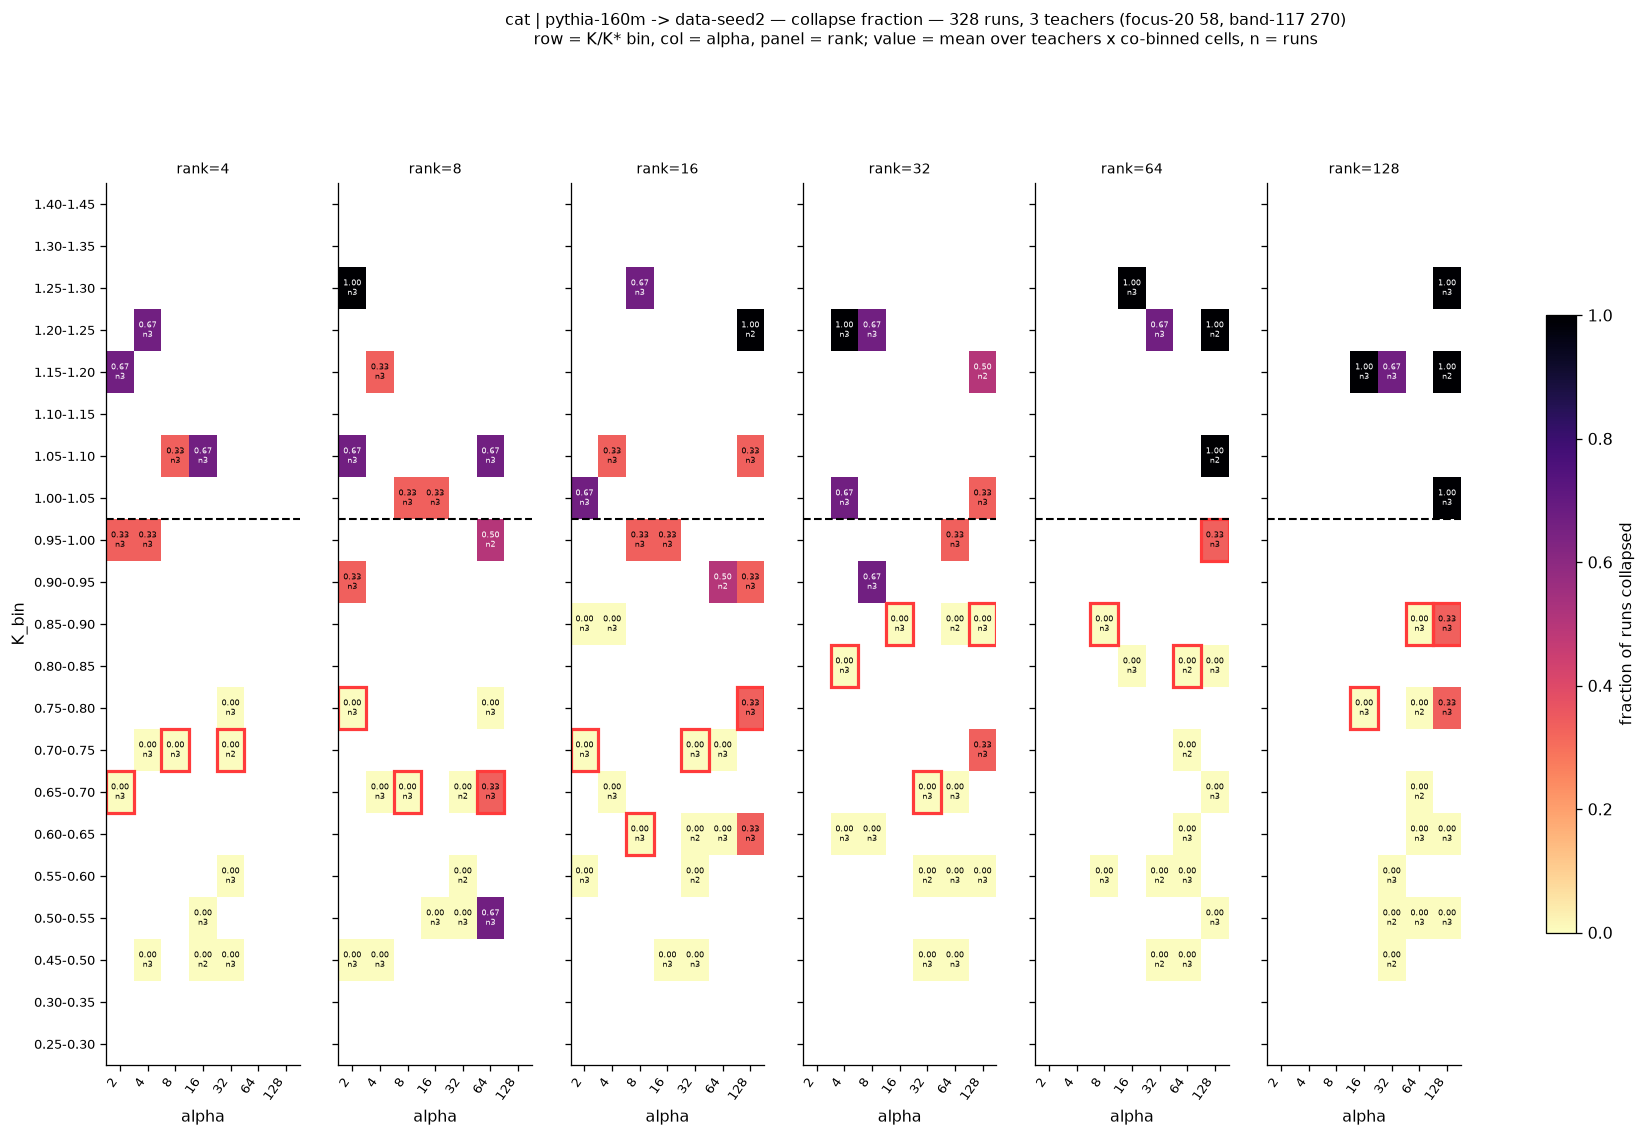

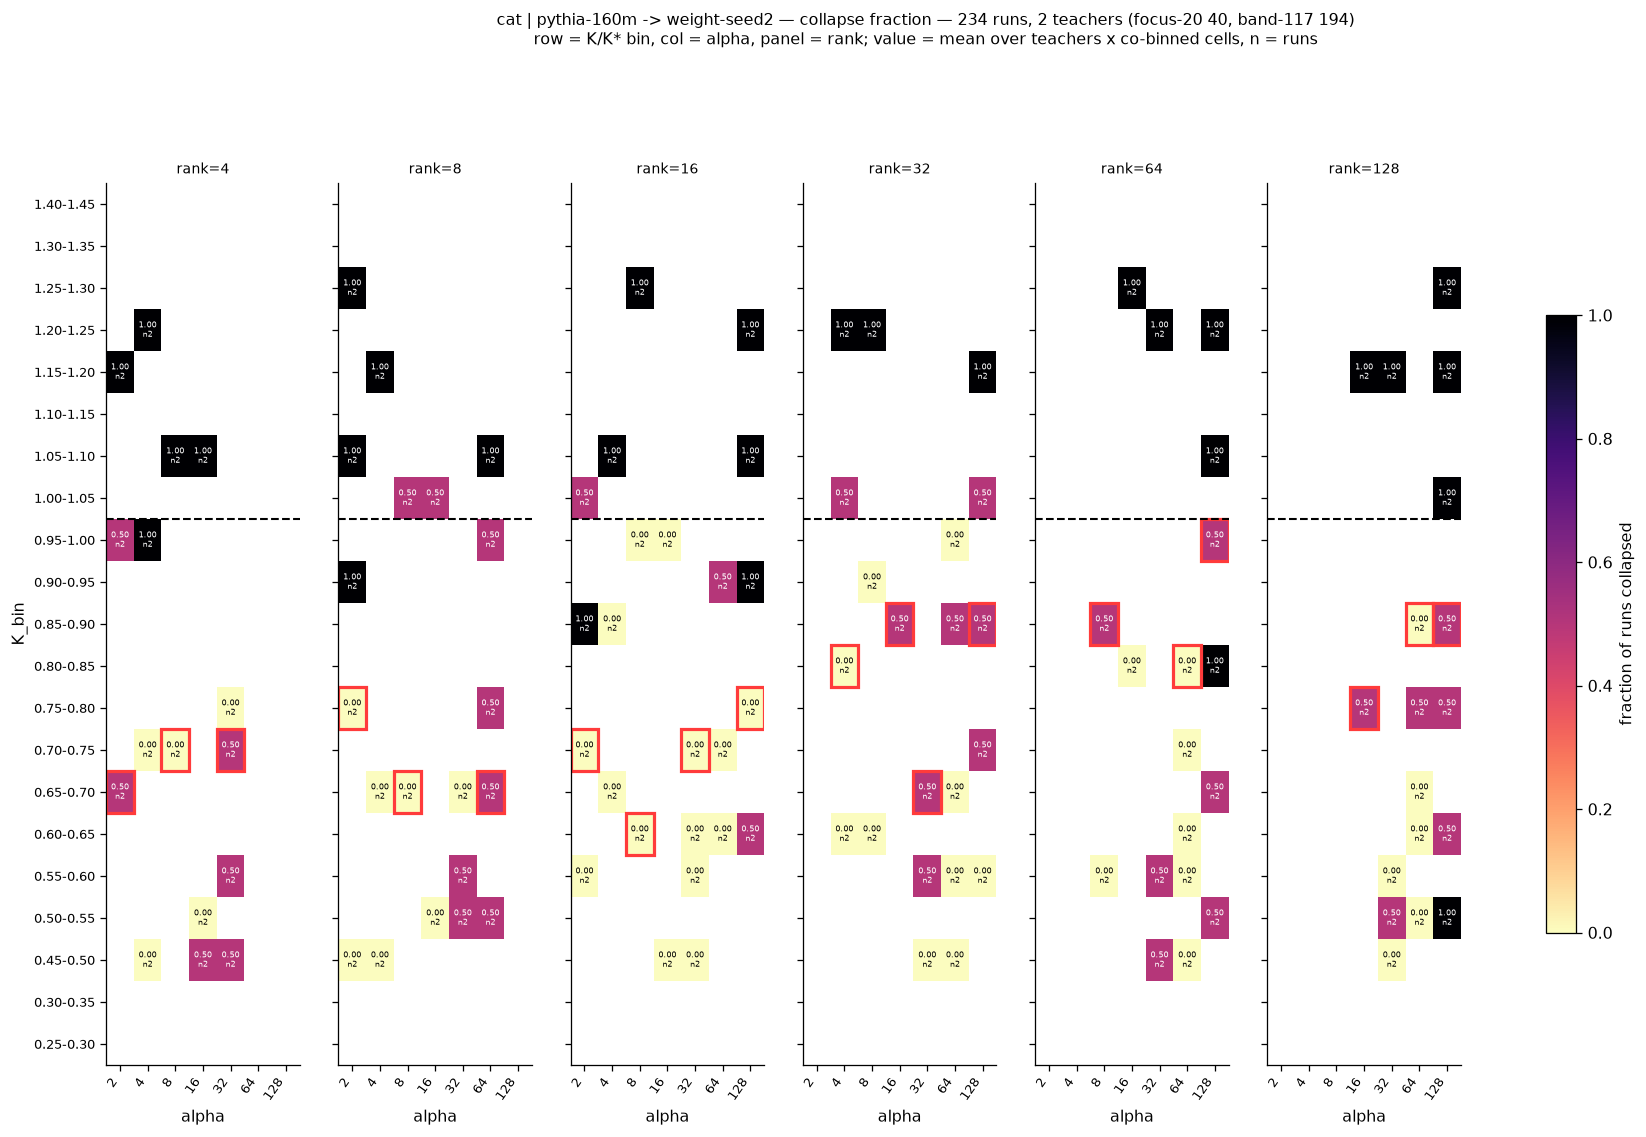

In [12]:
for lin in LINEAGES:
    sub = runs[runs.lineage.eq(lin)]
    if len(sub) < 100:
        continue
    arm_grid(sub, lin, val="dead", vmax=1.0, cmap="magma_r", fmt="{:.2f}",
             cbar="fraction of runs collapsed", note=" — collapse fraction")
    plt.show()

## 8. Balanced pool — the same grids on the 5 teachers every campaign ran

§6's squares average different teacher pools depending on which campaign placed the cell
(`band-117` ran only the top 5; the other two ran all 20), so part of any colour difference
between a band square and a krungs square is teacher composition, not $K$. Restricting to the
**top-5 teachers, which all three campaigns share**, removes that confound at the cost of 4× less
data. Same axes, same scale; row unit is now `top-5 teacher × design-cell`.

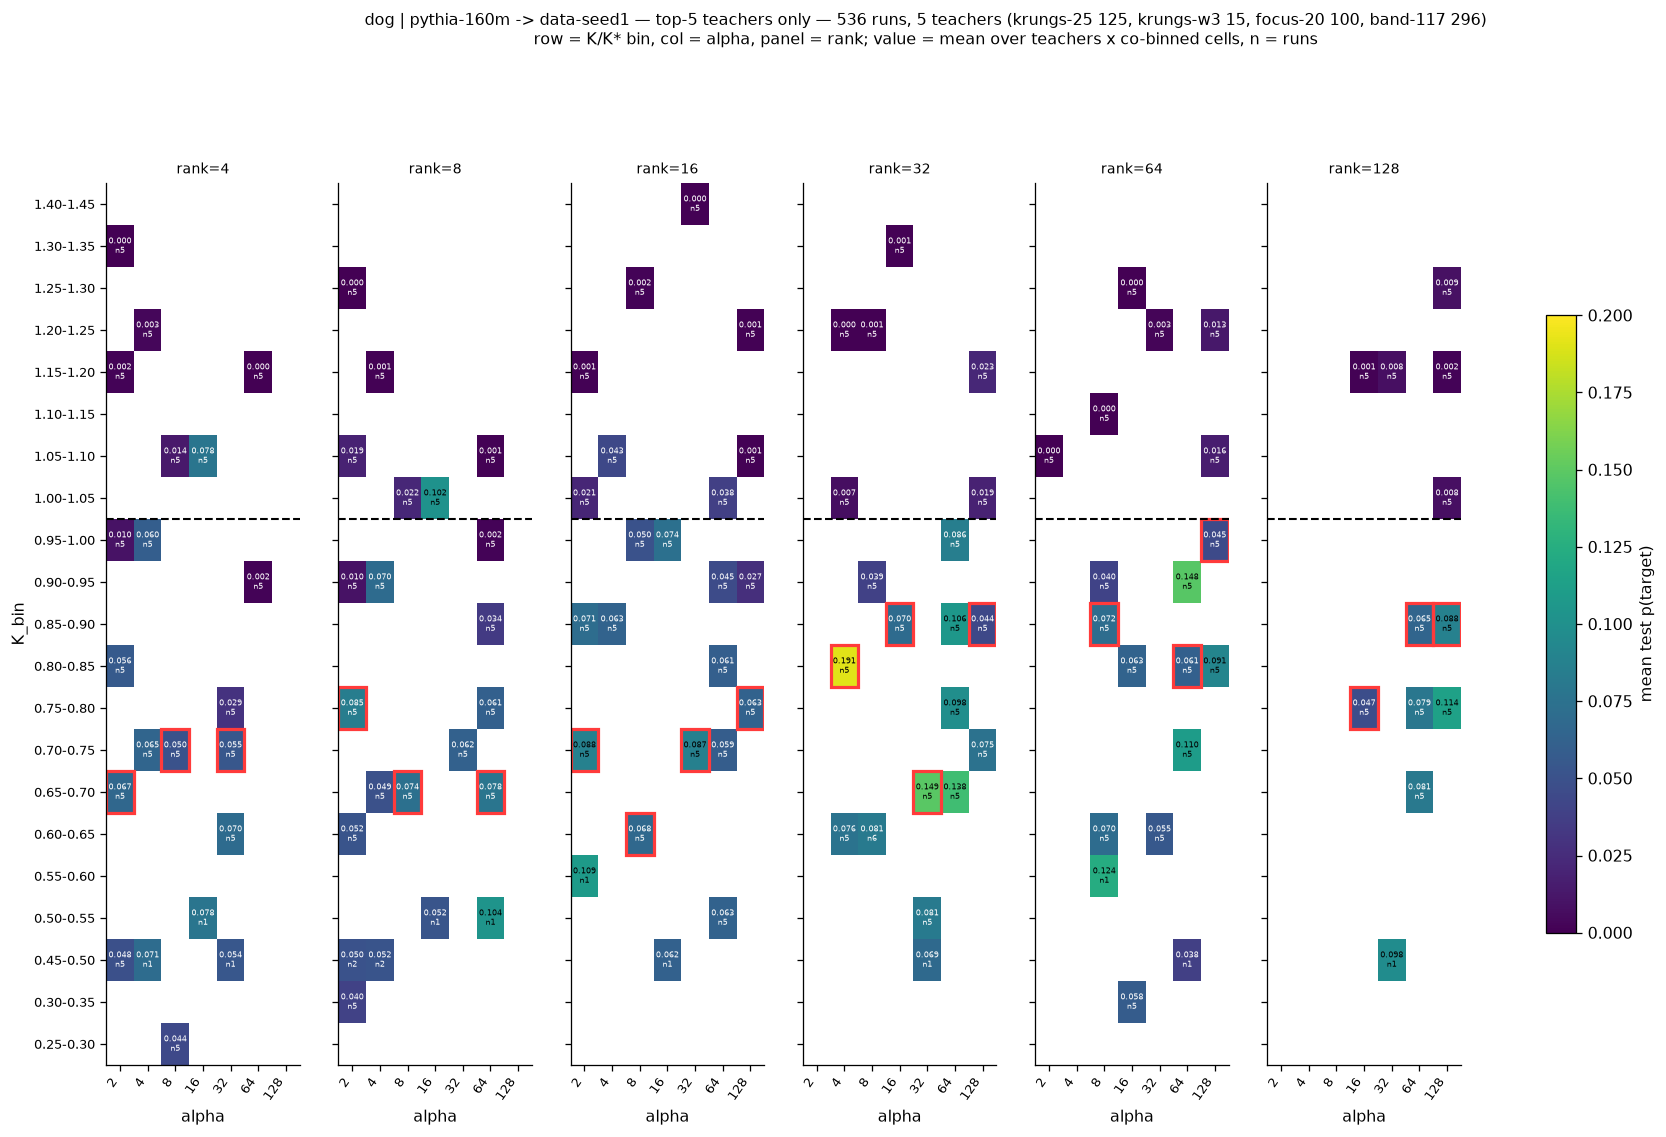

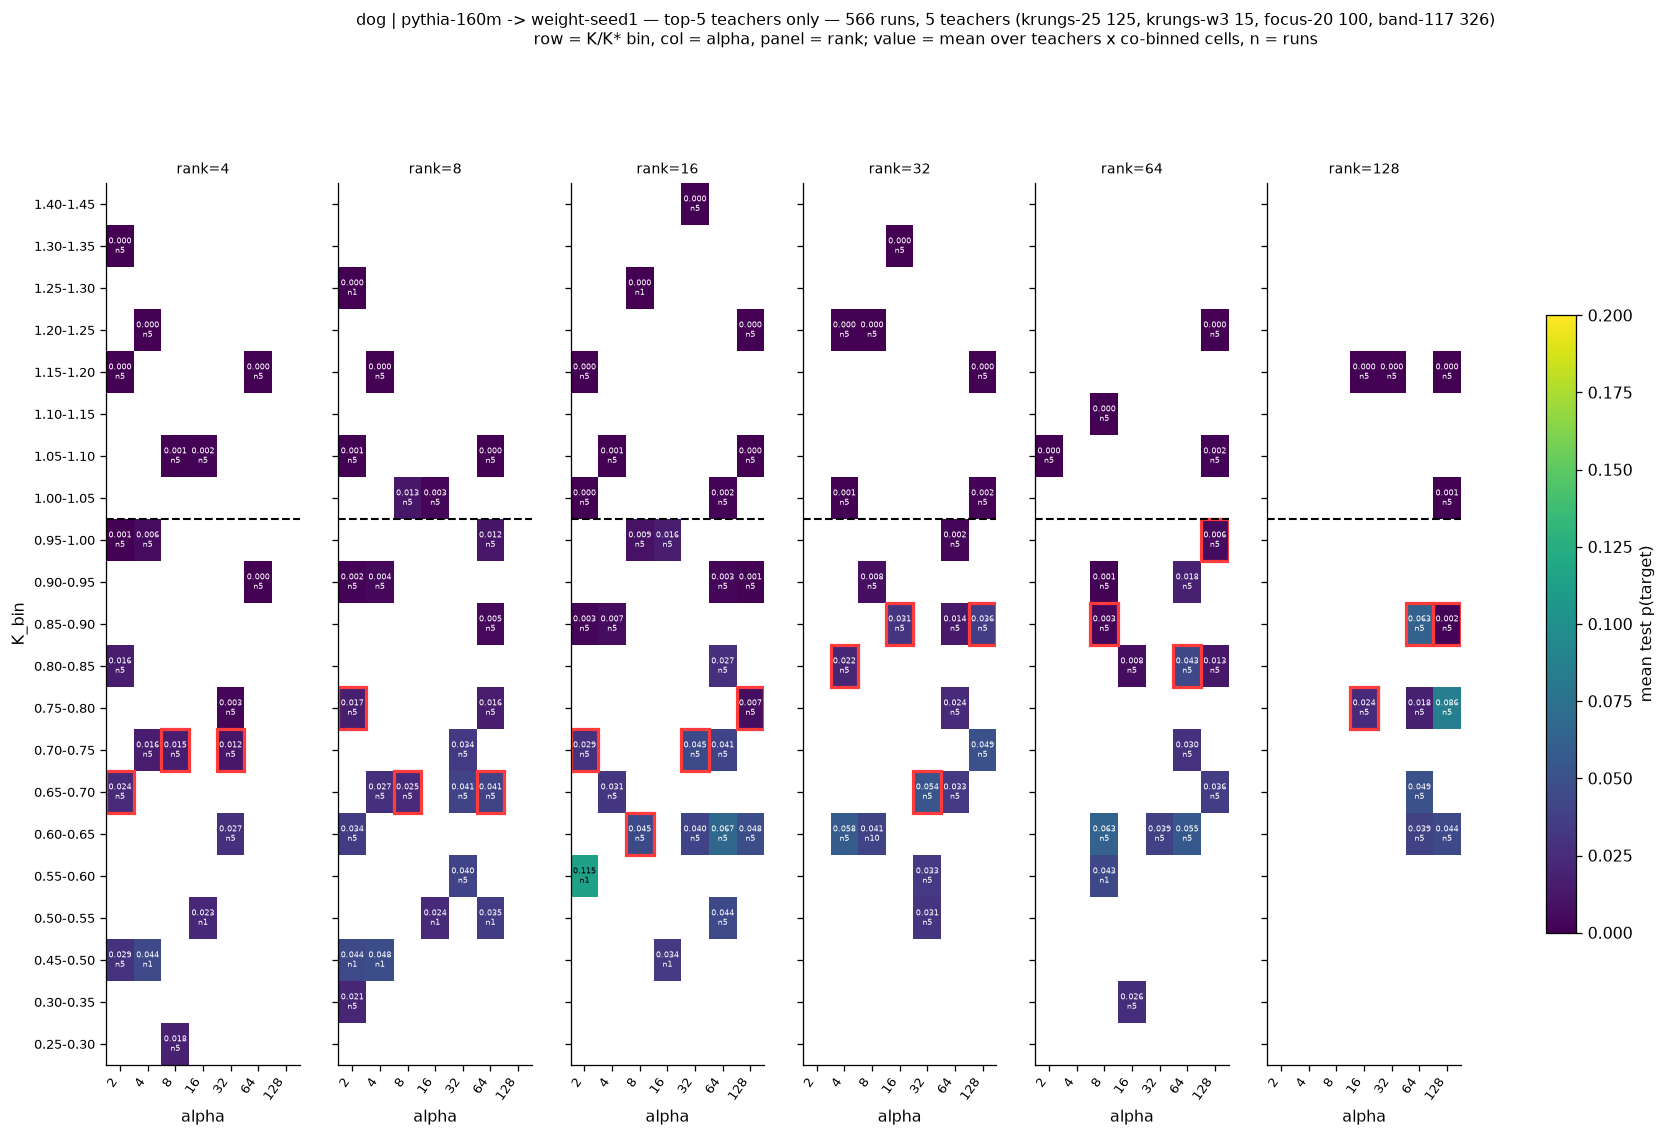

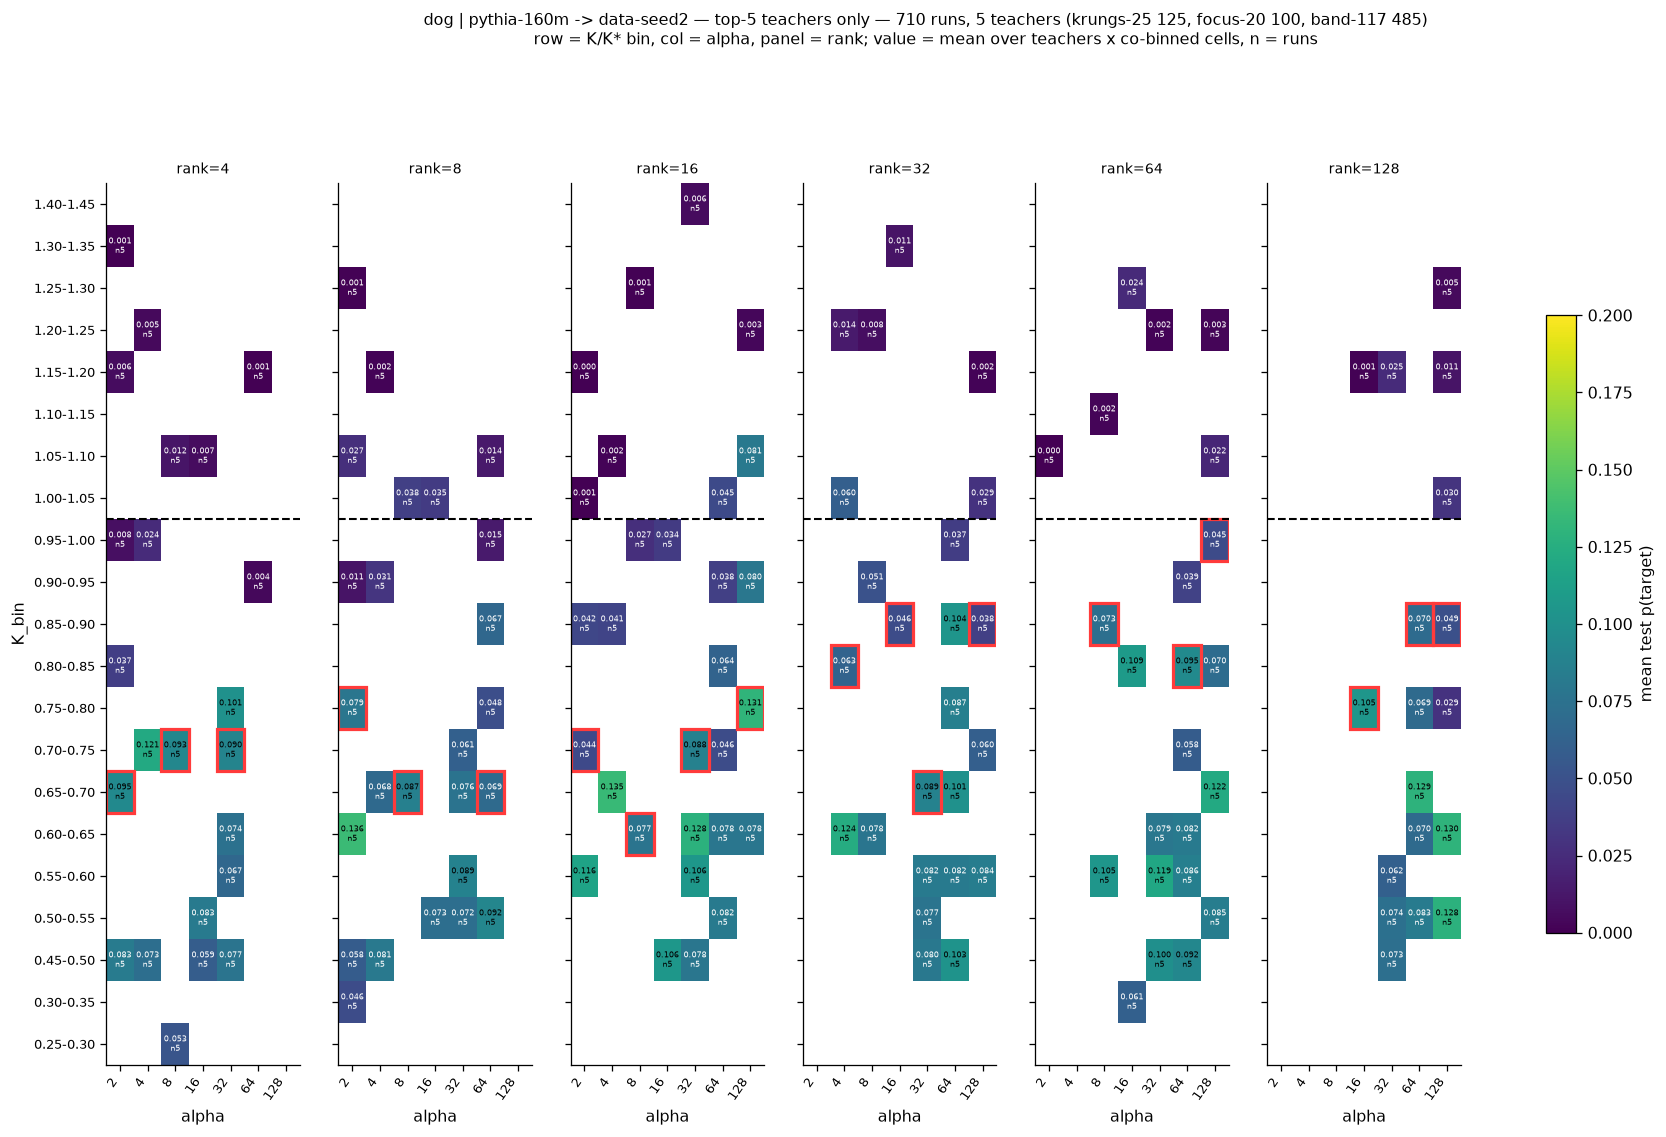

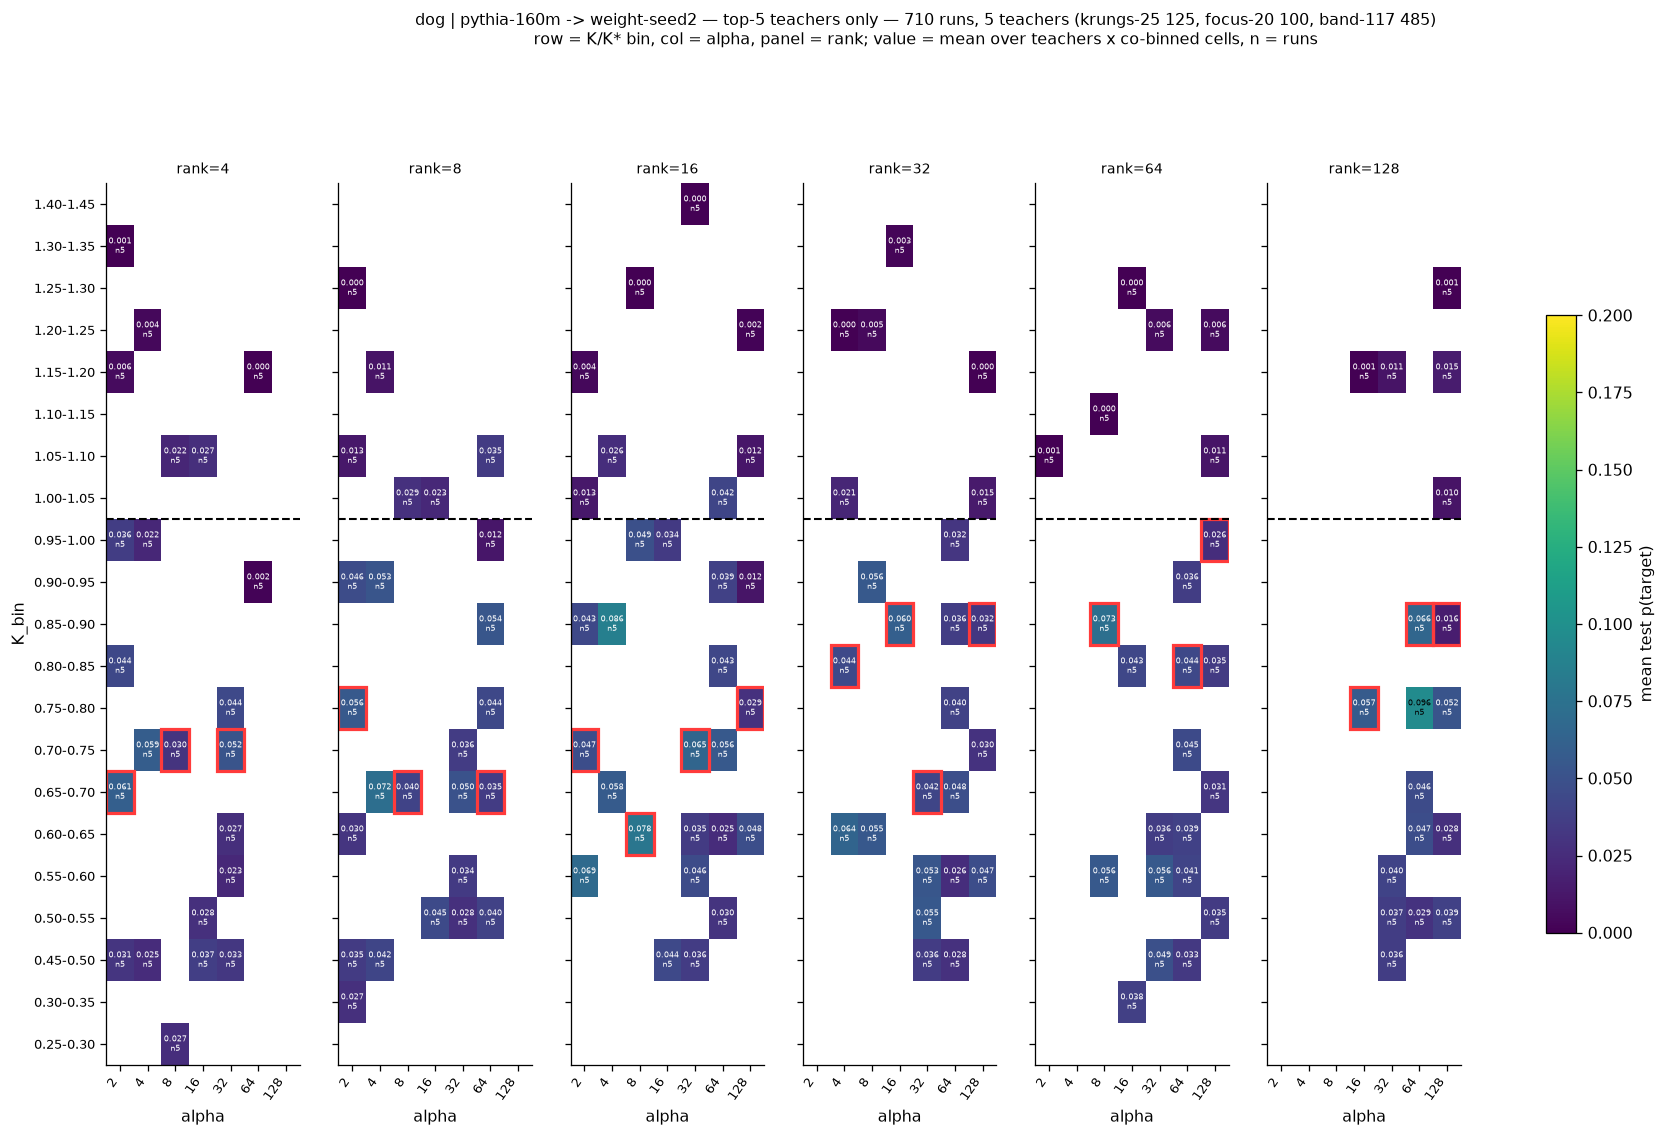

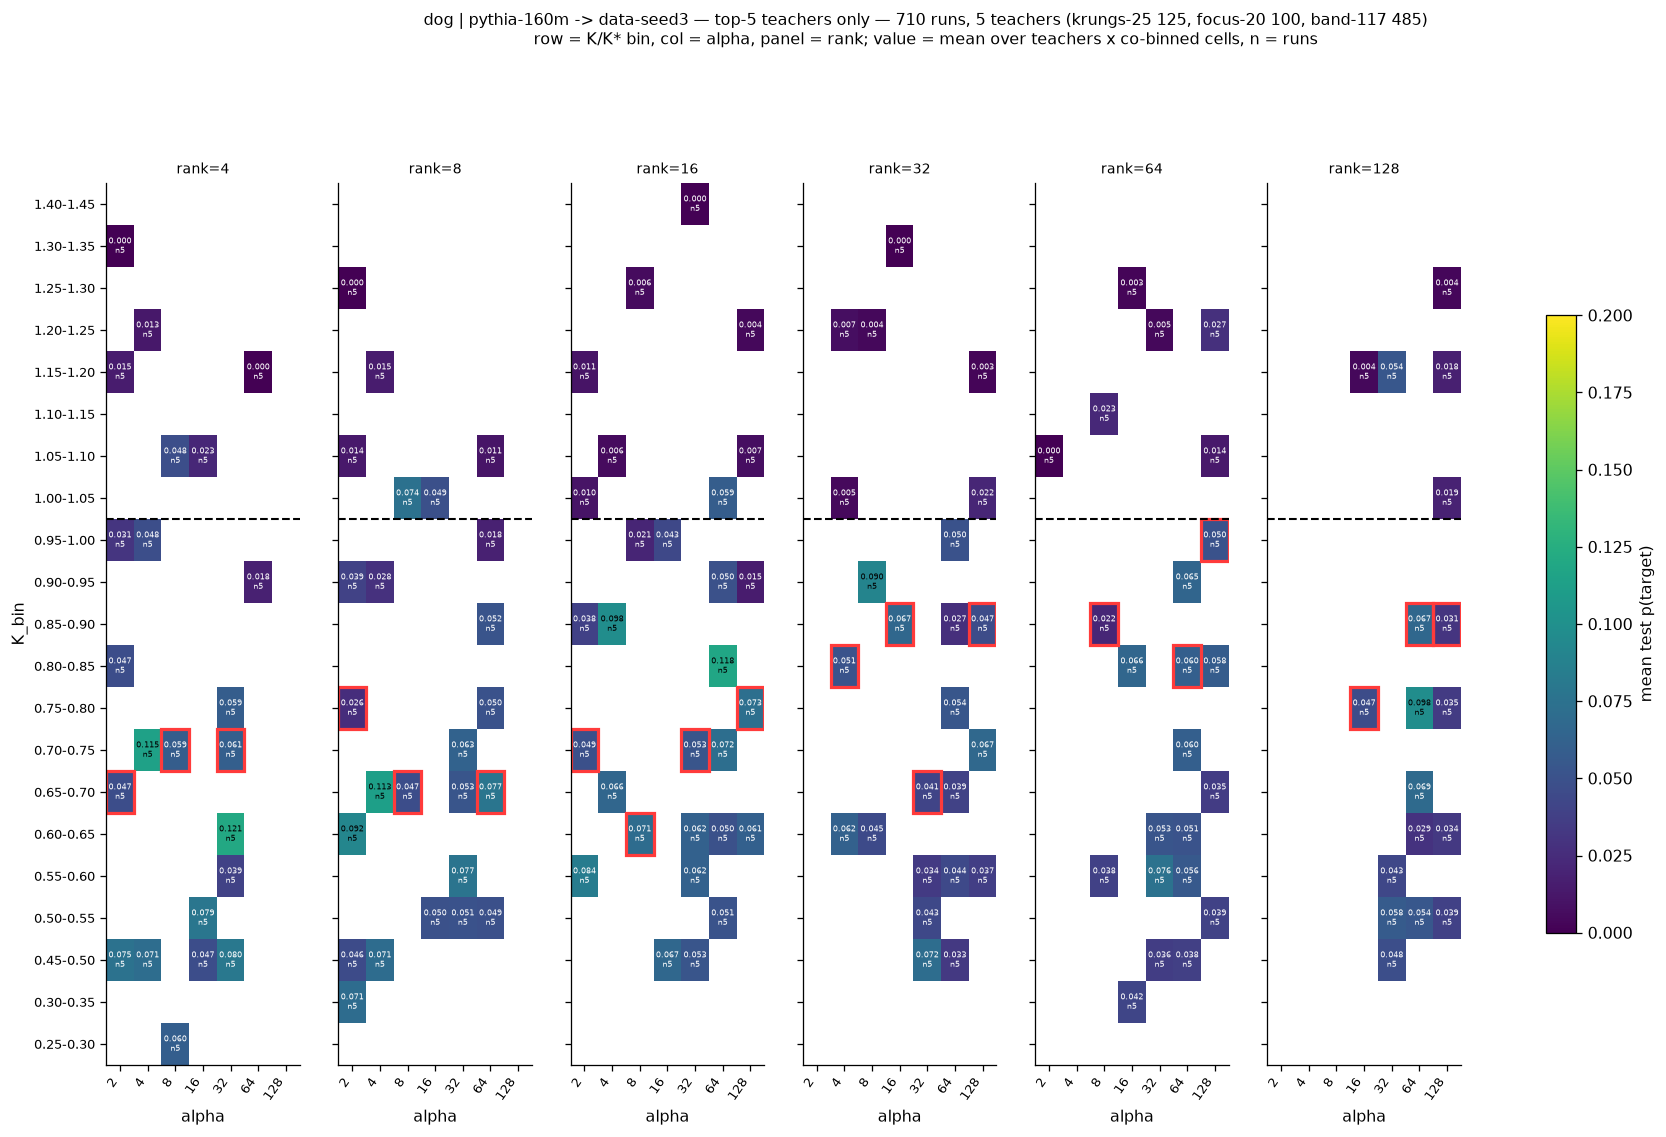

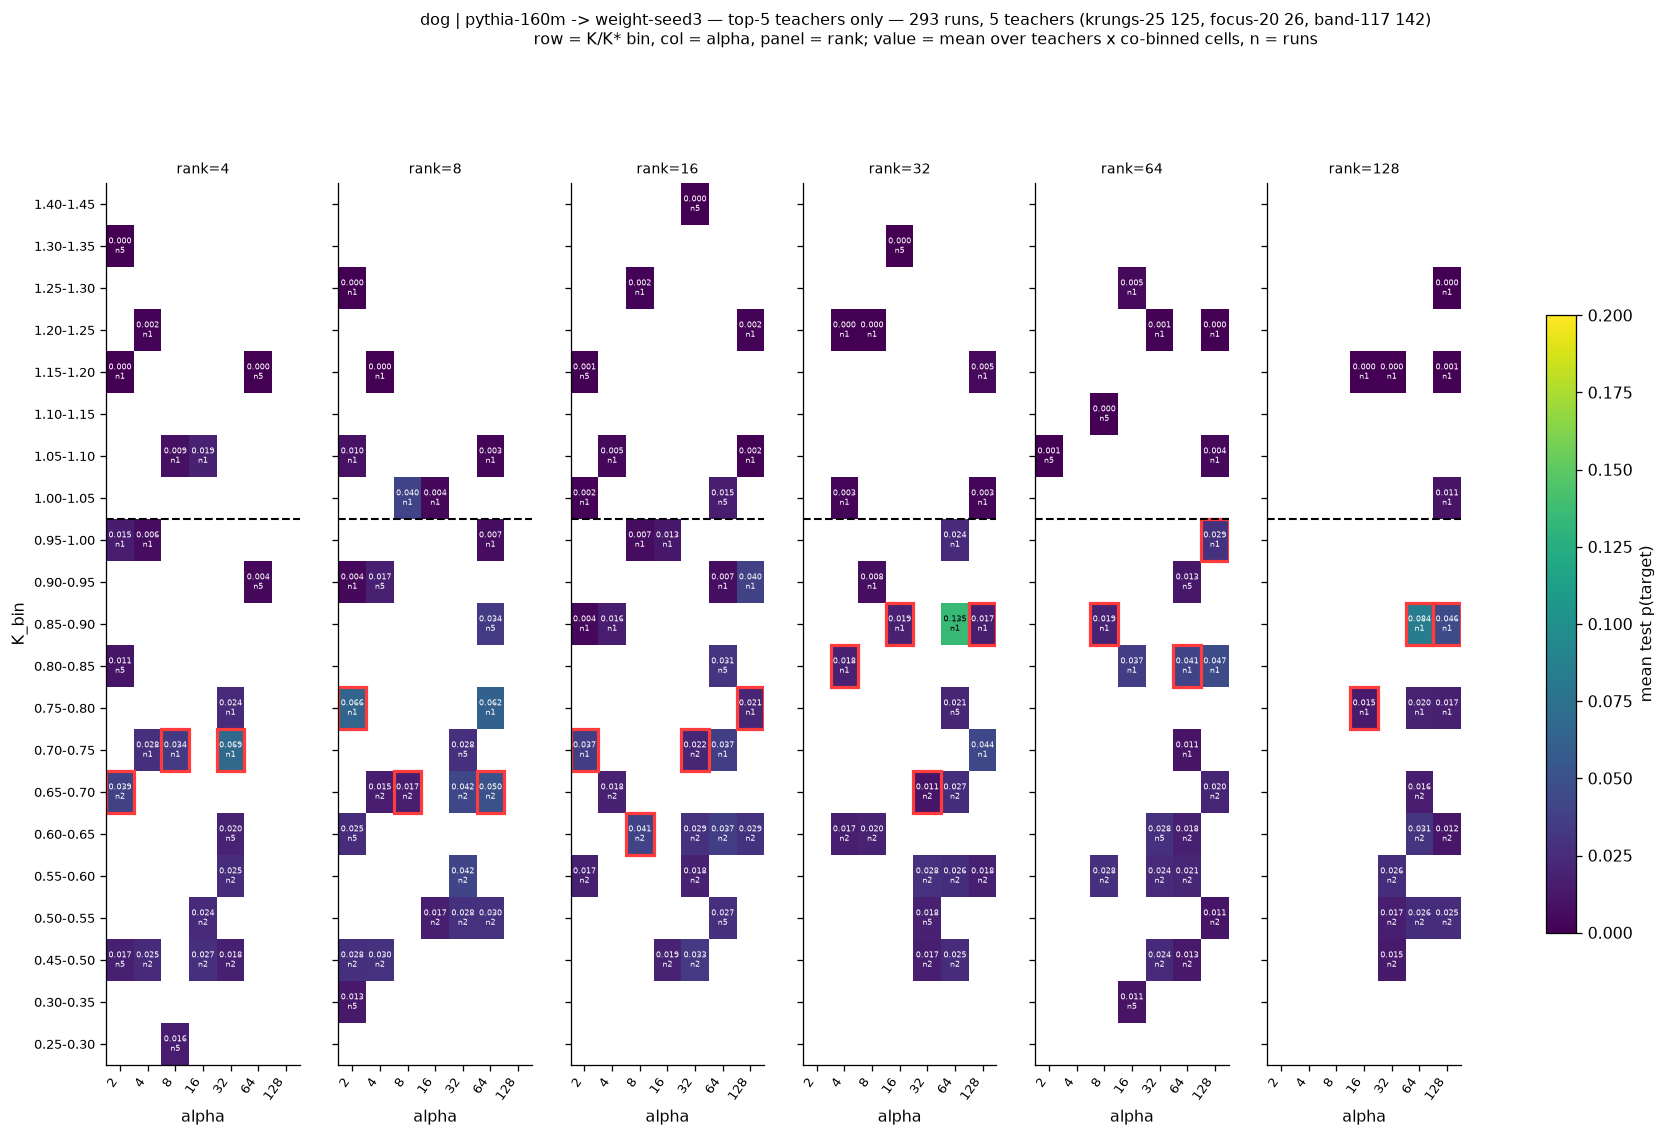

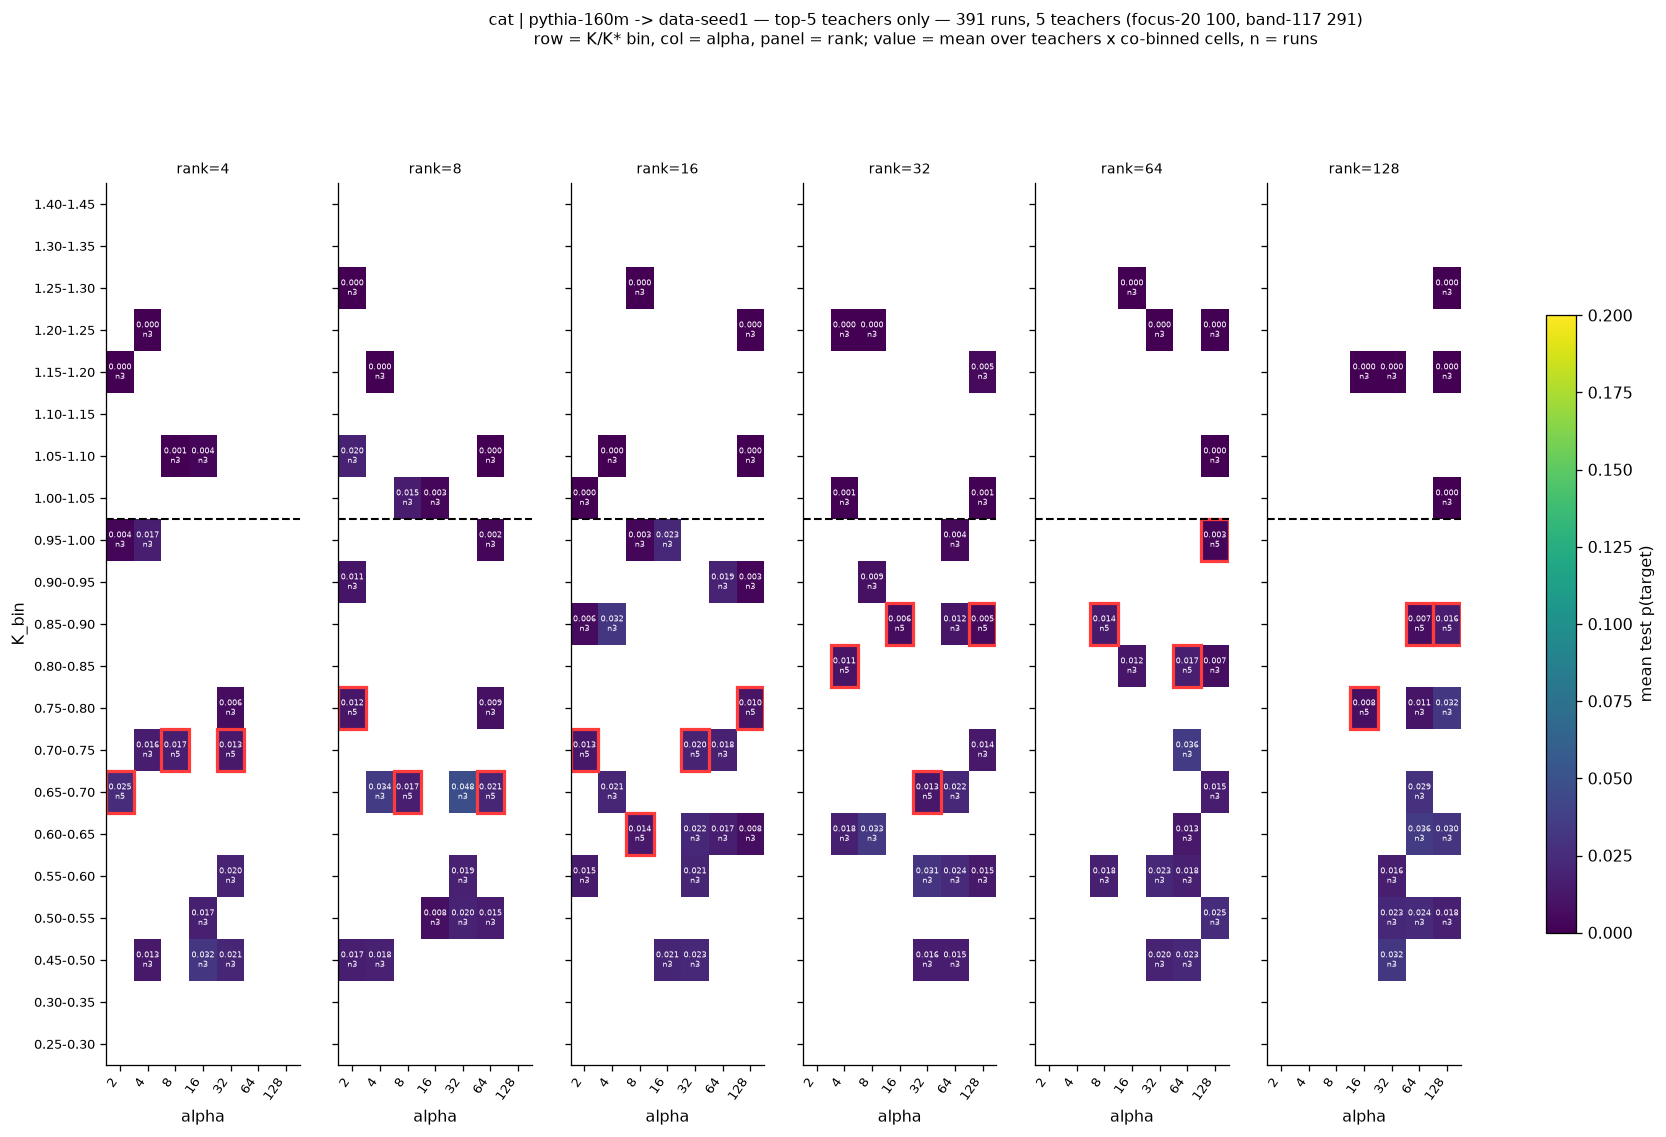

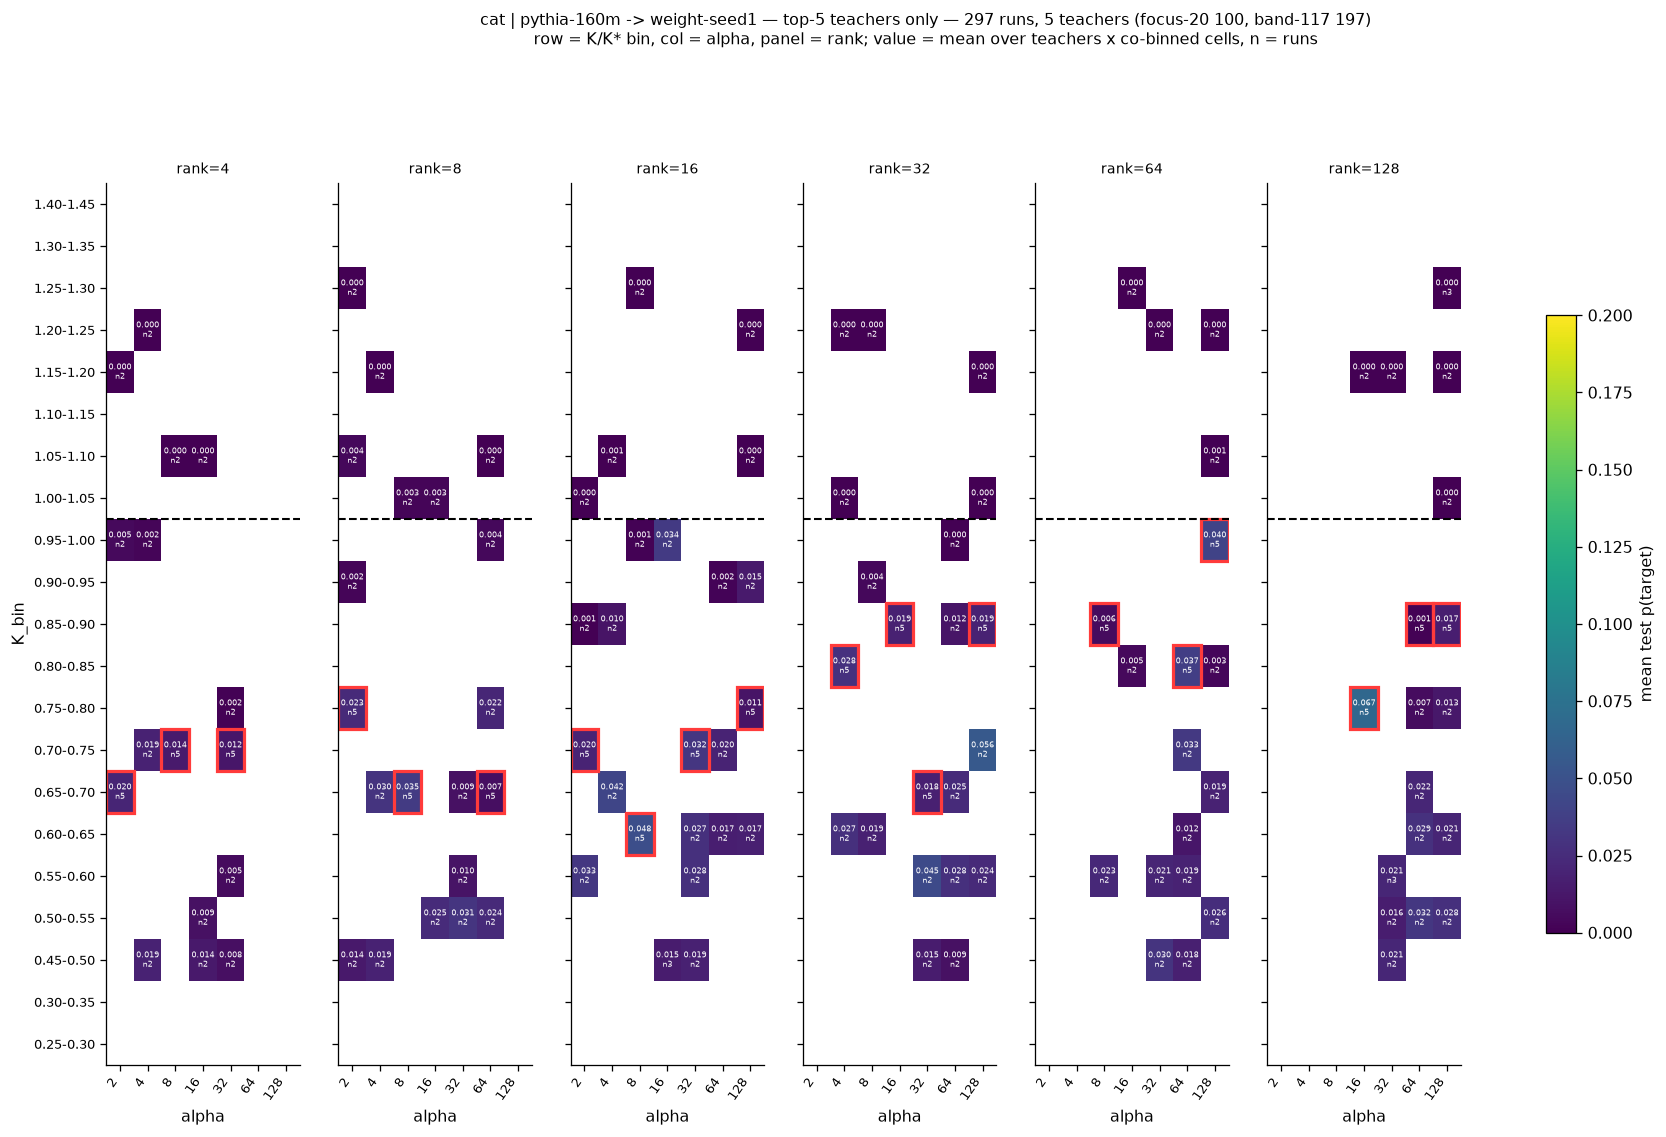

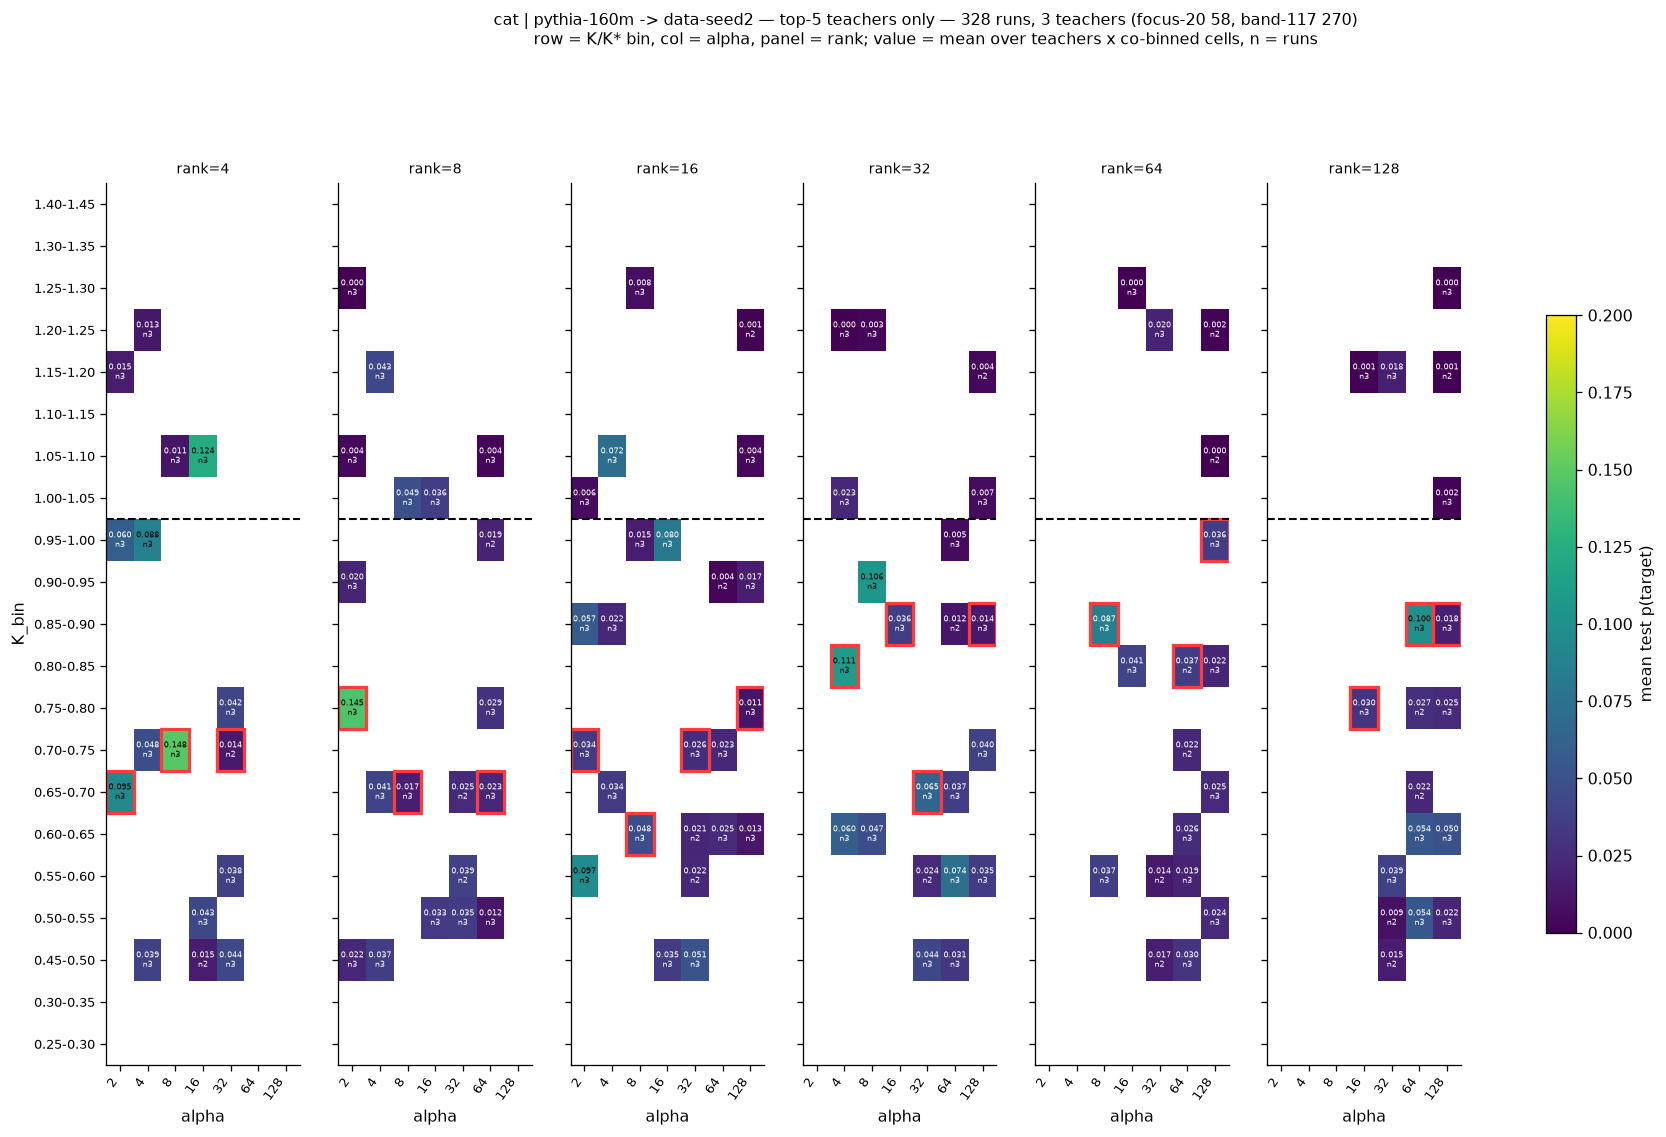

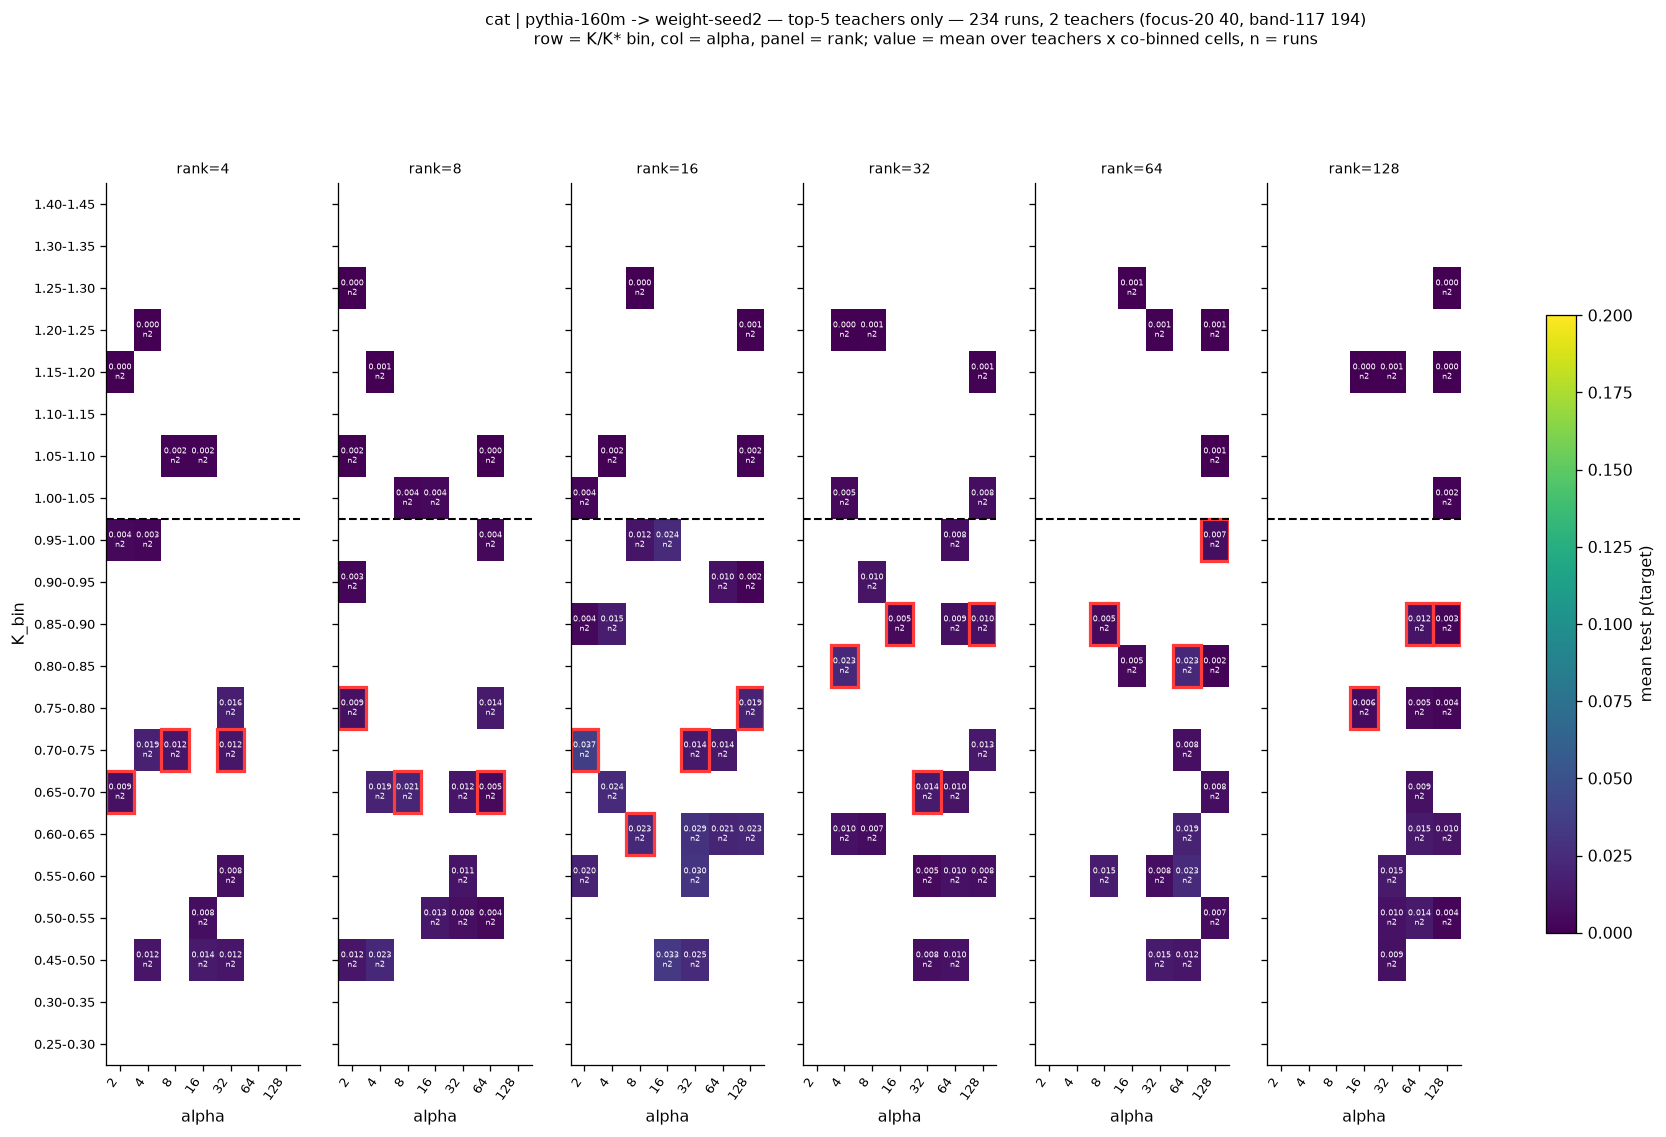

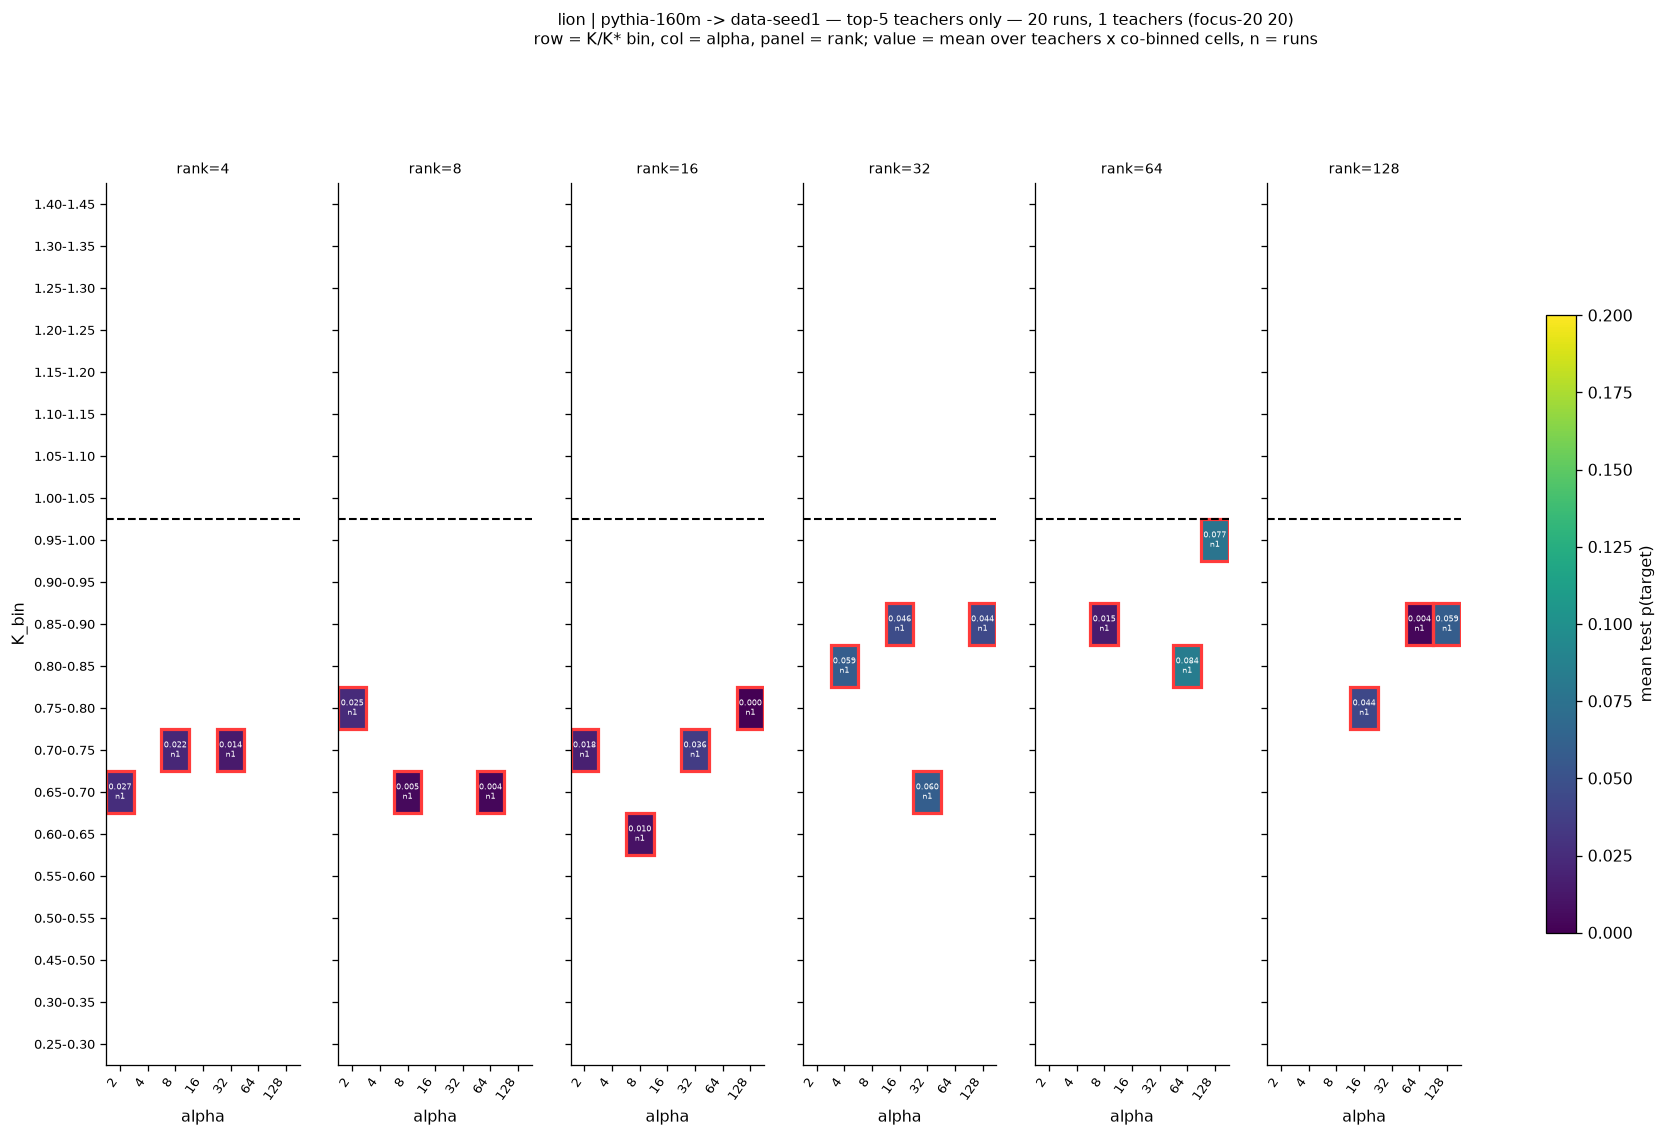

In [13]:
bal = runs[runs.tier.eq("top5")]
for lin in LINEAGES:
    sub = bal[bal.lineage.eq(lin)]
    if too_sparse(sub):
        continue
    arm_grid(sub, lin, note=" — top-5 teachers only")
    plt.show()

## 9. All lineages on one axis — the marginal $K/K^\ast$ response

The grids answer "does the boundary sit at the same height whatever $(\alpha, r)$ got you there".
This collapses each grid to its y-marginal so the arms can be compared directly. Row unit of each
point: all runs of that lineage in that $K/K^\ast$ bin (teachers and cells averaged); the left
panel plots mean test $p$, the right panel the collapsed fraction. Points with fewer than 5 runs
are drawn hollow — they are single cells, not a bin average.

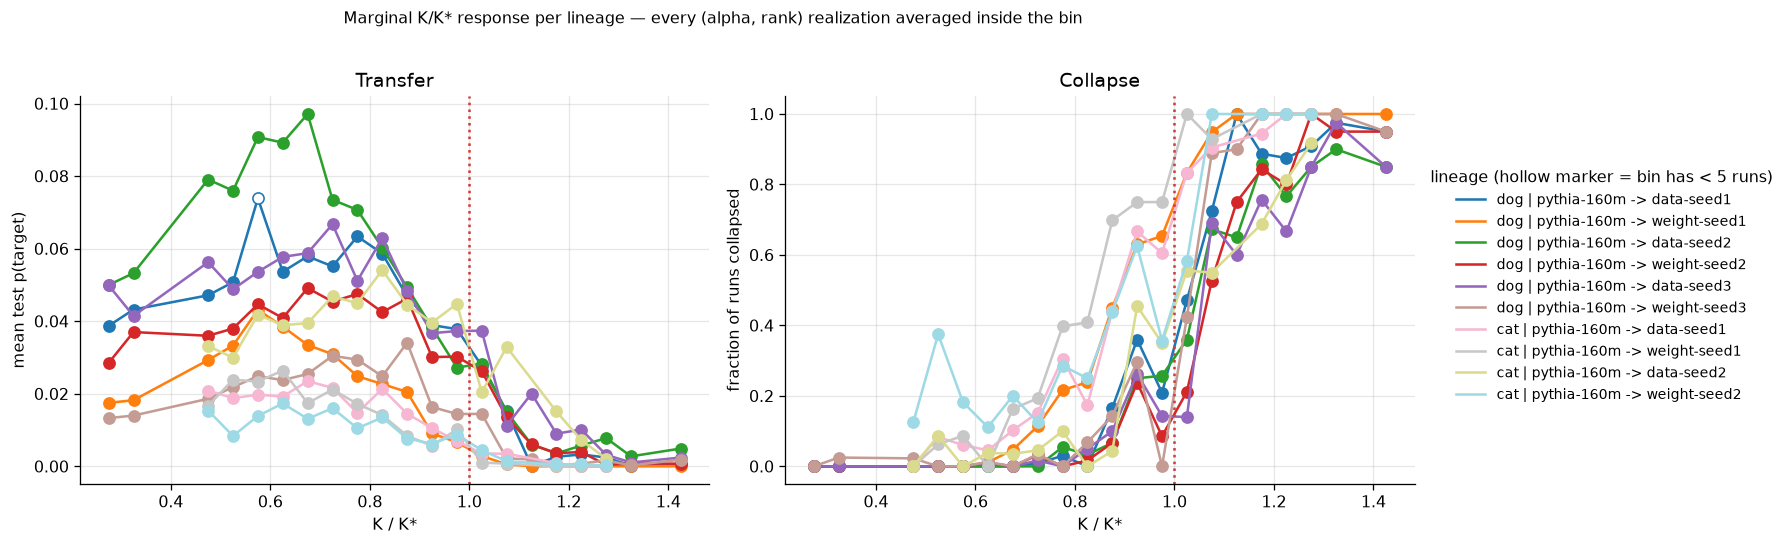

In [14]:
prof = (runs.groupby(["lineage", "K_bin"], observed=True)
        .agg(p=("test", "mean"), dead=("dead", "mean"), n=("test", "size")).reset_index())
prof["x"] = prof.K_bin.map(mid)
keep = [lin for lin in LINEAGES if len(runs[runs.lineage.eq(lin)]) >= 100]
colors = plt.get_cmap("tab20")(np.linspace(0, 1, max(len(keep), 2)))

fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.6))
handles = []
for (lin, c) in zip(keep, colors):
    g = prof[prof.lineage.eq(lin)].sort_values("x")
    for ax, col in zip(axs, ["p", "dead"]):
        big, small = g[g.n >= 5], g[g.n < 5]
        (ln,) = ax.plot(g.x, g[col], "-", color=c, lw=1.6, label=lin)
        ax.plot(big.x, big[col], "o", color=c, ms=7)
        ax.plot(small.x, small[col], "o", color=c, ms=7, mfc="white")
    handles.append(ln)
for ax, (ttl, ylab) in zip(axs, [("Transfer", "mean test p(target)"),
                                 ("Collapse", "fraction of runs collapsed")]):
    ax.axvline(1.0, color="#d03b3b", ls=":", lw=1.6)
    ax.set(xlabel="K / K*", ylabel=ylab, title=ttl,
           xticks=[0.4, 0.6, 0.8, 1.0, 1.2, 1.4])
fig.legend(handles, [h.get_label() for h in handles], loc="center left",
           bbox_to_anchor=(0.99, 0.5), frameon=False, fontsize=9,
           title="lineage (hollow marker = bin has < 5 runs)")
fig.suptitle("Marginal K/K* response per lineage — every (alpha, rank) realization averaged "
             "inside the bin", y=1.02, fontsize=10)
fig.tight_layout(); plt.show()

### Where each lineage's own boundary sits

Row unit: one lineage. `K_rel_last_live` is the highest $K/K^\ast$ bin whose collapse fraction is
still below 0.5, `K_rel_first_dead` the lowest bin at/above 0.5, and `boundary_K_rel` their
geometric midpoint — that arm's empirical boundary against a design value of exactly 1. The
anchor was fit on `dog -> data-seed1`, so that row is the sanity check and the others are the
transfer claim. `monotone=False` flags an arm whose collapse fraction crosses 0.5 more than once,
where the midpoint is indicative only.

In [15]:
rows = []
for lin in keep:
    g = prof[prof.lineage.eq(lin)].sort_values("x")
    live, dead_ = g[g.dead < 0.5], g[g.dead >= 0.5]
    lo = live.x.max() if len(live) else np.nan
    hi = dead_.x.min() if len(dead_) else np.nan
    mid_b = float(np.sqrt(lo * hi)) if np.isfinite(lo) and np.isfinite(hi) else np.nan
    rows.append({"lineage": lin, "bins": len(g), "runs": int(g.n.sum()),
                 "K_rel_last_live": lo, "K_rel_first_dead": hi,
                 "boundary_K_rel": mid_b, "monotone": bool(lo < hi)})
display(pd.DataFrame(rows).set_index("lineage").round(3))
print("design boundary = 1.00 by construction; a row with monotone=False has a collapsed bin "
      "below a live one, so its midpoint is only indicative.")

,bins,runs,K_rel_last_live,K_rel_first_dead,boundary_K_rel,monotone
lineage,,,,,,
dog | pythia-160m -> data-seed1,21,1315,1.025,1.075,1.05,True
dog | pythia-160m -> weight-seed1,21,1307,0.875,0.925,0.90,True
dog | pythia-160m -> data-seed2,21,1085,1.025,1.075,1.05,True
dog | pythia-160m -> weight-seed2,21,1093,1.025,1.075,1.05,True
dog | pythia-160m -> data-seed3,21,1085,1.025,1.075,1.05,True
dog | pythia-160m -> weight-seed3,21,668,1.025,1.075,1.05,True
cat | pythia-160m -> data-seed1,16,691,0.875,0.925,0.90,True
cat | pythia-160m -> weight-seed1,16,597,0.825,0.875,0.85,True
cat | pythia-160m -> data-seed2,16,328,0.975,1.025,1.00,True


design boundary = 1.00 by construction; a row with monotone=False has a collapsed bin below a live one, so its midpoint is only indicative.


---

**Reconstruction note (2026-08-05).** This notebook replaces the merged-campaign view lost in the
node-1 rebuild. It is rebuilt from the surviving campaign records — the frozen `krungs-25` waves
in `top20_krungs_ds1.ipynb`, the `top5-bandext-ds2ws2` job list, `run_logs/focus20_cells.json`,
the teacher manifests, and the student output tree — not from the original notebook, so section
numbering and wording differ from the lost one even where the figures agree.